# Supply Chain Demand Forecasting & Inventory Optimization

**End-to-End Data Analytics, Machine Learning & Business Intelligence**

## Ergebnisse auf einen Blick

| Bereich | Ergebnis |
|---|---|
| **Daten** | 59,2 Mio. Beobachtungen (3.049 Artikel, 10 Filialen, 1.941 Tage), vollständig validiert |
| **Data Warehouse** | Star Schema in PostgreSQL (1 Faktentabelle, 3 Dimensionstabellen) |
| **Prognose** | Gradient Boosting senkt den MAE gegenüber dem saisonalen Baseline-Modell um 12,9 % (RMSE: −9,2 %) |
| **ABC-Analyse** | 43,2 % der Artikel erzeugen 80 % des Umsatzes; FOODS stellt mehr als die Hälfte der A-Artikel |
| **Bestandsplanung** | Planung je Kategorie erfordert 19,8 % mehr Sicherheitsbestand als die aggregierte Planung (Risk Pooling) |
| **Optimierung** | Kostenoptimaler Servicelevel von 98,1–99,1 % statt pauschal 95 %; rund 26 % geringere Kosten für Sicherheitsbestand und Fehlmengen |
| **Reporting** | Excel-Dashboard für Fachanwender |

**Wichtigste Erkenntnisse:**

- Absatz und Umsatz steigen zwischen 2011 und 2016; die Sommermonate (v. a. August) sind am stärksten.
- FOODS erzeugt rund 58 % des Umsatzes.
- 68 % der Beobachtungen haben keinen Absatz; ein Teil davon entfällt auf nicht gelistete Artikel.
- Die Prognosegüte nimmt mit längerem Horizont ab (Mai 2016).
- Die Optimierungsergebnisse beruhen auf transparent dokumentierten Kostenannahmen.

## 1. Business Understanding

### 1.1 Geschäftskontext

Eine effiziente Supply Chain ist ein entscheidender Erfolgsfaktor im Einzelhandel. Unternehmen stehen vor der Herausforderung, die Kundennachfrage möglichst genau vorherzusagen und gleichzeitig ihre Lagerbestände und Logistikkosten zu optimieren.

Ungenaue Absatzprognosen können zu Überbeständen, Warenengpässen, erhöhten Lagerhaltungskosten und Umsatzverlusten führen.

### 1.2 Geschäftsziele

- Verbesserung der Prognosegenauigkeit
- Optimierung der Lagerbestände
- Reduzierung von Lagerhaltungskosten
- Minimierung von Lieferengpässen
- Identifikation saisonaler Nachfragemuster
- Vergleich statistischer Prognoseverfahren und
  Machine-Learning-Modelle
- Entwicklung datenbasierter Handlungsempfehlungen
- Unterstützung strategischer Geschäftsentscheidungen

### 1.3 Datengrundlage

Als Datengrundlage dient der M5 Forecasting Accuracy Datensatz, der historische Verkaufsdaten des US-amerikanischen Einzelhandelsunternehmens Walmart enthält.

Die Analyse basiert auf drei Datenquellen:

- Historische Absatzdaten
- Kalender-, Feiertags- und Ereignisdaten
- Historische Verkaufspreise

Nicht vorhandene Bestands- und Logistikparameter werden für die Bestandsoptimierung anhand transparenter Simulationsannahmen ergänzt.

In [2]:
# Import der erforderlichen Bibliotheken

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Konfiguration der Datendarstellung

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

# Überprüfung des Projektverzeichnisses

print("Projektverzeichnis:", Path.cwd().name)

Projektverzeichnis: Supply Chain Demand Forecasting & Inventory Optimization


## 2. Data Understanding (Datenverständnis)

### 2.1 Datenquellen und erste Inspektion

Grundlage sind drei CSV-Dateien des M5-Datensatzes:

- **Absatzdaten:** tägliche Verkaufsmengen je Produkt und Filiale im Wide-Format
  (6 Identifikationsvariablen und 1.941 Tagesspalten)
- **Kalenderdaten:** Datum, Feiertage, besondere Ereignisse und SNAP-Indikatoren
- **Verkaufspreise:** wöchentliche Preise je Produkt und Filiale

Zur ersten Inspektion werden jeweils nur die ersten fünf Zeilen eingelesen.

In [4]:
# Definition der Projekt- und Datenverzeichnisse

BASE_DIR = Path.cwd().parent
DATA_DIR = BASE_DIR / "Supply Chain Analytics data raw"

# Definition der Dateipfade

sales_path = DATA_DIR / "sales_train_evaluation.csv"
calendar_path = DATA_DIR / "calendar.csv"
prices_path = DATA_DIR / "sell_prices.csv"

# Überprüfung der Dateiverfügbarkeit und Dateigröße

for file in [sales_path, calendar_path, prices_path]:
    if file.exists():
        size_mb = file.stat().st_size / (1024 ** 2)
        print(f"{file.name}: Verfügbar | {size_mb:.2f} MB")
    else:
        print(f"{file.name}: Nicht gefunden")

# Einlesen einer Stichprobe der drei Datensätze

sales_sample = pd.read_csv(sales_path, nrows=5)
calendar_sample = pd.read_csv(calendar_path, nrows=5)
prices_sample = pd.read_csv(prices_path, nrows=5)

# Vorschau der Absatzdaten

print("Historische Absatzdaten:")
display(sales_sample)

# Vorschau der Kalenderdaten

print("Kalenderdaten:")
display(calendar_sample)

# Vorschau der Verkaufspreise

print("Historische Verkaufspreise:")
display(prices_sample)

sales_train_evaluation.csv: Verfügbar | 116.10 MB
calendar.csv: Verfügbar | 0.10 MB
sell_prices.csv: Verfügbar | 193.97 MB
Historische Absatzdaten:


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,d_5,d_6,d_7,d_8,d_9,d_10,d_11,d_12,d_13,d_14,d_15,d_16,d_17,d_18,d_19,...,d_1917,d_1918,d_1919,d_1920,d_1921,d_1922,d_1923,d_1924,d_1925,d_1926,d_1927,d_1928,d_1929,d_1930,d_1931,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,2,0,3,5,0,0,1,1,0,2,1,2,2,1,0,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,1,0,2,1,0,0,0,0,2,1,3,0,0,1,0,1,0,2,0,0,0,2,3,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,2,4,1,6,4,0,0,0,2,2,4,2,1,1,1,1,1,0,4,0,1,3,0,2,6
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,3,1,0,3,2,3,1,1,3,2,3,2,2,2,2,0,0,0,2,1,0,0,2,1,0


Kalenderdaten:


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


Historische Verkaufspreise:


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


### 2.2 Speicheroptimiertes Laden

Durch geeignete Datentypen (`category` für Identifikatoren, `int32` für Absatzmengen)
wird der Speicherbedarf beim Einlesen reduziert.

In [6]:
# Identifikation der Tagesvariablen

day_columns = [
    col for col in sales_sample.columns
    if col.startswith("d_")
]

# Definition der kategorischen Variablen

categorical_columns = [
    "id",
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id"
]

# Definition speichereffizienter Datentypen

sales_dtypes = {
    col: "category" for col in categorical_columns
}

sales_dtypes.update({
    col: "int32" for col in day_columns
})

# Überprüfung der Variablengruppen

print("Anzahl der Tagesvariablen:", len(day_columns))
print("Anzahl kategorischer Variablen:", len(categorical_columns))
print("Anzahl definierter Datentypen:", len(sales_dtypes))

# Einlesen der historischen Absatzdaten

sales = pd.read_csv(
    sales_path,
    dtype=sales_dtypes
)

# Einlesen der Kalenderdaten

calendar = pd.read_csv(
    calendar_path,
    parse_dates=["date"]
)

# Einlesen der historischen Verkaufspreise

prices = pd.read_csv(
    prices_path,
    dtype={
        "store_id": "category",
        "item_id": "category",
        "wm_yr_wk": "int32",
        "sell_price": "float64"
    }
)

print("Alle Datensätze wurden erfolgreich geladen.")

# Zusammenfassung der Datensatzdimensionen
# und des Speicherverbrauchs

datasets = {
    "Absatzdaten": sales,
    "Kalenderdaten": calendar,
    "Verkaufspreise": prices
}

for name, df in datasets.items():

    memory = df.memory_usage(deep=True).sum() / (1024 ** 2)

    print(name)
    print(f"Anzahl der Zeilen: {df.shape[0]:,}")
    print(f"Anzahl der Spalten: {df.shape[1]:,}")
    print(f"Speicherverbrauch: {memory:.2f} MiB")
    print("-" * 50)

Anzahl der Tagesvariablen: 1941
Anzahl kategorischer Variablen: 6
Anzahl definierter Datentypen: 1947
Alle Datensätze wurden erfolgreich geladen.
Absatzdaten
Anzahl der Zeilen: 30,490
Anzahl der Spalten: 1,947
Speicherverbrauch: 229.76 MiB
--------------------------------------------------
Kalenderdaten
Anzahl der Zeilen: 1,969
Anzahl der Spalten: 14
Speicherverbrauch: 0.61 MiB
--------------------------------------------------
Verkaufspreise
Anzahl der Zeilen: 6,841,121
Anzahl der Spalten: 4
Speicherverbrauch: 98.13 MiB
--------------------------------------------------


**Ergebnis:** Die Absatzdaten umfassen 30.490 Zeilen und 1.947 Spalten,
die Kalenderdaten 1.969 Zeilen und die Preisdaten 6.841.121 Zeilen.
Zusammen belegen die drei Tabellen rund 328,5 MiB Arbeitsspeicher.

Da keine Bestandsdaten vorliegen, entsprechen die beobachteten Absatzmengen
nicht zwangsläufig der tatsächlichen Kundennachfrage.

## 3. Data Quality Analysis (Datenqualitätsanalyse)

### 3.1 Fehlende Werte

Fehlende Werte treten ausschließlich in den Ereignisvariablen des Kalenders auf.
Es wird geprüft, ob sie lediglich das Fehlen eines Ereignisses kennzeichnen.

In [9]:
# Analyse fehlender Werte in allen Datensätzen

for name, df in datasets.items():

    print(f"\n{name}")

    # Berechnung der absoluten Anzahl fehlender Werte
    missing = df.isna().sum()

    # Berechnung des prozentualen Anteils
    missing_pct = missing / len(df) * 100

    # Erstellung einer Übersicht
    missing_summary = pd.DataFrame({
        "Fehlende Werte": missing,
        "Anteil (%)": missing_pct.round(2)
    })

    # Auswahl der Variablen mit fehlenden Werten
    missing_summary = missing_summary[
        missing_summary["Fehlende Werte"] > 0
    ].sort_values("Fehlende Werte", ascending=False)

    if missing_summary.empty:
        print("Keine fehlenden Werte vorhanden.")
    else:
        display(missing_summary)

# Untersuchung der vorhandenen Ereignistypen

event_columns = [
    "event_name_1",
    "event_type_1",
    "event_name_2",
    "event_type_2"
]

for col in event_columns:
    print(f"\n{col}:")
    display(calendar[col].value_counts(dropna=False))

# Überprüfung der Konsistenz zwischen
# Ereignisnamen und Ereignistypen

for i in [1, 2]:

    inconsistent = (
        calendar[f"event_name_{i}"].isna() !=
        calendar[f"event_type_{i}"].isna()
    ).sum()

    print(f"Ereignis {i}: {inconsistent} Inkonsistenzen")


Absatzdaten
Keine fehlenden Werte vorhanden.

Kalenderdaten


,Fehlende Werte,Anteil (%)
event_name_2,1964,99.75
event_type_2,1964,99.75
event_name_1,1807,91.77
event_type_1,1807,91.77



Verkaufspreise
Keine fehlenden Werte vorhanden.

event_name_1:


event_name_1
NaN                    1807
Pesach End                6
Ramadan starts            6
SuperBowl                 6
NBAFinalsEnd              6
NBAFinalsStart            6
MemorialDay               6
Mother's day              6
Purim End                 6
StPatricksDay             6
LentWeek2                 6
LentStart                 6
PresidentsDay             6
ValentinesDay             6
MartinLutherKingDay       5
OrthodoxChristmas         5
EidAlAdha                 5
NewYear                   5
Chanukah End              5
Christmas                 5
Thanksgiving              5
VeteransDay               5
Easter                    5
Halloween                 5
ColumbusDay               5
LaborDay                  5
Eid al-Fitr               5
IndependenceDay           5
Cinco De Mayo             5
OrthodoxEaster            5
Father's day              4
Name: count, dtype: int64


event_type_1:


event_type_1
NaN          1807
Religious      55
National       52
Cultural       37
Sporting       18
Name: count, dtype: int64


event_name_2:


event_name_2
NaN               1964
Father's day         2
Easter               1
Cinco De Mayo        1
OrthodoxEaster       1
Name: count, dtype: int64


event_type_2:


event_type_2
NaN          1964
Cultural        4
Religious       1
Name: count, dtype: int64

Ereignis 1: 0 Inkonsistenzen
Ereignis 2: 0 Inkonsistenzen


**Ergebnis:** Ereignisname und Ereignistyp fehlen stets gemeinsam (0 Inkonsistenzen).
Erfasst sind 162 primäre Ereignisse (55 religiöse, 52 nationale, 37 kulturelle,
18 sportliche) sowie fünf sekundäre Ereignisse.

Es handelt sich somit um **strukturell bedingte fehlende Werte**. Sie werden in
der Datenaufbereitung durch die Kategorie `No_Event` ersetzt.

### 3.2 Duplikate, Referenzen und zeitliche Konsistenz

Geprüft werden vollständige Duplikate, Duplikate der fachlichen Schlüssel,
die Zuordenbarkeit der Schlüssel zwischen den Datensätzen sowie die
Vollständigkeit der Zeitreihe.

In [12]:
# Überprüfung vollständiger Duplikate

for name, df in datasets.items():
    duplicates = df.duplicated().sum()

    print(f"{name}: {duplicates:,} Duplikate")

# Überprüfung der fachlichen Schlüssel

business_keys = {
    "Absatzdaten": ["item_id", "store_id"],
    "Kalenderdaten": ["d"],
    "Verkaufspreise": ["store_id", "item_id", "wm_yr_wk"]
}

for name, keys in business_keys.items():

    duplicates = datasets[name].duplicated(
        subset=keys
    ).sum()

    print(f"{name}: {duplicates:,} Schlüsselduplikate")

# Überprüfung der Übereinstimmung der Tagesvariablen

missing_days = set(day_columns) - set(calendar["d"])

# Überprüfung der Produktreferenzen

missing_items = set(prices["item_id"]) - set(sales["item_id"])

# Überprüfung der Filialreferenzen

missing_stores = set(prices["store_id"]) - set(sales["store_id"])

# Überprüfung der Wochenreferenzen

missing_weeks = set(prices["wm_yr_wk"]) - set(calendar["wm_yr_wk"])

# Ausgabe der Ergebnisse

print("Nicht zuordenbare Tage:", len(missing_days))
print("Nicht zuordenbare Produkte:", len(missing_items))
print("Nicht zuordenbare Filialen:", len(missing_stores))
print("Nicht zuordenbare Wochen:", len(missing_weeks))

# Extraktion eindeutiger Produkt-Filial-Kombinationen

sales_pairs = set(
    sales[["item_id", "store_id"]]
    .drop_duplicates()
    .itertuples(index=False, name=None)
)

price_pairs = set(
    prices[["item_id", "store_id"]]
    .drop_duplicates()
    .itertuples(index=False, name=None)
)

# Überprüfung der referenziellen Integrität

unmatched_price_pairs = price_pairs - sales_pairs
unmatched_sales_pairs = sales_pairs - price_pairs

# Ausgabe der Ergebnisse

print("Produkt-Filial-Kombinationen (Absatzdaten):",
      len(sales_pairs))

print("Produkt-Filial-Kombinationen (Preisdaten):",
      len(price_pairs))

print("Preiskombinationen ohne Absatzreferenz:",
      len(unmatched_price_pairs))

print("Absatzkombinationen ohne Preisreferenz:",
      len(unmatched_sales_pairs))

# Bestimmung des historischen Absatzzeitraums

historical_calendar = calendar[
    calendar["d"].isin(day_columns)
]

# Identifikation des Prognosezeitraums

forecast_calendar = calendar[
    ~calendar["d"].isin(day_columns)
]

# Ausgabe der Zeiträume

for name, df in [
    ("Historischer Absatzzeitraum", historical_calendar),
    ("Prognosezeitraum", forecast_calendar)
]:
    print(name)
    print("Startdatum:", df["date"].min().date())
    print("Enddatum:", df["date"].max().date())
    print("Anzahl der Tage:", len(df))
    print("-" * 50)

# Erstellung einer vollständigen täglichen Datumsreihe

expected_dates = pd.date_range(
    start=calendar["date"].min(),
    end=calendar["date"].max(),
    freq="D"
)

# Identifikation fehlender Kalendertage

missing_dates = expected_dates.difference(
    calendar["date"]
)

# Überprüfung der zeitlichen Konsistenz

print("Fehlende Kalendertage:", len(missing_dates))

print("Doppelte Datumswerte:",
      calendar["date"].duplicated().sum())

print("Chronologisch sortiert:",
      calendar["date"].is_monotonic_increasing)

Absatzdaten: 0 Duplikate
Kalenderdaten: 0 Duplikate
Verkaufspreise: 0 Duplikate
Absatzdaten: 0 Schlüsselduplikate
Kalenderdaten: 0 Schlüsselduplikate
Verkaufspreise: 0 Schlüsselduplikate
Nicht zuordenbare Tage: 0
Nicht zuordenbare Produkte: 0
Nicht zuordenbare Filialen: 0
Nicht zuordenbare Wochen: 0
Produkt-Filial-Kombinationen (Absatzdaten): 30490
Produkt-Filial-Kombinationen (Preisdaten): 30490
Preiskombinationen ohne Absatzreferenz: 0
Absatzkombinationen ohne Preisreferenz: 0
Historischer Absatzzeitraum
Startdatum: 2011-01-29
Enddatum: 2016-05-22
Anzahl der Tage: 1941
--------------------------------------------------
Prognosezeitraum
Startdatum: 2016-05-23
Enddatum: 2016-06-19
Anzahl der Tage: 28
--------------------------------------------------
Fehlende Kalendertage: 0
Doppelte Datumswerte: 0
Chronologisch sortiert: True


**Ergebnis:**

- Keine vollständigen Duplikate und keine Schlüsselduplikate
- Alle Tage, Produkte, Filialen und Wochen sind zwischen den Datensätzen zuordenbar;
  die 30.490 Produkt-Filial-Kombinationen stimmen zu 100 % überein
- Lückenloser Kalender ohne doppelte Datumswerte: 1.941 historische Tage
  (29.01.2011–22.05.2016) und 28 Tage Prognosezeitraum (23.05.–19.06.2016)

### 3.3 Plausibilität und Ausreißer

Absatzmengen und Verkaufspreise werden auf unplausible Werte geprüft.
Statistisch auffällige Werte werden mit der IQR-Methode bestimmt, jedoch nicht
automatisch als Fehler betrachtet, da sie reale Ereignisse widerspiegeln können.

In [15]:
# Untersuchung der täglichen Absatzmengen

sales_values = sales[day_columns].to_numpy()

# Berechnung relevanter Qualitätskennzahlen

print("Minimale Absatzmenge:", sales_values.min())
print("Maximale Absatzmenge:", sales_values.max())

print("Negative Absatzmengen:",
      np.count_nonzero(sales_values < 0))

print("Absatzmengen von null:",
      np.count_nonzero(sales_values == 0))

print("Anteil der Nullwerte (%):",
      round(np.count_nonzero(sales_values == 0)
            / sales_values.size * 100, 2))

# Freigabe der temporären Array-Referenz

del sales_values

# Untersuchung der Verkaufspreise

print("Minimaler Verkaufspreis:",
      prices["sell_price"].min())

print("Maximaler Verkaufspreis:",
      prices["sell_price"].max())

print("Negative Verkaufspreise:",
      (prices["sell_price"] < 0).sum())

print("Verkaufspreise von null:",
      (prices["sell_price"] == 0).sum())

print("Nicht endliche Verkaufspreise:",
      (~np.isfinite(prices["sell_price"])).sum())

Minimale Absatzmenge: 0
Maximale Absatzmenge: 763
Negative Absatzmengen: 0
Absatzmengen von null: 40241819
Anteil der Nullwerte (%): 68.0
Minimaler Verkaufspreis: 0.01
Maximaler Verkaufspreis: 107.32
Negative Verkaufspreise: 0
Verkaufspreise von null: 0
Nicht endliche Verkaufspreise: 0


In [16]:
# Umwandlung der Absatzdaten in ein eindimensionales Array

sales_values = sales[day_columns].to_numpy().ravel()

# Auswahl positiver Absatzmengen

positive_sales = sales_values[sales_values > 0]

# Deskriptive Statistik der Absatzmengen

print("Deskriptive Statistik aller Absatzmengen:")
display(pd.Series(sales_values).describe())

print("Deskriptive Statistik positiver Absatzmengen:")
display(pd.Series(positive_sales).describe())

print("Deskriptive Statistik der Verkaufspreise:")
display(prices["sell_price"].describe())

# Freigabe temporärer Array-Referenzen

del sales_values, positive_sales

# Definition einer Funktion zur IQR-Ausreißeranalyse

def analyze_iqr(values):

    q1, q3 = np.percentile(values, [25, 75])

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = np.count_nonzero(
        (values < lower_bound) |
        (values > upper_bound)
    )

    return {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Untergrenze": lower_bound,
        "Obergrenze": upper_bound,
        "Anzahl Ausreißer": outlier_count,
        "Anteil Ausreißer (%)": outlier_count / values.size * 100
    }

# Vorbereitung der numerischen Daten

sales_values = sales[day_columns].to_numpy().ravel()

positive_sales = sales_values[sales_values > 0]

price_values = prices["sell_price"].to_numpy()

# Anwendung der IQR-Methode

iqr_results = pd.DataFrame({
    "Alle Absatzmengen": analyze_iqr(sales_values),
    "Positive Absatzmengen": analyze_iqr(positive_sales),
    "Verkaufspreise": analyze_iqr(price_values)
}).T

# Darstellung der Ergebnisse

display(iqr_results.round(2))

# Freigabe temporärer Array-Referenzen

del sales_values, positive_sales, price_values

Deskriptive Statistik aller Absatzmengen:


count    5.918109e+07
mean     1.130888e+00
std      3.870038e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      1.000000e+00
max      7.630000e+02
dtype: float64

Deskriptive Statistik positiver Absatzmengen:


count    1.893927e+07
mean     3.533778e+00
std      6.189442e+00
min      1.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      4.000000e+00
max      7.630000e+02
dtype: float64

Deskriptive Statistik der Verkaufspreise:


count    6.841121e+06
mean     4.410952e+00
std      3.408814e+00
min      1.000000e-02
25%      2.180000e+00
50%      3.470000e+00
75%      5.840000e+00
max      1.073200e+02
Name: sell_price, dtype: float64

,Q1,Q3,IQR,Untergrenze,Obergrenze,Anzahl Ausreißer,Anteil Ausreißer (%)
Alle Absatzmengen,0.00,1.00,1.00,-1.50,2.50,7037502.0,11.89
Positive Absatzmengen,1.00,4.00,3.00,-3.50,8.50,1478030.0,7.80
Verkaufspreise,2.18,5.84,3.66,-3.31,11.33,303640.0,4.44


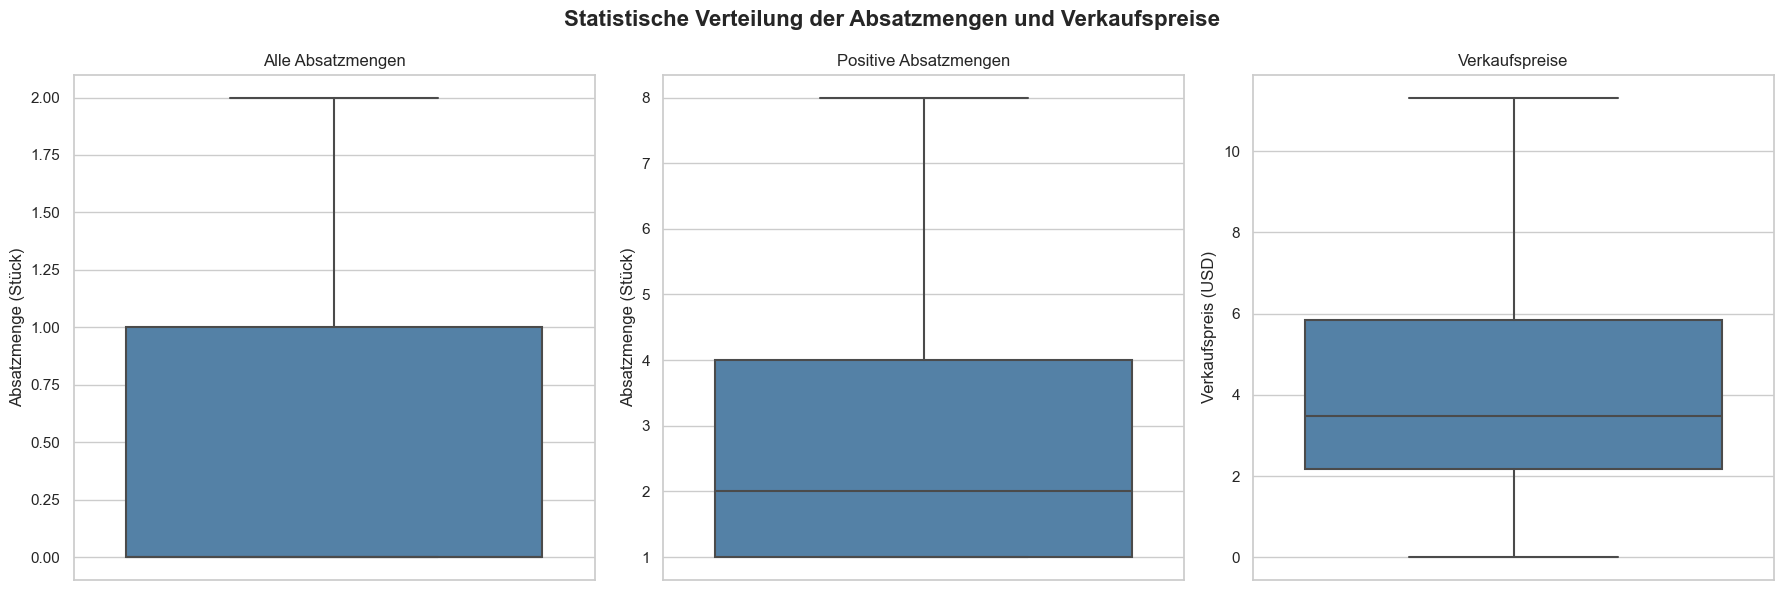

In [17]:
# Vorbereitung der numerischen Daten

sales_values = sales[day_columns].to_numpy().ravel()

positive_sales = sales_values[sales_values > 0]

# Erstellung der Boxplots

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

plot_data = [
    sales_values,
    positive_sales,
    prices["sell_price"]
]

titles = [
    "Alle Absatzmengen",
    "Positive Absatzmengen",
    "Verkaufspreise"
]

ylabels = ["Absatzmenge (Stück)",
           "Absatzmenge (Stück)",
           "Verkaufspreis (USD)"]

for ax, values, title, ylabel in zip(
    axes, plot_data, titles, ylabels
):

    sns.boxplot(
        y=values,
        ax=ax,
        color="steelblue",
        showfliers=False
    )

    ax.set_title(title)
    ax.set_ylabel(ylabel)

fig.suptitle(
    "Statistische Verteilung der Absatzmengen und Verkaufspreise",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Freigabe temporärer Array-Referenzen

del sales_values, positive_sales, plot_data, values

**Ergebnis:**

- Keine negativen oder ungültigen Werte. Absatzmengen liegen zwischen 0 und 763
  Einheiten, Verkaufspreise zwischen 0,01 und 107,32 USD.
- **68 % aller Beobachtungen weisen keinen Absatz auf.** Mögliche Ursachen sind
  intermittierende Nachfrage, nicht gelistete Artikel oder Lieferengpässe
  (siehe Abschnitt 7.7).
- Die Verteilungen sind stark rechtsschief: Der Median positiver Absatzmengen liegt
  bei 2 Einheiten, die mittleren 50 % der Preise zwischen 2,18 und 5,84 USD.
- Die IQR-Methode markiert 11,89 % der Absatzmengen (7,80 % der positiven Werte)
  und 4,44 % der Preise als auffällig. Globale Grenzen berücksichtigen jedoch keine
  produkt- oder saisonspezifischen Unterschiede.

Ausreißer und Nullabsätze werden daher **nicht entfernt**. In den Boxplots sind
Ausreißer nur zur besseren Lesbarkeit ausgeblendet.

### 3.4 Extreme Beobachtungen

Die höchsten Absatzmengen und Verkaufspreise werden auf Produktebene eingeordnet.

In [20]:
# Ermittlung der höchsten täglichen Absatzmenge
# je Produkt-Filial-Kombination

extreme_sales = sales[categorical_columns].copy()

extreme_sales["max_daily_sales"] = (
    sales[day_columns].max(axis=1)
)

# Auswahl der zehn höchsten produktbezogenen Maximalwerte

top_sales = extreme_sales.nlargest(
    10, "max_daily_sales"
).copy()

# Identifikation des Tages mit maximalem Absatz

top_sales["d"] = sales.loc[
    top_sales.index, day_columns
].idxmax(axis=1)

# Verknüpfung mit den Kalenderdaten

top_sales = top_sales.merge(
    calendar[["d", "date", "weekday", "event_name_1"]],
    on="d",
    how="left"
)

display(top_sales)

# Auswahl der zehn höchsten Verkaufspreise

top_prices = prices.nlargest(10, "sell_price")

display(top_prices)

# Verteilung der extremen Absatzmengen nach Warengruppen

display(top_sales["cat_id"].value_counts())

display(top_sales["item_id"].value_counts())

# Untersuchung des zeitlichen Kontexts

display(
    top_sales[
        ["item_id", "store_id", "max_daily_sales",
         "date", "weekday", "event_name_1"]
    ]
)

# Auswahl des Produkts mit dem höchsten Verkaufspreis

product_id = top_prices.iloc[0]["item_id"]

product_prices = prices[
    prices["item_id"] == product_id
]

# Vergleich der Verkaufspreise zwischen den Filialen

price_comparison = (
    product_prices
    .groupby("store_id", observed=True)["sell_price"]
    .agg(["count", "min", "mean", "median", "max"])
    .round(2)
)

display(price_comparison)

,id,item_id,dept_id,cat_id,store_id,state_id,max_daily_sales,d,date,weekday,event_name_1
0,FOODS_3_090_CA_3_evaluation,FOODS_3_090,FOODS_3,FOODS,CA_3,CA,763,d_960,2013-09-14,Saturday,NaN
1,FOODS_3_785_CA_1_evaluation,FOODS_3_785,FOODS_3,FOODS,CA_1,CA,648,d_511,2012-06-22,Friday,NaN
2,FOODS_2_285_TX_1_evaluation,FOODS_2_285,FOODS_2,FOODS,TX_1,TX,634,d_98,2011-05-06,Friday,NaN
3,HOUSEHOLD_1_474_TX_2_evaluation,HOUSEHOLD_1_474,HOUSEHOLD_1,HOUSEHOLD,TX_2,TX,626,d_908,2013-07-24,Wednesday,NaN
4,HOUSEHOLD_2_062_TX_1_evaluation,HOUSEHOLD_2_062,HOUSEHOLD_2,HOUSEHOLD,TX_1,TX,601,d_859,2013-06-05,Wednesday,NaN
5,FOODS_3_090_CA_1_evaluation,FOODS_3_090,FOODS_3,FOODS,CA_1,CA,599,d_947,2013-09-01,Sunday,NaN
6,FOODS_3_318_CA_3_evaluation,FOODS_3_318,FOODS_3,FOODS,CA_3,CA,436,d_2,2011-01-30,Sunday,NaN
7,FOODS_3_090_TX_2_evaluation,FOODS_3_090,FOODS_3,FOODS,TX_2,TX,412,d_948,2013-09-02,Monday,LaborDay
8,FOODS_3_090_TX_1_evaluation,FOODS_3_090,FOODS_3,FOODS,TX_1,TX,402,d_939,2013-08-24,Saturday,NaN
9,FOODS_3_547_TX_3_evaluation,FOODS_3_547,FOODS_3,FOODS,TX_3,TX,385,d_928,2013-08-13,Tuesday,NaN


,store_id,item_id,wm_yr_wk,sell_price
6485945,WI_3,HOUSEHOLD_2_406,11317,107.32
6485946,WI_3,HOUSEHOLD_2_406,11318,107.32
6485947,WI_3,HOUSEHOLD_2_406,11319,107.32
5805271,WI_2,HOUSEHOLD_2_406,11237,61.46
5805272,WI_2,HOUSEHOLD_2_406,11238,61.46
5805273,WI_2,HOUSEHOLD_2_406,11239,61.46
5805274,WI_2,HOUSEHOLD_2_406,11240,61.46
5805275,WI_2,HOUSEHOLD_2_406,11241,61.46
5805276,WI_2,HOUSEHOLD_2_406,11242,61.46
5805277,WI_2,HOUSEHOLD_2_406,11243,61.46


cat_id
FOODS        8
HOUSEHOLD    2
HOBBIES      0
Name: count, dtype: int64

item_id
FOODS_3_090        4
FOODS_3_318        1
HOUSEHOLD_1_474    1
FOODS_3_785        1
FOODS_3_547        1
                  ..
HOUSEHOLD_1_463    0
HOUSEHOLD_1_464    0
HOUSEHOLD_1_465    0
HOUSEHOLD_1_466    0
FOODS_3_827        0
Name: count, Length: 3049, dtype: int64

,item_id,store_id,max_daily_sales,date,weekday,event_name_1
0,FOODS_3_090,CA_3,763,2013-09-14,Saturday,NaN
1,FOODS_3_785,CA_1,648,2012-06-22,Friday,NaN
2,FOODS_2_285,TX_1,634,2011-05-06,Friday,NaN
3,HOUSEHOLD_1_474,TX_2,626,2013-07-24,Wednesday,NaN
4,HOUSEHOLD_2_062,TX_1,601,2013-06-05,Wednesday,NaN
5,FOODS_3_090,CA_1,599,2013-09-01,Sunday,NaN
6,FOODS_3_318,CA_3,436,2011-01-30,Sunday,NaN
7,FOODS_3_090,TX_2,412,2013-09-02,Monday,LaborDay
8,FOODS_3_090,TX_1,402,2013-08-24,Saturday,NaN
9,FOODS_3_547,TX_3,385,2013-08-13,Tuesday,NaN


,count,min,mean,median,max
store_id,,,,,
CA_1,282,12.46,12.46,12.46,12.47
CA_2,282,12.46,12.46,12.46,12.47
CA_3,282,12.46,12.46,12.46,12.47
CA_4,282,12.46,12.46,12.46,12.47
TX_1,281,9.98,12.45,12.46,12.47
TX_2,282,3.47,12.43,12.46,12.47
TX_3,281,12.46,12.46,12.46,12.47
WI_1,282,9.97,12.64,12.46,35.88
WI_2,282,12.46,15.51,12.46,61.46


**Ergebnis:** Acht der zehn höchsten Tagesabsätze entfallen auf die Kategorie FOODS;
der Artikel FOODS_3_090 erscheint viermal (u. a. 412 Einheiten am Labor Day in TX_2).

Der Artikel HOUSEHOLD_2_406 kostet in allen Filialen im Median 12,46 USD, erreicht
in Wisconsin jedoch bis zu 107,32 USD (rund das 8,6-Fache). Die Ursache ist nicht
bestimmbar; die Werte bleiben erhalten und werden als Datenqualitätsrisiko dokumentiert.

### 3.5 Zusammenfassung der Datenqualität

Die Daten weisen eine gute strukturelle Qualität auf: keine Duplikate, vollständige
Referenzen, ein lückenloser Kalender und keine ungültigen Werte.

Zu berücksichtigen sind die strukturell fehlenden Ereignisangaben, der hohe
Nullabsatz-Anteil (68 %) sowie einzelne Preisauffälligkeiten.

## 4. Data Cleaning & Transformation

### 4.1 Fehlende Werte und Kalendermerkmale

Fehlende Ereignisangaben werden durch `No_Event` ersetzt. Zusätzlich werden acht
Kalendermerkmale abgeleitet, die im Voraus bekannt sind und sich daher für die
Prognose eignen: Quartal, Tag im Monat, Kalenderwoche, Wochenende, Monatsanfang,
Monatsende, Anzahl der Ereignisse und Ereignistag.

In [24]:
# Erstellung einer Arbeitskopie der Kalenderdaten

calendar_clean = calendar.copy()

# Definition der betroffenen Ereignisvariablen

event_columns = [
    "event_name_1",
    "event_type_1",
    "event_name_2",
    "event_type_2"
]

# Behandlung strukturell bedingter fehlender Werte

for col in event_columns:

    calendar_clean[col] = (
        calendar_clean[col]
        .astype("string")
        .fillna("No_Event")
        .astype("category")
    )

# Überprüfung verbleibender fehlender Werte

print("Fehlende Werte nach der Datenbereinigung:")

display(calendar_clean.isna().sum())

# Überprüfung der ersten fünf Beobachtungen

display(calendar_clean.head())

# Ableitung zusätzlicher zeitbezogener Merkmale

calendar_clean["quarter"] = (
    calendar_clean["date"].dt.quarter.astype("int8")
)

calendar_clean["day_of_month"] = (
    calendar_clean["date"].dt.day.astype("int8")
)

calendar_clean["week_of_year"] = (
    calendar_clean["date"].dt.isocalendar().week.astype("int8")
)

# Identifikation von Wochenenden

calendar_clean["is_weekend"] = (
    calendar_clean["date"].dt.dayofweek >= 5
).astype("int8")

# Identifikation von Monatsanfang und Monatsende

calendar_clean["is_month_start"] = (
    calendar_clean["date"].dt.is_month_start.astype("int8")
)

calendar_clean["is_month_end"] = (
    calendar_clean["date"].dt.is_month_end.astype("int8")
)

# Anzahl registrierter Ereignisse pro Tag

calendar_clean["event_count"] = (
    (calendar_clean["event_name_1"] != "No_Event").astype("int8")
    +
    (calendar_clean["event_name_2"] != "No_Event").astype("int8")
)

# Identifikation von Tagen mit besonderen Ereignissen

calendar_clean["is_event"] = (
    calendar_clean["event_count"] > 0
).astype("int8")

# Überprüfung der neu erstellten Merkmale

new_calendar_features = [
    "quarter",
    "day_of_month",
    "week_of_year",
    "is_weekend",
    "is_month_start",
    "is_month_end",
    "is_event",
    "event_count"
]

display(
    calendar_clean[["date"] + new_calendar_features].head(10)
)

print("Neue Datensatzdimension:", calendar_clean.shape)

Fehlende Werte nach der Datenbereinigung:


date            0
wm_yr_wk        0
weekday         0
wday            0
month           0
year            0
d               0
event_name_1    0
event_type_1    0
event_name_2    0
event_type_2    0
snap_CA         0
snap_TX         0
snap_WI         0
dtype: int64

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,No_Event,No_Event,No_Event,No_Event,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,No_Event,No_Event,No_Event,No_Event,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,No_Event,No_Event,No_Event,No_Event,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,No_Event,No_Event,No_Event,No_Event,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,No_Event,No_Event,No_Event,No_Event,1,0,1


,date,quarter,day_of_month,week_of_year,is_weekend,is_month_start,is_month_end,is_event,event_count
0,2011-01-29,1,29,4,1,0,0,0,0
1,2011-01-30,1,30,4,1,0,0,0,0
2,2011-01-31,1,31,5,0,0,1,0,0
3,2011-02-01,1,1,5,0,1,0,0,0
4,2011-02-02,1,2,5,0,0,0,0,0
5,2011-02-03,1,3,5,0,0,0,0,0
6,2011-02-04,1,4,5,0,0,0,0,0
7,2011-02-05,1,5,5,1,0,0,0,0
8,2011-02-06,1,6,5,1,0,0,1,1
9,2011-02-07,1,7,6,0,0,0,0,0


Neue Datensatzdimension: (1969, 22)


### 4.2 Transformation vom Wide- ins Long-Format

Für Datenbank und Zeitreihenanalyse wird jede Kombination aus Produkt, Filiale und
Tag zu einer eigenen Zeile. Um den Arbeitsspeicher zu schonen, erfolgt die
Transformation blockweise (153 Blöcke à 200 Produkt-Filial-Kombinationen) über
eine wiederverwendbare Funktion und einen Python-Generator.

In [26]:
# Ermittlung des erwarteten Datenumfangs
# nach der Wide-to-Long-Transformation

n_series = sales.shape[0]
n_days = len(day_columns)

expected_rows = n_series * n_days

print("Anzahl der Produkt-Filial-Kombinationen:", 
      f"{n_series:,}")

print("Anzahl der historischen Verkaufstage:", 
      f"{n_days:,}")

print("Erwartete Anzahl der Zeilen im Long-Format:", 
      f"{expected_rows:,}")

# Definition der Chunk-Größe

CHUNK_SIZE = 200

# Berechnung der Anzahl erforderlicher Chunks

n_chunks = (n_series + CHUNK_SIZE - 1) // CHUNK_SIZE

# Erwartete Zeilenanzahl pro vollständigem Chunk

rows_per_chunk = CHUNK_SIZE * n_days

# Ausgabe der Verarbeitungskonfiguration

print("Chunk-Größe:", CHUNK_SIZE)
print("Anzahl der Chunks:", n_chunks)
print("Zeilen pro vollständigem Chunk:", 
      f"{rows_per_chunk:,}")

# Definition einer wiederverwendbaren Transformationsfunktion

def transform_sales_chunk(chunk):

    # Transformation vom Wide-Format ins Long-Format

    sales_long = chunk.melt(
        id_vars=categorical_columns,
        value_vars=day_columns,
        var_name="d",
        value_name="sales"
    )

    # Speicheroptimierung der Datentypen

    sales_long["d"] = sales_long["d"].astype("category")
    sales_long["sales"] = sales_long["sales"].astype("int32")

    return sales_long

# Definition eines Generators zur blockweisen Datenverarbeitung

def generate_sales_chunks(df, chunk_size=200):

    for start in range(0, len(df), chunk_size):

        # Auswahl des aktuellen Datenblocks

        chunk = df.iloc[start:start + chunk_size]

        # Transformation des Datenblocks

        transformed_chunk = transform_sales_chunk(chunk)

        # Bereitstellung des transformierten Datenblocks

        yield transformed_chunk

Anzahl der Produkt-Filial-Kombinationen: 30,490
Anzahl der historischen Verkaufstage: 1,941
Erwartete Anzahl der Zeilen im Long-Format: 59,181,090
Chunk-Größe: 200
Anzahl der Chunks: 153
Zeilen pro vollständigem Chunk: 388,200


In [27]:
import time

# Initialisierung der Validierungsvariablen

total_rows = 0
total_chunks = 0
total_sales = 0

start_time = time.perf_counter()

# Blockweise Verarbeitung des Gesamtdatensatzes

for chunk in generate_sales_chunks(sales, CHUNK_SIZE):

    total_rows += len(chunk)
    total_chunks += 1
    total_sales += int(chunk["sales"].sum())

    # Fortschrittsanzeige

    if total_chunks % 20 == 0:
        print(f"{total_chunks} Datenblöcke verarbeitet.")

# Berechnung der gesamten Laufzeit

elapsed_time = time.perf_counter() - start_time

# Berechnung der ursprünglichen Absatzmenge

original_total_sales = int(
    sales[day_columns].sum().sum()
)

# Ausgabe der Validierungsergebnisse

print("-" * 60)

print("Verarbeitete Datenblöcke:", total_chunks)
print("Transformierte Beobachtungen:", f"{total_rows:,}")
print("Erwartete Beobachtungen:", f"{expected_rows:,}")
print("Ursprüngliche Absatzmenge:", f"{original_total_sales:,}")
print("Transformierte Absatzmenge:", f"{total_sales:,}")

print("Vollständigkeit:", total_rows == expected_rows)
print("Absatzmengenkonsistenz:", total_sales == original_total_sales)

print(f"Laufzeit: {elapsed_time:.2f} Sekunden")

20 Datenblöcke verarbeitet.
40 Datenblöcke verarbeitet.
60 Datenblöcke verarbeitet.
80 Datenblöcke verarbeitet.
100 Datenblöcke verarbeitet.
120 Datenblöcke verarbeitet.
140 Datenblöcke verarbeitet.
------------------------------------------------------------
Verarbeitete Datenblöcke: 153
Transformierte Beobachtungen: 59,181,090
Erwartete Beobachtungen: 59,181,090
Ursprüngliche Absatzmenge: 66,927,173
Transformierte Absatzmenge: 66,927,173
Vollständigkeit: True
Absatzmengenkonsistenz: True
Laufzeit: 24.03 Sekunden


**Ergebnis:** 59.181.090 Zeilen wurden in 23,65 Sekunden erzeugt.
Die Gesamtabsatzmenge von 66.927.173 Einheiten bleibt unverändert.

### 4.3 Speicherung im Parquet-Format

Die transformierten Daten werden blockweise in eine komprimierte Parquet-Datei
(Snappy) geschrieben und anschließend anhand der Metadaten und der Absatzsumme
geprüft.

In [30]:
# Überprüfung der verfügbaren Parquet-Bibliothek

try:
    import pyarrow as pa
    import pyarrow.parquet as pq

    print("PyArrow ist verfügbar.")
    print("Version:", pa.__version__)

except ImportError:
    print("PyArrow ist nicht installiert.")

from pathlib import Path

# Definition des Ausgabeverzeichnisses

output_dir = Path("../data_processed")

output_dir.mkdir(parents=True, exist_ok=True)

# Definition der Ausgabedatei

sales_parquet_path = output_dir / "sales_long.parquet"

print("Ausgabedatei:", sales_parquet_path.as_posix())

# Initialisierung der Speicherparameter

writer = None
written_rows = 0
written_chunks = 0

start_time = time.perf_counter()

try:

    # Blockweise Transformation und Speicherung

    for chunk in generate_sales_chunks(sales, CHUNK_SIZE):

        # Konvertierung in eine Arrow-Tabelle

        table = pa.Table.from_pandas(
            chunk,
            preserve_index=False
        )

        # Initialisierung des ParquetWriter

        if writer is None:

            writer = pq.ParquetWriter(
                sales_parquet_path,
                table.schema,
                compression="snappy"
            )

        # Speicherung des aktuellen Datenblocks

        writer.write_table(table)

        written_rows += len(chunk)
        written_chunks += 1

        # Fortschrittsanzeige

        if written_chunks % 20 == 0:
            print(f"{written_chunks} Datenblöcke gespeichert.")

finally:

    # Ordnungsgemäßes Schließen der Parquet-Datei

    if writer is not None:
        writer.close()

# Berechnung der Laufzeit

elapsed_time = time.perf_counter() - start_time

# Ausgabe der Ergebnisse

print("-" * 60)

print("Gespeicherte Datenblöcke:", written_chunks)
print("Gespeicherte Beobachtungen:", f"{written_rows:,}")
print("Laufzeit (Sekunden):", round(elapsed_time, 2))

print("Dateigröße (MiB):",
      round(sales_parquet_path.stat().st_size / 1024**2, 2))

print("Vollständigkeit:", written_rows == expected_rows)

PyArrow ist verfügbar.
Version: 14.0.2
Ausgabedatei: ../data_processed/sales_long.parquet
20 Datenblöcke gespeichert.
40 Datenblöcke gespeichert.
60 Datenblöcke gespeichert.
80 Datenblöcke gespeichert.
100 Datenblöcke gespeichert.
120 Datenblöcke gespeichert.
140 Datenblöcke gespeichert.
------------------------------------------------------------
Gespeicherte Datenblöcke: 153
Gespeicherte Beobachtungen: 59,181,090
Laufzeit (Sekunden): 33.76
Dateigröße (MiB): 63.62
Vollständigkeit: True


In [31]:
# Öffnen der Parquet-Datei

parquet_file = pq.ParquetFile(sales_parquet_path)

# Extraktion der Dateimetadaten

metadata = parquet_file.metadata

# Überprüfung der gespeicherten Datenstruktur

print("Anzahl der Beobachtungen:",
      f"{metadata.num_rows:,}")

print("Anzahl der Spalten:",
      metadata.num_columns)

print("Anzahl der Row Groups:",
      metadata.num_row_groups)

print("Kompressionsverfahren:",
      metadata.row_group(0).column(0).compression)

print("Vollständigkeit:",
      metadata.num_rows == expected_rows)

# Ausgabe des Datenschemas

print("\nDatenschema:")

print(parquet_file.schema_arrow)

import pyarrow.compute as pc

# Initialisierung der Kontrollvariable

parquet_total_sales = 0

# Blockweises Lesen der Absatzmengen

for batch in parquet_file.iter_batches(
    batch_size=500_000,
    columns=["sales"]
):

    parquet_total_sales += pc.sum(
        batch.column(0)
    ).as_py()

# Überprüfung der Absatzmengenkonsistenz

print("Ursprüngliche Absatzmenge:",
      f"{original_total_sales:,}")

print("Gespeicherte Absatzmenge:",
      f"{parquet_total_sales:,}")

print("Absatzmengenkonsistenz:",
      parquet_total_sales == original_total_sales)

Anzahl der Beobachtungen: 59,181,090
Anzahl der Spalten: 8
Anzahl der Row Groups: 153
Kompressionsverfahren: SNAPPY
Vollständigkeit: True

Datenschema:
id: dictionary<values=string, indices=int32, ordered=0>
item_id: dictionary<values=string, indices=int32, ordered=0>
dept_id: dictionary<values=string, indices=int32, ordered=0>
cat_id: dictionary<values=string, indices=int32, ordered=0>
store_id: dictionary<values=string, indices=int32, ordered=0>
state_id: dictionary<values=string, indices=int32, ordered=0>
d: dictionary<values=string, indices=int32, ordered=0>
sales: int32
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 1233
Ursprüngliche Absatzmenge: 66,927,173
Gespeicherte Absatzmenge: 66,927,173
Absatzmengenkonsistenz: True


**Ergebnis:** Die Datei enthält alle 59.181.090 Beobachtungen bei nur 63,62 MiB
Dateigröße (Laufzeit: 31,90 Sekunden). Die gespeicherte Absatzmenge stimmt mit
den Ausgangsdaten überein.

## 5. Datenintegration (Data Integration)

### 5.1 Integrationslogik

Absatz-, Kalender- und Preisdaten werden zu einer gemeinsamen Datengrundlage
zusammengeführt. Eine wiederverwendbare Funktion führt je Datenblock folgende
Schritte aus:

- **Kalenderdaten:** Left Join über den Tagesschlüssel `d`
- **Verkaufspreise:** Left Join über `item_id`, `store_id` und `wm_yr_wk`.
  Fehlende Preise werden nicht imputiert, da sie auf Zeiträume hinweisen,
  in denen ein Artikel nicht im Sortiment war.
- **Umsatz:** Absatzmenge × Verkaufspreis (bei Absatz null: Umsatz null)
- **Indikatoren:** `price_available` und `has_sales`
- **Qualitätsprüfungen:** Zeilen- und Absatzmengenkonsistenz sowie vollständige
  Zuordnung der Kalendertage

In [34]:
# Definition einer wiederverwendbaren Integrationsfunktion

def integrate_sales_chunk(chunk):

    # Integration der Kalenderdaten

    integrated = chunk.merge(
        calendar_clean,
        on="d",
        how="left",
        validate="many_to_one"
    )

    # Integration der Verkaufspreise

    integrated = integrated.merge(
        prices,
        on=["item_id", "store_id", "wm_yr_wk"],
        how="left",
        validate="many_to_one"
    )

    # Berechnung des Umsatzes

    integrated["revenue"] = (
        integrated["sales"] *
        integrated["sell_price"]
    )

    integrated.loc[
        integrated["sales"] == 0,
        "revenue"
    ] = 0.0

    # Erstellung binärer Indikatoren

    integrated["price_available"] = (
        integrated["sell_price"].notna()
    ).astype("int8")

    integrated["has_sales"] = (
        integrated["sales"] > 0
    ).astype("int8")

    # Automatisierte Datenqualitätsprüfungen

    if len(integrated) != len(chunk):
        raise ValueError("Fehler bei der Zeilenkonsistenz.")

    if integrated["sales"].sum() != chunk["sales"].sum():
        raise ValueError("Fehler bei der Absatzmengenkonsistenz.")

    if integrated["date"].isna().any():
        raise ValueError("Nicht zuordenbare Kalendertage.")

    return integrated

### 5.2 Vollständige Integration

Die Funktion wird blockweise auf den gesamten Datensatz angewendet; das Ergebnis
wird als Parquet-Datei gespeichert.

In [36]:
import time
import pyarrow as pa
import pyarrow.parquet as pq

from pathlib import Path

# Definition des Ausgabepfads

integrated_path = Path(
    "../data_processed/sales_integrated.parquet"
)

# Sicherstellung der Verzeichnisstruktur

integrated_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# Initialisierung der Kontrollvariablen

total_integrated_rows = 0
total_integrated_sales = 0
total_revenue = 0.0

total_missing_prices = 0
total_missing_revenue = 0
total_missing_prices_with_sales = 0

processed_chunks = 0

print("Ausgabepfad:", integrated_path.as_posix())
print("Zu verarbeitende Datenblöcke:",
      parquet_file.num_row_groups)

print("Erwartete Beobachtungen:",
      f"{expected_rows:,}")

# Initialisierung der Laufzeitmessung

start_time = time.perf_counter()

# Initialisierung der Kontrollvariablen

total_integrated_rows = 0
total_integrated_sales = 0
total_revenue = 0.0

total_missing_prices = 0
total_missing_revenue = 0
total_missing_prices_with_sales = 0

processed_chunks = 0
writer = None

# Blockweise Integration und Speicherung

try:
    for i in range(parquet_file.num_row_groups):

        # Einlesen des aktuellen Datenblocks
        chunk = parquet_file.read_row_group(i).to_pandas()

        # Integration der Datenquellen
        integrated_chunk = integrate_sales_chunk(chunk)

        # Überprüfung der Datenkonsistenz
        assert len(integrated_chunk) == len(chunk)

        assert (
            integrated_chunk["sales"].sum()
            == chunk["sales"].sum()
        )

        # Erfassung der Qualitätskennzahlen
        total_integrated_rows += len(integrated_chunk)

        total_integrated_sales += int(
            integrated_chunk["sales"].sum()
        )

        total_revenue += float(
            integrated_chunk["revenue"].sum()
        )

        total_missing_prices += int(
            integrated_chunk["sell_price"].isna().sum()
        )

        total_missing_revenue += int(
            integrated_chunk["revenue"].isna().sum()
        )

        total_missing_prices_with_sales += int(
            (
                integrated_chunk["sell_price"].isna()
                & (integrated_chunk["sales"] > 0)
            ).sum()
        )

        # Konvertierung in das Arrow-Format
        table = pa.Table.from_pandas(
            integrated_chunk,
            preserve_index=False
        )

        # Initialisierung des Parquet-Writers
        if writer is None:
            writer = pq.ParquetWriter(
                integrated_path,
                table.schema,
                compression="snappy"
            )

        # Speicherung des aktuellen Datenblocks
        writer.write_table(table)

        processed_chunks += 1

        # Ausgabe des Verarbeitungsfortschritts
        if processed_chunks % 10 == 0:
            print(
                f"{processed_chunks}/"
                f"{parquet_file.num_row_groups} "
                "Datenblöcke integriert."
            )

        # Freigabe temporärer Datenobjekte
        del chunk, integrated_chunk, table

finally:
    if writer is not None:
        writer.close()

# Berechnung der Gesamtlaufzeit

elapsed_time = time.perf_counter() - start_time

# Ausgabe der Integrations- und Qualitätskennzahlen

print("-" * 60)

print("Integrierte Datenblöcke:",
      processed_chunks)

print("Integrierte Beobachtungen:",
      f"{total_integrated_rows:,}")

print("Gesamte Absatzmenge:",
      f"{total_integrated_sales:,}")

print("Gesamtumsatz (USD):",
      f"{total_revenue:,.2f}")

print("Fehlende Verkaufspreise:",
      f"{total_missing_prices:,}")

print("Anteil fehlender Verkaufspreise (%):",
      round(total_missing_prices
            / total_integrated_rows * 100, 2))

print("Fehlende Preise mit positivem Absatz:",
      f"{total_missing_prices_with_sales:,}")

print("Fehlende Umsatzwerte:",
      f"{total_missing_revenue:,}")

print("Vollständigkeit:",
      total_integrated_rows == expected_rows)

print("Absatzmengenkonsistenz:",
      total_integrated_sales == original_total_sales)

print("Laufzeit (Sekunden):",
      round(elapsed_time, 2))

print("Dateigröße (MiB):",
      round(integrated_path.stat().st_size / 1024**2, 2))

Ausgabepfad: ../data_processed/sales_integrated.parquet
Zu verarbeitende Datenblöcke: 153
Erwartete Beobachtungen: 59,181,090
10/153 Datenblöcke integriert.
20/153 Datenblöcke integriert.
30/153 Datenblöcke integriert.
40/153 Datenblöcke integriert.
50/153 Datenblöcke integriert.
60/153 Datenblöcke integriert.
70/153 Datenblöcke integriert.
80/153 Datenblöcke integriert.
90/153 Datenblöcke integriert.
100/153 Datenblöcke integriert.
110/153 Datenblöcke integriert.
120/153 Datenblöcke integriert.
130/153 Datenblöcke integriert.
140/153 Datenblöcke integriert.
150/153 Datenblöcke integriert.
------------------------------------------------------------
Integrierte Datenblöcke: 153
Integrierte Beobachtungen: 59,181,090
Gesamte Absatzmenge: 66,927,173
Gesamtumsatz (USD): 191,577,546.04
Fehlende Verkaufspreise: 12,299,413
Anteil fehlender Verkaufspreise (%): 20.78
Fehlende Preise mit positivem Absatz: 0
Fehlende Umsatzwerte: 0
Vollständigkeit: True
Absatzmengenkonsistenz: True
Laufzeit (Seku

### 5.3 Validierung und Ergebnis

Abschließend werden Struktur und Kennzahlen der gespeicherten Datei geprüft.

In [38]:
# Öffnen des integrierten Parquet-Datensatzes

integrated_parquet = pq.ParquetFile(integrated_path)

# Untersuchung der Dateimetadaten

metadata = integrated_parquet.metadata

print("Anzahl der Beobachtungen:",
      f"{metadata.num_rows:,}")

print("Anzahl der Spalten:",
      metadata.num_columns)

print("Anzahl der Row Groups:",
      metadata.num_row_groups)

print("Kompressionsverfahren:",
      metadata.row_group(0).column(0).compression)

print("Vollständigkeit:",
      metadata.num_rows == expected_rows)

# Untersuchung des Datenschemas

print("\nDatenschema:")

print(integrated_parquet.schema_arrow)

# Initialisierung der Validierungskennzahlen

validated_rows = 0
validated_sales = 0
validated_revenue = 0.0

missing_prices = 0
missing_prices_positive_sales = 0
missing_revenue = 0

# Blockweise Validierung des gespeicherten Datensatzes

for batch in integrated_parquet.iter_batches(
    batch_size=500_000,
    columns=["sales", "sell_price", "revenue"]
):

    chunk = batch.to_pandas()

    validated_rows += len(chunk)
    validated_sales += int(chunk["sales"].sum())
    validated_revenue += chunk["revenue"].sum()

    missing_prices += chunk["sell_price"].isna().sum()

    missing_prices_positive_sales += (
        chunk["sell_price"].isna()
        & (chunk["sales"] > 0)
    ).sum()

    missing_revenue += chunk["revenue"].isna().sum()

# Ausgabe der Validierungsergebnisse

print("Validierte Beobachtungen:",
      f"{validated_rows:,}")

print("Validierte Absatzmenge:",
      f"{validated_sales:,}")

print("Validierter Gesamtumsatz (USD):",
      f"{validated_revenue:,.2f}")

print("Fehlende Verkaufspreise:",
      f"{missing_prices:,}")

print("Fehlende Preise bei positivem Absatz:",
      missing_prices_positive_sales)

print("Fehlende Umsatzwerte:",
      missing_revenue)

# Überprüfung der Datenkonsistenz

print("Vollständigkeit:",
      validated_rows == expected_rows)

print("Absatzmengenkonsistenz:",
      validated_sales == original_total_sales)

print("Umsatzkonsistenz:",
      np.isclose(
          validated_revenue,
          191_577_546.04,
          rtol=0,
          atol=0.01
      ))

# Freigabe temporärer Daten

del chunk, batch

Anzahl der Beobachtungen: 59,181,090
Anzahl der Spalten: 33
Anzahl der Row Groups: 153
Kompressionsverfahren: SNAPPY
Vollständigkeit: True

Datenschema:
id: dictionary<values=string, indices=int32, ordered=0>
item_id: dictionary<values=string, indices=int32, ordered=0>
dept_id: dictionary<values=string, indices=int32, ordered=0>
cat_id: dictionary<values=string, indices=int32, ordered=0>
store_id: dictionary<values=string, indices=int32, ordered=0>
state_id: dictionary<values=string, indices=int32, ordered=0>
d: string
sales: int32
date: timestamp[ns]
wm_yr_wk: int64
weekday: string
wday: int64
month: int64
year: int64
event_name_1: dictionary<values=string, indices=int32, ordered=0>
event_type_1: dictionary<values=string, indices=int32, ordered=0>
event_name_2: dictionary<values=string, indices=int32, ordered=0>
event_type_2: dictionary<values=string, indices=int32, ordered=0>
snap_CA: int64
snap_TX: int64
snap_WI: int64
quarter: int8
day_of_month: int8
week_of_year: int8
is_weekend: 

**Ergebnis:** Der integrierte Datensatz umfasst 59.181.090 Beobachtungen mit
33 Variablen, 66.927.173 verkaufte Einheiten und einen Gesamtumsatz von
191.577.546,04 USD (Laufzeit: 376,2 Sekunden, Dateigröße: 129,01 MiB).

Bei 12.299.413 Beobachtungen (20,78 %) fehlt ein Verkaufspreis. Sie betreffen
**ausschließlich Tage ohne Absatz**, sodass die Umsatzberechnung nicht beeinträchtigt
wird. Alle Konsistenzprüfungen wurden bestanden.

## 6. Relationale Datenmodellierung und PostgreSQL

### 6.1 Star Schema

Für analytische SQL-Abfragen wird ein dimensionales Datenmodell erstellt:

- `fact_sales`: Absatz, Preis und Umsatz je Produkt, Filiale und Tag
- `dim_product`: Produkthierarchie (Kategorie, Abteilung, Produkt)
- `dim_store`: Filialen und Bundesstaaten
- `dim_date`: Kalender mit Ereignissen und abgeleiteten Merkmalen

Jede Dimension erhält einen künstlichen Primärschlüssel (Surrogate Key);
die Kalenderdimension verwendet einen Datumsschlüssel im Format YYYYMMDD.

### 6.2 Dimensionstabellen

In [41]:
# Extraktion der eindeutigen Produktstammdaten

dim_product = (
    sales[["item_id", "dept_id", "cat_id"]]
    .drop_duplicates()
    .sort_values("item_id")
    .reset_index(drop=True)
    .copy()
)

# Erstellung eines künstlichen Primärschlüssels

dim_product.insert(
    0,
    "product_key",
    np.arange(1, len(dim_product) + 1, dtype=np.int32)
)

# Ausgabe der Produktdimension

display(dim_product.head(10))

print("Dimension:", dim_product.shape)

print("Eindeutige Produkte:",
      dim_product["item_id"].nunique())

print("Eindeutige Abteilungen:",
      dim_product["dept_id"].nunique())

print("Eindeutige Kategorien:",
      dim_product["cat_id"].nunique())

# Extraktion der eindeutigen Filialstammdaten

dim_store = (
    sales[["store_id", "state_id"]]
    .drop_duplicates()
    .sort_values("store_id")
    .reset_index(drop=True)
    .copy()
)

# Erstellung eines künstlichen Primärschlüssels

dim_store.insert(
    0,
    "store_key",
    np.arange(1, len(dim_store) + 1, dtype=np.int32)
)

# Ausgabe der Filialdimension

display(dim_store)

print("Dimension:", dim_store.shape)

print("Eindeutige Filialen:",
      dim_store["store_id"].nunique())

print("Eindeutige Bundesstaaten:",
      dim_store["state_id"].nunique())

# Validierung der Filialdimension

print("Primärschlüssel eindeutig:",
      dim_store["store_key"].is_unique)

print("Natürlicher Schlüssel eindeutig:",
      dim_store["store_id"].is_unique)

print("Fehlende Werte:",
      dim_store.isna().sum().sum())

print("Duplikate:",
      dim_store.duplicated().sum())

# Erstellung der Kalenderdimension

dim_date = (
    calendar_clean
    .copy()
    .sort_values("date")
    .reset_index(drop=True)
)

# Erstellung des numerischen Datumsschlüssels

dim_date.insert(
    0,
    "date_key",
    dim_date["date"].dt.strftime("%Y%m%d").astype(np.int32)
)

# Ausgabe der Kalenderdimension

display(dim_date.head())

print("Dimension:", dim_date.shape)

print("Eindeutige Kalendertage:",
      dim_date["date"].nunique())

print("Frühestes Datum:",
      dim_date["date"].min())

print("Spätestes Datum:",
      dim_date["date"].max())

# Validierung der Kalenderdimension

print("Primärschlüssel eindeutig:",
      dim_date["date_key"].is_unique)

print("Natürlicher Schlüssel eindeutig:",
      dim_date["date"].is_unique)

print("Tagesidentifikator eindeutig:",
      dim_date["d"].is_unique)

print("Fehlende Werte:",
      dim_date.isna().sum().sum())

print("Duplikate:",
      dim_date.duplicated().sum())

print("Zeitliche Vollständigkeit:",
      dim_date["date"].diff().dropna()
      .eq(pd.Timedelta(days=1)).all())

,product_key,item_id,dept_id,cat_id
0,1,HOBBIES_1_001,HOBBIES_1,HOBBIES
1,2,HOBBIES_1_002,HOBBIES_1,HOBBIES
2,3,HOBBIES_1_003,HOBBIES_1,HOBBIES
3,4,HOBBIES_1_004,HOBBIES_1,HOBBIES
4,5,HOBBIES_1_005,HOBBIES_1,HOBBIES
5,6,HOBBIES_1_006,HOBBIES_1,HOBBIES
6,7,HOBBIES_1_007,HOBBIES_1,HOBBIES
7,8,HOBBIES_1_008,HOBBIES_1,HOBBIES
8,9,HOBBIES_1_009,HOBBIES_1,HOBBIES
9,10,HOBBIES_1_010,HOBBIES_1,HOBBIES


Dimension: (3049, 4)
Eindeutige Produkte: 3049
Eindeutige Abteilungen: 7
Eindeutige Kategorien: 3


,store_key,store_id,state_id
0,1,CA_1,CA
1,2,CA_2,CA
2,3,CA_3,CA
3,4,CA_4,CA
4,5,TX_1,TX
5,6,TX_2,TX
6,7,TX_3,TX
7,8,WI_1,WI
8,9,WI_2,WI
9,10,WI_3,WI


Dimension: (10, 3)
Eindeutige Filialen: 10
Eindeutige Bundesstaaten: 3
Primärschlüssel eindeutig: True
Natürlicher Schlüssel eindeutig: True
Fehlende Werte: 0
Duplikate: 0


,date_key,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,quarter,day_of_month,week_of_year,is_weekend,is_month_start,is_month_end,event_count,is_event
0,20110129,2011-01-29,11101,Saturday,1,1,2011,d_1,No_Event,No_Event,No_Event,No_Event,0,0,0,1,29,4,1,0,0,0,0
1,20110130,2011-01-30,11101,Sunday,2,1,2011,d_2,No_Event,No_Event,No_Event,No_Event,0,0,0,1,30,4,1,0,0,0,0
2,20110131,2011-01-31,11101,Monday,3,1,2011,d_3,No_Event,No_Event,No_Event,No_Event,0,0,0,1,31,5,0,0,1,0,0
3,20110201,2011-02-01,11101,Tuesday,4,2,2011,d_4,No_Event,No_Event,No_Event,No_Event,1,1,0,1,1,5,0,1,0,0,0
4,20110202,2011-02-02,11101,Wednesday,5,2,2011,d_5,No_Event,No_Event,No_Event,No_Event,1,0,1,1,2,5,0,0,0,0,0


Dimension: (1969, 23)
Eindeutige Kalendertage: 1969
Frühestes Datum: 2011-01-29 00:00:00
Spätestes Datum: 2016-06-19 00:00:00
Primärschlüssel eindeutig: True
Natürlicher Schlüssel eindeutig: True
Tagesidentifikator eindeutig: True
Fehlende Werte: 0
Duplikate: 0
Zeitliche Vollständigkeit: True


**Ergebnis:** 3.049 Produkte (7 Abteilungen, 3 Kategorien), 10 Filialen
(CA: 4, TX: 3, WI: 3) und 1.969 Kalendertage mit 23 Attributen.
Alle Schlüssel sind eindeutig; fehlende Werte und Duplikate liegen nicht vor.

### 6.3 Faktentabelle

Die natürlichen Identifikatoren werden durch numerische Fremdschlüssel ersetzt.
Die Transformationsfunktion prüft je Block fehlende Fremdschlüssel, doppelte
Primärschlüssel und die Konsistenz der Kennzahlen.

In [84]:
# Erstellung der Schlüsselzuordnungen
key_columns = ["product_key", "store_key", "date_key"]
product_mapping = (
    dim_product
    .set_index("item_id")["product_key"]
    .to_dict()
)

store_mapping = (
    dim_store
    .set_index("store_id")["store_key"]
    .to_dict()
)

date_mapping = (
    dim_date
    .set_index("d")["date_key"]
    .to_dict()
)

# Überprüfung der Schlüsselzuordnungen

print("Produktzuordnungen:", len(product_mapping))

print("Filialzuordnungen:", len(store_mapping))

print("Datumszuordnungen:", len(date_mapping))

# Beispielhafte Ausgabe

print("\nProdukt-Mapping:")
print(list(product_mapping.items())[:5])

print("\nFilial-Mapping:")
print(list(store_mapping.items())[:5])

print("\nDatums-Mapping:")
print(list(date_mapping.items())[:5])

# Benötigte Spalten aus dem integrierten Datensatz

fact_source_columns = [
    "item_id",
    "store_id",
    "d",
    "sales",
    "sell_price",
    "revenue",
    "price_available",
    "has_sales"
]

# Transformationsfunktion für die Faktentabelle

def create_fact_sales_chunk(chunk):

    # Erstellung der Faktentabelle

    fact_chunk = pd.DataFrame({

        "product_key":
            chunk["item_id"].map(product_mapping),

        "store_key":
            chunk["store_id"].map(store_mapping),

        "date_key":
            chunk["d"].map(date_mapping),

        "sales": chunk["sales"],

        "sell_price": chunk["sell_price"],

        "revenue": chunk["revenue"],

        "price_available": chunk["price_available"],

        "has_sales": chunk["has_sales"]
    })

    # Definition der Schlüsselspalten

    key_columns = [
        "product_key",
        "store_key",
        "date_key"
    ]

    # Überprüfung fehlender Fremdschlüssel

    assert fact_chunk[key_columns].notna().all().all(), \
        "Fehlende Fremdschlüssel!"

    # Optimierung der Datentypen

    fact_chunk = fact_chunk.astype({
        "product_key": "int32",
        "store_key": "int32",
        "date_key": "int32",
        "sales": "int32",
        "sell_price": "float64",
        "revenue": "float64",
        "price_available": "int8",
        "has_sales": "int8"
    })

    # Überprüfung der Datenintegrität

    assert len(fact_chunk) == len(chunk)

    assert not fact_chunk.duplicated(
        subset=key_columns
    ).any()

    assert fact_chunk["sales"].equals(chunk["sales"])

    assert fact_chunk["revenue"].equals(chunk["revenue"])

    return fact_chunk

Produktzuordnungen: 3049
Filialzuordnungen: 10
Datumszuordnungen: 1969

Produkt-Mapping:
[('HOBBIES_1_001', 1), ('HOBBIES_1_002', 2), ('HOBBIES_1_003', 3), ('HOBBIES_1_004', 4), ('HOBBIES_1_005', 5)]

Filial-Mapping:
[('CA_1', 1), ('CA_2', 2), ('CA_3', 3), ('CA_4', 4), ('TX_1', 5)]

Datums-Mapping:
[('d_1', 20110129), ('d_2', 20110130), ('d_3', 20110131), ('d_4', 20110201), ('d_5', 20110202)]


In [85]:
# Definition des Ausgabepfads

fact_sales_path = Path(
    "../data_processed/fact_sales.parquet"
)

fact_sales_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# Definition eines temporären Ausgabepfads

fact_temp_path = fact_sales_path.with_suffix(".parquet.tmp")

# Ausgabe der Verarbeitungsparameter

print("Ausgabepfad:", fact_sales_path.as_posix())

print("Zu verarbeitende Datenblöcke:",
      integrated_parquet.num_row_groups)

print("Erwartete Beobachtungen:",
      f"{expected_rows:,}")

# Initialisierung der Laufzeitmessung

start_time = time.perf_counter()

# Initialisierung der Kontrollvariablen

fact_total_rows = 0
fact_total_sales = 0
fact_total_revenue = 0.0

fact_missing_keys = 0
fact_missing_prices = 0
fact_missing_revenue = 0

fact_processed_chunks = 0

writer = None

# Blockweise Erstellung der Faktentabelle

try:

    for i in range(integrated_parquet.num_row_groups):

        # Einlesen der benötigten Spalten

        chunk = integrated_parquet.read_row_group(
            i,
            columns=fact_source_columns
        ).to_pandas()

        # Transformation des Datenblocks

        fact_chunk = create_fact_sales_chunk(chunk)

        # Erfassung der Qualitätskennzahlen

        fact_total_rows += len(fact_chunk)

        fact_total_sales += int(
            fact_chunk["sales"].sum()
        )

        fact_total_revenue += float(
            fact_chunk["revenue"].sum()
        )

        fact_missing_keys += int(
            fact_chunk[key_columns].isna().sum().sum()
        )

        fact_missing_prices += int(
            fact_chunk["sell_price"].isna().sum()
        )

        fact_missing_revenue += int(
            fact_chunk["revenue"].isna().sum()
        )

        # Konvertierung in das Arrow-Format

        table = pa.Table.from_pandas(
            fact_chunk,
            preserve_index=False
        )

        # Initialisierung des Parquet-Writers

        if writer is None:

            writer = pq.ParquetWriter(
                fact_temp_path,
                table.schema,
                compression="snappy"
            )

        # Speicherung des Datenblocks

        writer.write_table(table)

        fact_processed_chunks += 1

        # Ausgabe des Verarbeitungsfortschritts

        if fact_processed_chunks % 10 == 0:

            print(
                f"{fact_processed_chunks}/"
                f"{integrated_parquet.num_row_groups} "
                "Datenblöcke verarbeitet."
            )

        # Freigabe temporärer Datenobjekte

        del chunk, fact_chunk, table

finally:

    if writer is not None:
        writer.close()

# Abschließende Konsistenzprüfung

assert fact_total_rows == expected_rows

assert fact_total_sales == original_total_sales

assert np.isclose(
    fact_total_revenue,
    validated_revenue,
    rtol=0,
    atol=0.01
)

assert fact_missing_keys == 0
assert fact_missing_prices == missing_prices
assert fact_missing_revenue == 0

# Übernahme der erfolgreich erstellten Datei

fact_temp_path.replace(fact_sales_path)

# Berechnung der Gesamtlaufzeit

fact_elapsed_time = time.perf_counter() - start_time

# Ausgabe der Verarbeitungskennzahlen

print("Verarbeitete Datenblöcke:",
      fact_processed_chunks)

print("Beobachtungen:",
      f"{fact_total_rows:,}")

print("Gesamte Absatzmenge:",
      f"{fact_total_sales:,}")

print("Gesamtumsatz (USD):",
      f"{fact_total_revenue:,.2f}")

print("Fehlende Fremdschlüssel:",
      fact_missing_keys)

print("Fehlende Verkaufspreise:",
      f"{fact_missing_prices:,}")

print("Fehlende Umsatzwerte:",
      fact_missing_revenue)

print("Vollständigkeit:",
      fact_total_rows == expected_rows)

print("Absatzmengenkonsistenz:",
      fact_total_sales == original_total_sales)

print("Umsatzkonsistenz:",
      np.isclose(
          fact_total_revenue,
          validated_revenue,
          rtol=0,
          atol=0.01
      ))

print("Laufzeit (Sekunden):",
      round(fact_elapsed_time, 2))

print("Dateigröße (MiB):",
      round(fact_sales_path.stat().st_size / 1024**2, 2))

Ausgabepfad: ../data_processed/fact_sales.parquet
Zu verarbeitende Datenblöcke: 153
Erwartete Beobachtungen: 59,181,090
10/153 Datenblöcke verarbeitet.
20/153 Datenblöcke verarbeitet.
30/153 Datenblöcke verarbeitet.
40/153 Datenblöcke verarbeitet.
50/153 Datenblöcke verarbeitet.
60/153 Datenblöcke verarbeitet.
70/153 Datenblöcke verarbeitet.
80/153 Datenblöcke verarbeitet.
90/153 Datenblöcke verarbeitet.
100/153 Datenblöcke verarbeitet.
110/153 Datenblöcke verarbeitet.
120/153 Datenblöcke verarbeitet.
130/153 Datenblöcke verarbeitet.
140/153 Datenblöcke verarbeitet.
150/153 Datenblöcke verarbeitet.
Verarbeitete Datenblöcke: 153
Beobachtungen: 59,181,090
Gesamte Absatzmenge: 66,927,173
Gesamtumsatz (USD): 191,577,546.04
Fehlende Fremdschlüssel: 0
Fehlende Verkaufspreise: 12,299,413
Fehlende Umsatzwerte: 0
Vollständigkeit: True
Absatzmengenkonsistenz: True
Umsatzkonsistenz: True
Laufzeit (Sekunden): 15.68
Dateigröße (MiB): 93.37


**Ergebnis:** Die Faktentabelle mit 59.181.090 Zeilen und 8 Spalten wurde in
15,19 Sekunden erstellt. Durch die numerischen Schlüssel ist die Datei mit
93,37 MiB um 27,63 % kleiner als der integrierte Datensatz.

### 6.4 Validierung der Faktentabelle

Die gespeicherte Faktentabelle wird in drei Schritten geprüft:

1. **Struktur:** Zeilenanzahl, Datenschema und Kompression
2. **Globale Schlüsseleindeutigkeit:** Ein dreidimensionales boolesches NumPy-Array
   (Produkt × Filiale × Tag, 56,44 MiB) markiert jede Schlüsselkombination und
   erkennt so auch blockübergreifende Duplikate.
3. **Kennzahlen:** Absatz, Umsatz, fehlende und negative Werte sowie die
   Konsistenz der Umsatzberechnung und der Indikatoren

In [88]:
# Einlesen der gespeicherten Faktentabelle

fact_parquet = pq.ParquetFile(fact_sales_path)

# Überprüfung der Dateimetadaten

print("Anzahl der Beobachtungen:",
      f"{fact_parquet.metadata.num_rows:,}")

print("Anzahl der Spalten:",
      fact_parquet.metadata.num_columns)

print("Anzahl der Row Groups:",
      fact_parquet.num_row_groups)

print("Kompressionsverfahren:",
      fact_parquet.metadata.row_group(0)
      .column(0).compression)

print("Vollständigkeit:",
      fact_parquet.metadata.num_rows == expected_rows)

# Ausgabe des Datenschemas

print("\nDatenschema:")
print(fact_parquet.schema_arrow)

Anzahl der Beobachtungen: 59,181,090
Anzahl der Spalten: 8
Anzahl der Row Groups: 153
Kompressionsverfahren: SNAPPY
Vollständigkeit: True

Datenschema:
product_key: int32
store_key: int32
date_key: int32
sales: int32
sell_price: double
revenue: double
price_available: int8
has_sales: int8
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 1003


In [89]:
# Definition der Dimensionen

n_products = len(dim_product)
n_stores = len(dim_store)

historical_dates = dim_date.loc[
    dim_date["date"] <= pd.Timestamp("2016-05-22")
].copy()

n_days = len(historical_dates)

# Erstellung der Datumsindexzuordnung

date_index_mapping = {
    key: index
    for index, key in enumerate(
        historical_dates["date_key"]
    )
}

# Initialisierung des booleschen Arrays

seen_keys = np.zeros(
    (n_products, n_stores, n_days),
    dtype=bool
)

# Ausgabe der Array-Eigenschaften

print("Anzahl der Produkte:", n_products)
print("Anzahl der Filialen:", n_stores)
print("Anzahl der historischen Tage:", n_days)

print("Array-Dimension:", seen_keys.shape)

print("Anzahl möglicher Kombinationen:",
      f"{seen_keys.size:,}")

print("Datentyp:", seen_keys.dtype)

print("Speicherverbrauch (MiB):",
      round(seen_keys.nbytes / 1024**2, 2))

print("Bereits markierte Kombinationen:",
      np.count_nonzero(seen_keys))

# Initialisierung der Laufzeitmessung

start_time = time.perf_counter()

# Zurücksetzen des booleschen Arrays

seen_keys.fill(False)

# Initialisierung der Kontrollvariablen

global_duplicates = 0
global_validated_rows = 0
global_invalid_keys = 0

# Blockweise Validierung der Primärschlüssel

for i in range(fact_parquet.num_row_groups):

    # Einlesen der Schlüsselspalten

    key_chunk = fact_parquet.read_row_group(
        i,
        columns=[
            "product_key",
            "store_key",
            "date_key"
        ]
    ).to_pandas()

    # Überprüfung der referenziellen Integrität

    valid_keys = (
        key_chunk["product_key"].isin(
            dim_product["product_key"]
        )
        & key_chunk["store_key"].isin(
            dim_store["store_key"]
        )
        & key_chunk["date_key"].isin(
            date_index_mapping
        )
    )

    global_invalid_keys += int((~valid_keys).sum())

    assert valid_keys.all(), \
        "Ungültige Fremdschlüssel festgestellt!"

    # Konvertierung der Schlüssel in Array-Indizes

    product_indices = (
        key_chunk["product_key"].to_numpy() - 1
    )

    store_indices = (
        key_chunk["store_key"].to_numpy() - 1
    )

    date_indices = (
        key_chunk["date_key"]
        .map(date_index_mapping)
        .to_numpy(dtype=np.int32)
    )

    # Prüfung auf Duplikate innerhalb des Datenblocks

    local_duplicates = key_chunk.duplicated().sum()

    assert local_duplicates == 0, \
        "Duplikate innerhalb eines Datenblocks!"

    # Erkennung blockübergreifender Duplikate

    duplicates = seen_keys[
        product_indices,
        store_indices,
        date_indices
    ].sum()

    global_duplicates += int(duplicates)

    # Markierung der verarbeiteten Kombinationen

    seen_keys[
        product_indices,
        store_indices,
        date_indices
    ] = True

    global_validated_rows += len(key_chunk)

    # Ausgabe des Validierungsfortschritts

    if (i + 1) % 10 == 0 or i + 1 == fact_parquet.num_row_groups:

        print(
            f"{i + 1}/{fact_parquet.num_row_groups} "
            "Datenblöcke validiert."
        )

# Berechnung der Gesamtlaufzeit

global_validation_time = time.perf_counter() - start_time

# Berechnung der eindeutigen Schlüsselkombinationen

unique_combinations = int(
    np.count_nonzero(seen_keys)
)

# Berechnung der fehlenden Kombinationen

missing_combinations = (
    seen_keys.size - unique_combinations
)

# Berechnung des Vollständigkeitsgrades

coverage_rate = (
    unique_combinations / seen_keys.size * 100
)

# Ausgabe der Validierungsergebnisse

print("Validierte Beobachtungen:",
      f"{global_validated_rows:,}")

print("Eindeutige Primärschlüssel:",
      f"{unique_combinations:,}")

print("Blockübergreifende Duplikate:",
      global_duplicates)

print("Ungültige Fremdschlüssel:",
      global_invalid_keys)

print("Fehlende Kombinationen:",
      missing_combinations)

print("Abdeckungsgrad (%):",
      round(coverage_rate, 2))

print("Globale Schlüsseleindeutigkeit:",
      global_duplicates == 0
      and unique_combinations == global_validated_rows)

print("Referenzielle Integrität:",
      global_invalid_keys == 0)

print("Vollständigkeit:",
      missing_combinations == 0
      and global_validated_rows == expected_rows)

print("Laufzeit (Sekunden):",
      round(global_validation_time, 2))

Anzahl der Produkte: 3049
Anzahl der Filialen: 10
Anzahl der historischen Tage: 1941
Array-Dimension: (3049, 10, 1941)
Anzahl möglicher Kombinationen: 59,181,090
Datentyp: bool
Speicherverbrauch (MiB): 56.44
Bereits markierte Kombinationen: 0
10/153 Datenblöcke validiert.
20/153 Datenblöcke validiert.
30/153 Datenblöcke validiert.
40/153 Datenblöcke validiert.
50/153 Datenblöcke validiert.
60/153 Datenblöcke validiert.
70/153 Datenblöcke validiert.
80/153 Datenblöcke validiert.
90/153 Datenblöcke validiert.
100/153 Datenblöcke validiert.
110/153 Datenblöcke validiert.
120/153 Datenblöcke validiert.
130/153 Datenblöcke validiert.
140/153 Datenblöcke validiert.
150/153 Datenblöcke validiert.
153/153 Datenblöcke validiert.
Validierte Beobachtungen: 59,181,090
Eindeutige Primärschlüssel: 59,181,090
Blockübergreifende Duplikate: 0
Ungültige Fremdschlüssel: 0
Fehlende Kombinationen: 0
Abdeckungsgrad (%): 100.0
Globale Schlüsseleindeutigkeit: True
Referenzielle Integrität: True
Vollständigkei

In [90]:
# Initialisierung der Laufzeitmessung

start_time = time.perf_counter()

# Initialisierung der Kontrollvariablen

final_rows = 0
final_sales = 0
final_revenue = 0.0

final_missing_sales = 0
final_missing_prices = 0
final_missing_revenue = 0
final_missing_prices_with_sales = 0

negative_sales = 0
invalid_prices = 0
negative_revenue = 0

revenue_errors = 0
price_flag_errors = 0
sales_flag_errors = 0

# Definition der Kennzahlenspalten

metric_columns = [
    "sales",
    "sell_price",
    "revenue",
    "price_available",
    "has_sales"
]

# Blockweise Validierung der Kennzahlen

for i in range(fact_parquet.num_row_groups):

    chunk = fact_parquet.read_row_group(
        i,
        columns=metric_columns
    ).to_pandas()

    # Aggregation der Kennzahlen

    final_rows += len(chunk)
    final_sales += int(chunk["sales"].sum())
    final_revenue += float(chunk["revenue"].sum())

    # Überprüfung fehlender Werte

    final_missing_sales += int(
        chunk["sales"].isna().sum()
    )

    final_missing_prices += int(
        chunk["sell_price"].isna().sum()
    )

    final_missing_revenue += int(
        chunk["revenue"].isna().sum()
    )

    final_missing_prices_with_sales += int(
        (
            chunk["sell_price"].isna()
            & (chunk["sales"] > 0)
        ).sum()
    )

    # Überprüfung ungültiger Kennzahlen

    negative_sales += int(
        (chunk["sales"] < 0).sum()
    )

    invalid_prices += int(
        (
            chunk["sell_price"].notna()
            & (
                (chunk["sell_price"] <= 0)
                | ~np.isfinite(chunk["sell_price"])
            )
        ).sum()
    )

    negative_revenue += int(
        (chunk["revenue"] < 0).sum()
    )

    # Überprüfung der Umsatzberechnung

    expected_revenue = np.where(
        chunk["sales"] == 0,
        0.0,
        chunk["sales"] * chunk["sell_price"]
    )

    revenue_errors += int(
        (
            ~np.isclose(
                chunk["revenue"],
                expected_revenue,
                rtol=0,
                atol=1e-6
            )
        ).sum()
    )

    # Überprüfung der binären Indikatoren

    price_flag_errors += int(
        (
            chunk["price_available"]
            != chunk["sell_price"].notna().astype("int8")
        ).sum()
    )

    sales_flag_errors += int(
        (
            chunk["has_sales"]
            != (chunk["sales"] > 0).astype("int8")
        ).sum()
    )

    # Ausgabe des Validierungsfortschritts

    if (i + 1) % 10 == 0 or i + 1 == fact_parquet.num_row_groups:

        print(
            f"{i + 1}/{fact_parquet.num_row_groups} "
            "Datenblöcke validiert."
        )

# Berechnung der Laufzeit

metric_validation_time = time.perf_counter() - start_time

# Ausgabe der Validierungsergebnisse

print("Validierte Beobachtungen:",
      f"{final_rows:,}")

print("Validierte Absatzmenge:",
      f"{final_sales:,}")

print("Validierter Gesamtumsatz (USD):",
      f"{final_revenue:,.2f}")

print("Fehlende Absatzwerte:", final_missing_sales)

print("Fehlende Verkaufspreise:",
      f"{final_missing_prices:,}")

print("Fehlende Preise bei positivem Absatz:",
      final_missing_prices_with_sales)

print("Fehlende Umsatzwerte:",
      final_missing_revenue)

print("Negative Absatzwerte:", negative_sales)

print("Ungültige Verkaufspreise:", invalid_prices)

print("Negative Umsatzwerte:", negative_revenue)

print("Fehlerhafte Umsatzberechnungen:",
      revenue_errors)

print("Inkonsistente Preisindikatoren:",
      price_flag_errors)

print("Inkonsistente Absatzindikatoren:",
      sales_flag_errors)

print("\nVollständigkeit:",
      final_rows == expected_rows)

print("Absatzmengenkonsistenz:",
      final_sales == original_total_sales)

print("Umsatzkonsistenz:",
      np.isclose(
          final_revenue,
          validated_revenue,
          rtol=0,
          atol=0.01
      ))

print("Laufzeit (Sekunden):",
      round(metric_validation_time, 2))

10/153 Datenblöcke validiert.
20/153 Datenblöcke validiert.
30/153 Datenblöcke validiert.
40/153 Datenblöcke validiert.
50/153 Datenblöcke validiert.
60/153 Datenblöcke validiert.
70/153 Datenblöcke validiert.
80/153 Datenblöcke validiert.
90/153 Datenblöcke validiert.
100/153 Datenblöcke validiert.
110/153 Datenblöcke validiert.
120/153 Datenblöcke validiert.
130/153 Datenblöcke validiert.
140/153 Datenblöcke validiert.
150/153 Datenblöcke validiert.
153/153 Datenblöcke validiert.
Validierte Beobachtungen: 59,181,090
Validierte Absatzmenge: 66,927,173
Validierter Gesamtumsatz (USD): 191,577,546.04
Fehlende Absatzwerte: 0
Fehlende Verkaufspreise: 12,299,413
Fehlende Preise bei positivem Absatz: 0
Fehlende Umsatzwerte: 0
Negative Absatzwerte: 0
Ungültige Verkaufspreise: 0
Negative Umsatzwerte: 0
Fehlerhafte Umsatzberechnungen: 0
Inkonsistente Preisindikatoren: 0
Inkonsistente Absatzindikatoren: 0

Vollständigkeit: True
Absatzmengenkonsistenz: True
Umsatzkonsistenz: True
Laufzeit (Sekund

**Ergebnis:** Alle 59.181.090 Schlüsselkombinationen sind eindeutig, die Abdeckung
beträgt 100 %, und es gibt keine ungültigen Fremdschlüssel. Absatz und Umsatz
stimmen mit den Referenzwerten überein; negative oder fehlerhafte Werte liegen
nicht vor.

### 6.5 Speicherung der Dimensionstabellen

In [93]:
# Definition des Ausgabeverzeichnisses

dimension_output_dir = Path("../data_processed")

dimension_output_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Definition der Dimensionstabellen

dimension_tables = {
    "dim_product": dim_product,
    "dim_store": dim_store,
    "dim_date": dim_date
}

# Speicherung der Dimensionstabellen

for table_name, dataframe in dimension_tables.items():

    output_path = (
        dimension_output_dir / f"{table_name}.parquet"
    )

    dataframe.to_parquet(
        output_path,
        engine="pyarrow",
        compression="snappy",
        index=False
    )

    print("Tabelle:", table_name)
    print("Dimension:", dataframe.shape)
    print("Dateigröße (KiB):",
          round(output_path.stat().st_size / 1024, 2))
    print("Gespeichert:", output_path.exists())
    print("-" * 50)

# Abschließende Validierung der Dimensionstabellen

for table_name, original_df in dimension_tables.items():

    saved_df = pd.read_parquet(
        dimension_output_dir / f"{table_name}.parquet"
    )

    pd.testing.assert_frame_equal(
        original_df.reset_index(drop=True),
        saved_df.reset_index(drop=True),
        check_dtype=True,
        check_categorical=False,
        check_exact=True
    )

    print(f"{table_name}: Erfolgreich validiert.")

Tabelle: dim_product
Dimension: (3049, 4)
Dateigröße (KiB): 38.22
Gespeichert: True
--------------------------------------------------
Tabelle: dim_store
Dimension: (10, 3)
Dateigröße (KiB): 2.71
Gespeichert: True
--------------------------------------------------
Tabelle: dim_date
Dimension: (1969, 23)
Dateigröße (KiB): 59.4
Gespeichert: True
--------------------------------------------------
dim_product: Erfolgreich validiert.
dim_store: Erfolgreich validiert.
dim_date: Erfolgreich validiert.


Die gespeicherten Dimensionstabellen stimmen inhaltlich vollständig mit den
Originaltabellen überein. Abweichungen bestehen nur in den kategorialen Metadaten,
die beim Speichern im Parquet-Format entstehen.

### 6.6 Aufbau des Data Warehouse in PostgreSQL

Die Datenbank `supply_chain_dw` wurde in pgAdmin 4 angelegt. Die Verbindung erfolgt
über `psycopg2`; die Authentifizierung läuft über die lokale PostgreSQL-Konfiguration
(z. B. `.pgpass`), sodass kein Passwort im Notebook gespeichert wird.

In [96]:
# Überprüfung des PostgreSQL-Datenbanktreibers

try:

    import psycopg2

    print("psycopg2 verfügbar: True")
    print("Version:", psycopg2.__version__)

except ImportError:

    print("psycopg2 verfügbar: False")

# Überprüfung des verfügbaren Speicherplatzes

import shutil

disk_usage = shutil.disk_usage(
    Path.home()
)

print("Gesamtspeicher (GiB):",
      round(disk_usage.total / 1024**3, 2))

print("Belegter Speicher (GiB):",
      round(disk_usage.used / 1024**3, 2))

print("Freier Speicher (GiB):",
      round(disk_usage.free / 1024**3, 2))

# Import der benötigten Bibliothek

import psycopg2

# Konfiguration der Datenbankverbindung

db_config = {
    "host": "localhost",
    "port": 5432,
    "dbname": "supply_chain_dw",
    "user": "postgres"
}

# Herstellung und Überprüfung der Datenbankverbindung

with psycopg2.connect(**db_config) as conn:

    with conn.cursor() as cursor:

        cursor.execute("""
            SELECT
                current_database(),
                current_user,
                version();
        """)

        db_info = cursor.fetchone()

conn.close()

print("Verbindung erfolgreich: True")
print("Datenbank:", db_info[0])
print("Benutzer:", db_info[1])
print("PostgreSQL-Version:", db_info[2])

psycopg2 verfügbar: True
Version: 2.9.13 (dt dec pq3 ext lo64)
Gesamtspeicher (GiB): 228.27
Belegter Speicher (GiB): 216.09
Freier Speicher (GiB): 12.18
Verbindung erfolgreich: True
Datenbank: supply_chain_dw
Benutzer: postgres
PostgreSQL-Version: PostgreSQL 18.6 (Postgres.app) on aarch64-apple-darwin23.6.0, compiled by Apple clang version 15.0.0 (clang-1500.3.9.4), 64-bit


Im Schema `warehouse` werden die vier Tabellen mit Primär- und Fremdschlüsseln
sowie NOT-NULL-, UNIQUE- und CHECK-Constraints angelegt. Das Skript wird zusätzlich
im Ordner `sql/` gespeichert.

In [98]:
# SQL-Skript für Schema, Dimensionstabellen und Faktentabelle
# (identisch mit dem in pgAdmin ausgeführten Skript;
#  IF NOT EXISTS: bestehende Tabellen bleiben unverändert)

ddl_sql = """
CREATE SCHEMA IF NOT EXISTS warehouse;

CREATE TABLE IF NOT EXISTS warehouse.dim_product (
    product_key INTEGER PRIMARY KEY,
    item_id VARCHAR(30) NOT NULL UNIQUE,
    dept_id VARCHAR(20) NOT NULL,
    cat_id VARCHAR(20) NOT NULL
);

CREATE TABLE IF NOT EXISTS warehouse.dim_store (
    store_key INTEGER PRIMARY KEY,
    store_id VARCHAR(10) NOT NULL UNIQUE,
    state_id VARCHAR(2) NOT NULL
);

CREATE TABLE IF NOT EXISTS warehouse.dim_date (
    date_key INTEGER PRIMARY KEY,
    date DATE NOT NULL UNIQUE,
    wm_yr_wk INTEGER NOT NULL,
    weekday VARCHAR(15) NOT NULL,
    wday SMALLINT NOT NULL,
    month SMALLINT NOT NULL,
    year SMALLINT NOT NULL,
    d VARCHAR(10) NOT NULL UNIQUE,
    event_name_1 VARCHAR(50) NOT NULL,
    event_type_1 VARCHAR(30) NOT NULL,
    event_name_2 VARCHAR(50) NOT NULL,
    event_type_2 VARCHAR(30) NOT NULL,
    snap_ca SMALLINT NOT NULL,
    snap_tx SMALLINT NOT NULL,
    snap_wi SMALLINT NOT NULL,
    quarter SMALLINT NOT NULL,
    day_of_month SMALLINT NOT NULL,
    week_of_year SMALLINT NOT NULL,
    is_weekend SMALLINT NOT NULL,
    is_month_start SMALLINT NOT NULL,
    is_month_end SMALLINT NOT NULL,
    event_count SMALLINT NOT NULL,
    is_event SMALLINT NOT NULL,
    -- Validierung der Kalenderattribute
    CHECK (wday BETWEEN 1 AND 7),
    CHECK (month BETWEEN 1 AND 12),
    CHECK (quarter BETWEEN 1 AND 4),
    CHECK (day_of_month BETWEEN 1 AND 31),
    CHECK (week_of_year BETWEEN 1 AND 53),
    CHECK (snap_ca IN (0, 1)),
    CHECK (snap_tx IN (0, 1)),
    CHECK (snap_wi IN (0, 1)),
    CHECK (is_weekend IN (0, 1)),
    CHECK (is_month_start IN (0, 1)),
    CHECK (is_month_end IN (0, 1)),
    CHECK (event_count BETWEEN 0 AND 2),
    CHECK (is_event IN (0, 1))
);

CREATE TABLE IF NOT EXISTS warehouse.fact_sales (
    product_key INTEGER NOT NULL,
    store_key INTEGER NOT NULL,
    date_key INTEGER NOT NULL,
    sales INTEGER NOT NULL,
    sell_price NUMERIC(10,2),
    revenue NUMERIC(14,2) NOT NULL,
    price_available SMALLINT NOT NULL,
    has_sales SMALLINT NOT NULL,
    -- Zusammengesetzter Primärschlüssel
    CONSTRAINT pk_fact_sales
        PRIMARY KEY (product_key, store_key, date_key),
    -- Fremdschlüssel
    CONSTRAINT fk_fact_product
        FOREIGN KEY (product_key)
        REFERENCES warehouse.dim_product(product_key),
    CONSTRAINT fk_fact_store
        FOREIGN KEY (store_key)
        REFERENCES warehouse.dim_store(store_key),
    CONSTRAINT fk_fact_date
        FOREIGN KEY (date_key)
        REFERENCES warehouse.dim_date(date_key),
    -- Fachliche Datenqualitätsregeln
    CHECK (sales >= 0),
    CHECK (sell_price > 0),
    CHECK (revenue >= 0),
    CHECK (price_available IN (0, 1)),
    CHECK (has_sales IN (0, 1))
);
"""

# Skript zusätzlich als Datei speichern (für GitHub / pgAdmin)
sql_dir = Path("sql")
sql_dir.mkdir(exist_ok=True)
(sql_dir / "01_create_warehouse.sql").write_text(ddl_sql.strip() + "\n", encoding="utf-8")

with psycopg2.connect(**db_config) as conn:
    with conn.cursor() as cursor:
        cursor.execute(ddl_sql)

print("Schema und Tabellen sind vorhanden.")
print("SQL-Skript gespeichert unter:", (sql_dir / "01_create_warehouse.sql").as_posix())

Schema und Tabellen sind vorhanden.
SQL-Skript gespeichert unter: sql/01_create_warehouse.sql


Der Import erfolgt mit `COPY FROM STDIN`: Die Daten werden über einen
`StringIO`-Puffer im Arbeitsspeicher übertragen, ohne zusätzliche CSV-Dateien.
Zuerst werden die Dimensionen importiert, danach die Faktentabelle in 153 Blöcken
innerhalb einer Transaktion.

In [100]:
# Import der benötigten Bibliotheken

from io import StringIO
import time

# Einlesen der gespeicherten Dimensionstabellen

product_import = pd.read_parquet(
    dimension_output_dir / "dim_product.parquet"
)

store_import = pd.read_parquet(
    dimension_output_dir / "dim_store.parquet"
)

date_import = pd.read_parquet(
    dimension_output_dir / "dim_date.parquet"
)

# Anpassung der Spaltennamen an PostgreSQL

date_import.columns = date_import.columns.str.lower()

# Überprüfung der Dimensionstabellen

print("Produktdimension:", product_import.shape)
print("Filialdimension:", store_import.shape)
print("Kalenderdimension:", date_import.shape)

# Prüfung, ob die Dimensionstabellen bereits importiert wurden
# (ermöglicht ein erneutes Ausführen des Notebooks ohne doppelten Import)

with psycopg2.connect(**db_config) as conn:
    with conn.cursor() as cursor:
        vorhandene_zeilen = {}
        for tabelle in ["dim_product", "dim_store", "dim_date"]:
            cursor.execute(f"SELECT COUNT(*) FROM warehouse.{tabelle};")
            vorhandene_zeilen[tabelle] = cursor.fetchone()[0]

dimensionen_vorhanden = (
    vorhandene_zeilen["dim_product"] == len(product_import)
    and vorhandene_zeilen["dim_store"] == len(store_import)
    and vorhandene_zeilen["dim_date"] == len(date_import)
)

if not dimensionen_vorhanden:

    # Erstellung eines temporären CSV-Puffers

    csv_buffer = StringIO()

    # Übertragung der Produktdimension in den Puffer

    product_import.to_csv(
        csv_buffer,
        index=False,
        header=False
    )

    # Zurücksetzen der Pufferposition

    csv_buffer.seek(0)

    # Anzeige der ersten fünf Zeilen

    for _ in range(5):
        print(csv_buffer.readline().strip())

    # Erneutes Zurücksetzen der Pufferposition

    csv_buffer.seek(0)

    # Start der Laufzeitmessung

    start_time = time.perf_counter()

    # Zurücksetzen der Pufferposition

    csv_buffer.seek(0)

    # Import der Produktdimension

    with psycopg2.connect(**db_config) as conn:

        with conn.cursor() as cursor:

            cursor.copy_expert("""
                COPY warehouse.dim_product (
                    product_key,
                    item_id,
                    dept_id,
                    cat_id
                )
                FROM STDIN
                WITH (FORMAT CSV);
            """, csv_buffer)

            # Überprüfung der importierten Beobachtungen

            cursor.execute("""
                SELECT COUNT(*)
                FROM warehouse.dim_product;
            """)

            imported_products = cursor.fetchone()[0]

            # Überprüfung der Vollständigkeit

            assert imported_products == len(product_import)

    conn.close()

    # Berechnung der Importdauer

    import_duration = time.perf_counter() - start_time

    # Darstellung der Ergebnisse

    print("Erwartete Beobachtungen:", len(product_import))
    print("Importierte Beobachtungen:", imported_products)
    print("Vollständigkeit:", imported_products == len(product_import))
    print("Laufzeit (Sekunden):", round(import_duration, 4))

# Import der SQL-Hilfsbibliothek

from psycopg2 import sql

# Definition einer wiederverwendbaren Importfunktion

def import_dataframe(cursor, dataframe, table_name):

    # Erstellung eines temporären CSV-Puffers

    with StringIO() as buffer:

        dataframe.to_csv(
            buffer,
            index=False,
            header=False,
            na_rep="",
            date_format="%Y-%m-%d"
        )

        buffer.seek(0)

        # Dynamische Erstellung des COPY-Befehls

        copy_query = sql.SQL("""
            COPY {}.{} ({})
            FROM STDIN
            WITH (FORMAT CSV);
        """).format(
            sql.Identifier("warehouse"),
            sql.Identifier(table_name),
            sql.SQL(", ").join(
                sql.Identifier(column)
                for column in dataframe.columns
            )
        )

        # Ausführung des Datenimports

        cursor.copy_expert(
            copy_query.as_string(cursor),
            buffer
        )

    return len(dataframe)

if not dimensionen_vorhanden:

    # Definition der verbleibenden Dimensionstabellen

    remaining_dimensions = {
        "dim_store": store_import,
        "dim_date": date_import
    }

    # Initialisierung der Importergebnisse

    import_results = []

    start_time = time.perf_counter()

    # Import der Dimensionstabellen

    conn = psycopg2.connect(**db_config)

    try:

        with conn:

            with conn.cursor() as cursor:

                for table_name, dataframe in remaining_dimensions.items():

                    # Import der aktuellen Dimensionstabelle

                    import_dataframe(
                        cursor,
                        dataframe,
                        table_name
                    )

                    # Überprüfung der importierten Beobachtungen

                    cursor.execute(
                        sql.SQL("SELECT COUNT(*) FROM {}.{}").format(
                            sql.Identifier("warehouse"),
                            sql.Identifier(table_name)
                        )
                    )

                    imported_rows = cursor.fetchone()[0]

                    assert imported_rows == len(dataframe)

                    import_results.append({
                        "Tabelle": table_name,
                        "Erwartete Beobachtungen": len(dataframe),
                        "Importierte Beobachtungen": imported_rows,
                        "Vollständigkeit": imported_rows == len(dataframe)
                    })

    finally:

        conn.close()

    # Berechnung der Importdauer

    import_duration = time.perf_counter() - start_time

    # Darstellung der Ergebnisse

    display(pd.DataFrame(import_results))

    print("Laufzeit (Sekunden):", round(import_duration, 4))

else:
    print("Dimensionstabellen bereits vollständig importiert – Import übersprungen.")
    display(pd.DataFrame({
        "Tabelle": list(vorhandene_zeilen),
        "Beobachtungen in PostgreSQL": list(vorhandene_zeilen.values())
    }))

Produktdimension: (3049, 4)
Filialdimension: (10, 3)
Kalenderdimension: (1969, 23)
Dimensionstabellen bereits vollständig importiert – Import übersprungen.


,Tabelle,Beobachtungen in PostgreSQL
0,dim_product,3049
1,dim_store,10
2,dim_date,1969


In [101]:
# Vorbereitung des blockweisen Faktenimports

import pyarrow.parquet as pq

# Öffnen der gespeicherten Faktentabelle

fact_import_file = pq.ParquetFile(fact_sales_path)

# Überprüfung der Parquet-Metadaten

print("Anzahl der Datenblöcke:", fact_import_file.num_row_groups)
print("Anzahl der Beobachtungen:", fact_import_file.metadata.num_rows)
print("Anzahl der Spalten:", fact_import_file.metadata.num_columns)

# Überprüfung des aktuellen Datenbankbestands

with psycopg2.connect(**db_config) as conn:

    with conn.cursor() as cursor:

        cursor.execute("""
            SELECT COUNT(*)
            FROM warehouse.fact_sales;
        """)

        existing_fact_rows = cursor.fetchone()[0]

print("Bereits importierte Beobachtungen:", existing_fact_rows)
print("Faktentabelle leer:", existing_fact_rows == 0)

# Blockweiser Import der Faktentabelle

import time

if existing_fact_rows == expected_rows:

    print("\nFaktentabelle bereits vollständig importiert – Import übersprungen.")

else:

    assert existing_fact_rows == 0, (
        "Die Faktentabelle enthält bereits Daten."
    )

    start_time = time.perf_counter()

    imported_fact_rows = 0

    conn = psycopg2.connect(**db_config)

    try:

        with conn:

            with conn.cursor() as cursor:

                for block_index in range(fact_import_file.num_row_groups):

                    # Einlesen eines einzelnen Datenblocks

                    fact_chunk = (
                        fact_import_file
                        .read_row_group(block_index)
                        .to_pandas()
                    )

                    # Import des aktuellen Datenblocks

                    imported_rows = import_dataframe(
                        cursor,
                        fact_chunk,
                        "fact_sales"
                    )

                    imported_fact_rows += imported_rows

                    # Freigabe des DataFrames

                    del fact_chunk

                    # Anzeige des Importfortschritts

                    if (
                        (block_index + 1) % 10 == 0
                        or block_index + 1 == fact_import_file.num_row_groups
                    ):

                        print(
                            f"{block_index + 1}/"
                            f"{fact_import_file.num_row_groups} "
                            "Datenblöcke importiert."
                        )

                # Überprüfung vor dem Abschluss der Transaktion

                assert imported_fact_rows == expected_rows

    finally:

        conn.close()

    import_duration = time.perf_counter() - start_time

    print("\nImportierte Beobachtungen:", f"{imported_fact_rows:,}")
    print("Vollständigkeit:", imported_fact_rows == expected_rows)
    print("Laufzeit (Sekunden):", round(import_duration, 2))

Anzahl der Datenblöcke: 153
Anzahl der Beobachtungen: 59181090
Anzahl der Spalten: 8
Bereits importierte Beobachtungen: 59181090
Faktentabelle leer: False

Faktentabelle bereits vollständig importiert – Import übersprungen.


### 6.7 Validierung und Indizes

Abschließend werden die Kennzahlen direkt in PostgreSQL mit den Referenzwerten
verglichen, Indizes auf `date_key` und `store_key` angelegt und die Beziehungen
zwischen Fakten- und Dimensionstabellen geprüft.

In [103]:
# Validierung der Faktentabelle direkt in PostgreSQL

validation_query = """
SELECT
    COUNT(*)                                  AS beobachtungen,
    SUM(sales)                                AS gesamtabsatz,
    ROUND(SUM(revenue), 2)                    AS gesamtumsatz_usd,
    COUNT(*) FILTER (WHERE sell_price IS NULL) AS fehlende_preise,
    COUNT(*) FILTER (WHERE sales > 0 AND sell_price IS NULL) AS fehlende_preise_bei_absatz
FROM warehouse.fact_sales;
"""

with psycopg2.connect(**db_config) as conn:
    with conn.cursor() as cursor:
        cursor.execute(validation_query)
        db_rows, db_sales, db_revenue, db_missing_prices, db_missing_with_sales = cursor.fetchone()

# Referenzwerte aus der Datenaufbereitung (Kapitel 5)
referenz = {
    "Beobachtungen": (int(db_rows), 59_181_090),
    "Gesamtabsatz": (int(db_sales), 66_927_173),
    "Gesamtumsatz (USD)": (float(db_revenue), 191_577_546.04),
    "Fehlende Preise": (int(db_missing_prices), 12_299_413),
    "Fehlende Preise bei Absatz": (int(db_missing_with_sales), 0),
}

validierung_fakten = pd.DataFrame([
    {"Kennzahl": k, "PostgreSQL": db, "Referenz": ref,
     "Übereinstimmung": abs(db - ref) < 0.01}
    for k, (db, ref) in referenz.items()
])

display(validierung_fakten.style.format({"PostgreSQL": "{:,.2f}", "Referenz": "{:,.2f}"}))
print("Faktentabelle konsistent:", validierung_fakten["Übereinstimmung"].all())

,Kennzahl,PostgreSQL,Referenz,Übereinstimmung
0,Beobachtungen,"59,181,090.00","59,181,090.00",True
1,Gesamtabsatz,"66,927,173.00","66,927,173.00",True
2,Gesamtumsatz (USD),"191,577,546.04","191,577,546.04",True
3,Fehlende Preise,"12,299,413.00","12,299,413.00",True
4,Fehlende Preise bei Absatz,0.00,0.00,True


Faktentabelle konsistent: True


In [104]:
# Zusätzliche Indizes für zeit- und filialbezogene Abfragen

index_sql = """
CREATE INDEX IF NOT EXISTS idx_fact_sales_date
    ON warehouse.fact_sales (date_key);

CREATE INDEX IF NOT EXISTS idx_fact_sales_store
    ON warehouse.fact_sales (store_key);

ANALYZE warehouse.fact_sales;
"""

start_time = time.perf_counter()

with psycopg2.connect(**db_config) as conn:
    with conn.cursor() as cursor:
        cursor.execute(index_sql)
        cursor.execute("""
            SELECT indexname
            FROM pg_indexes
            WHERE schemaname = 'warehouse'
              AND tablename = 'fact_sales'
            ORDER BY indexname;
        """)
        indizes = [row[0] for row in cursor.fetchall()]

print("Vorhandene Indizes:", ", ".join(indizes))
print("Laufzeit (Sekunden):", round(time.perf_counter() - start_time, 2))

# Skript zusätzlich als Datei speichern
_ = (Path("sql") / "02_create_indexes.sql").write_text(index_sql.strip() + "\n", encoding="utf-8")

Vorhandene Indizes: idx_fact_sales_date, idx_fact_sales_store, pk_fact_sales
Laufzeit (Sekunden): 2.52


In [105]:
# Überprüfung der Beziehungen zwischen Fakten- und Dimensionstabellen

integrity_query = """
SELECT
    (SELECT COUNT(*) FROM warehouse.fact_sales f
       LEFT JOIN warehouse.dim_product p ON f.product_key = p.product_key
      WHERE p.product_key IS NULL)                          AS fehlende_produkte,
    (SELECT COUNT(*) FROM warehouse.fact_sales f
       LEFT JOIN warehouse.dim_store s ON f.store_key = s.store_key
      WHERE s.store_key IS NULL)                            AS fehlende_filialen,
    (SELECT COUNT(*) FROM warehouse.fact_sales f
       LEFT JOIN warehouse.dim_date d ON f.date_key = d.date_key
      WHERE d.date_key IS NULL)                             AS fehlende_tage,
    (SELECT COUNT(DISTINCT product_key) FROM warehouse.fact_sales) AS produkte,
    (SELECT COUNT(DISTINCT store_key)   FROM warehouse.fact_sales) AS filialen,
    (SELECT COUNT(DISTINCT date_key)    FROM warehouse.fact_sales) AS tage;
"""

with psycopg2.connect(**db_config) as conn:
    with conn.cursor() as cursor:
        cursor.execute(integrity_query)
        ergebnis = dict(zip([c[0] for c in cursor.description], cursor.fetchone()))

display(pd.Series(ergebnis, name="Wert").to_frame())

data_warehouse_ok = (
    ergebnis["fehlende_produkte"] == 0
    and ergebnis["fehlende_filialen"] == 0
    and ergebnis["fehlende_tage"] == 0
    and ergebnis["produkte"] == 3049
    and ergebnis["filialen"] == 10
    and ergebnis["tage"] == 1941
)

print("Data Warehouse vollständig und konsistent:", data_warehouse_ok)

,Wert
fehlende_produkte,0
fehlende_filialen,0
fehlende_tage,0
produkte,3049
filialen,10
tage,1941


Data Warehouse vollständig und konsistent: True


### 6.8 Zusammenfassung

Das Data Warehouse besteht aus der Faktentabelle `fact_sales` (59.181.090 Zeilen)
und den Dimensionen `dim_product`, `dim_store` und `dim_date`. Der Import dauerte
rund 12 Minuten. Alle Beobachtungen wurden vollständig übertragen, Absatz und Umsatz
stimmen überein, und es fehlen keine Fremdschlüsselreferenzen.

## 7. Explorative Datenanalyse und SQL-basierte Geschäftsanalysen

### 7.1 Zielsetzung und Analysemethodik

Ziel dieses Kapitels ist es, die historischen Verkaufsdaten zu untersuchen und wichtige Absatz- und Umsatzmuster zu identifizieren.

Die Analyse erfolgt zunächst mithilfe von SQL in PostgreSQL. Anschließend werden die Ergebnisse mit Python ausgewertet und visualisiert.

Im Mittelpunkt stehen zeitliche Entwicklungen, saisonale Muster sowie Unterschiede zwischen Produkten, Kategorien und Filialen.

Die gewonnenen Erkenntnisse bilden die Grundlage für die spätere Nachfrageprognose und Bestandsoptimierung.

### 7.2 Monatliche Absatz- und Umsatzentwicklung

Zur Untersuchung der zeitlichen Entwicklung werden die
täglichen Verkaufsdaten mithilfe von SQL auf Monatsebene
aggregiert.

Für jeden Monat werden die gesamte Absatzmenge und
der Gesamtumsatz berechnet.

Die Abfrage liefert 65 Monatswerte für den Zeitraum
von Januar 2011 bis Mai 2016.

Da der erste und der letzte Monat nicht vollständig
abgedeckt sind, müssen diese bei zeitlichen Vergleichen
gesondert berücksichtigt werden.

In [109]:
# Import der monatlichen Absatz- und Umsatzdaten

monthly_query = """
SELECT
    DATE_TRUNC('month', d.date)::date AS monat,
    SUM(f.sales) AS gesamtabsatz,
    ROUND(SUM(f.revenue), 2) AS gesamtumsatz_usd

FROM warehouse.fact_sales AS f

INNER JOIN warehouse.dim_date AS d
    ON f.date_key = d.date_key

GROUP BY
    DATE_TRUNC('month', d.date)

ORDER BY
    monat;
"""

# Datenbankverbindung und Datenabfrage

with psycopg2.connect(**db_config) as conn:

    with conn.cursor() as cursor:

        cursor.execute(monthly_query)

        monthly_data = cursor.fetchall()

        monthly_columns = [
            column[0] for column in cursor.description
        ]

# Erstellung eines Pandas DataFrames

monthly_df = pd.DataFrame(
    monthly_data,
    columns=monthly_columns
)

# Anpassung der Datentypen

monthly_df["monat"] = pd.to_datetime(monthly_df["monat"])

monthly_df["gesamtumsatz_usd"] = (
    monthly_df["gesamtumsatz_usd"].astype(float)
)

# Überprüfung der Ergebnisse

print("Anzahl der Monate:", len(monthly_df))
print("Zeitraum:", monthly_df["monat"].min().date(),
      "bis", monthly_df["monat"].max().date())

display(monthly_df.head())

Anzahl der Monate: 65
Zeitraum: 2011-01-01 bis 2016-05-01


,monat,gesamtabsatz,gesamtumsatz_usd
0,2011-01-01,88163,218328.09
1,2011-02-01,726375,1925877.70
2,2011-03-01,763567,2052900.47
3,2011-04-01,737713,2027413.92
4,2011-05-01,719562,2002988.04


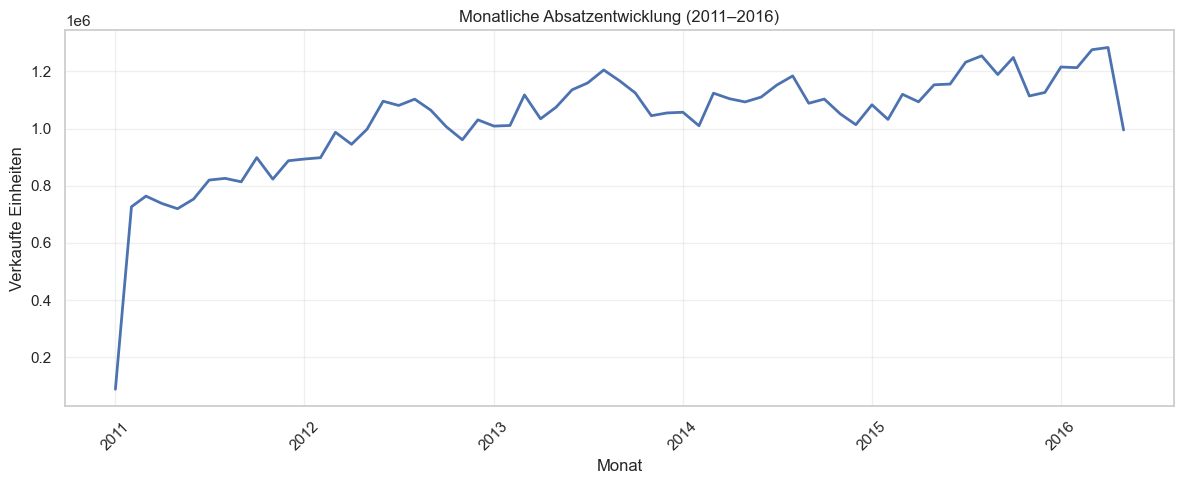

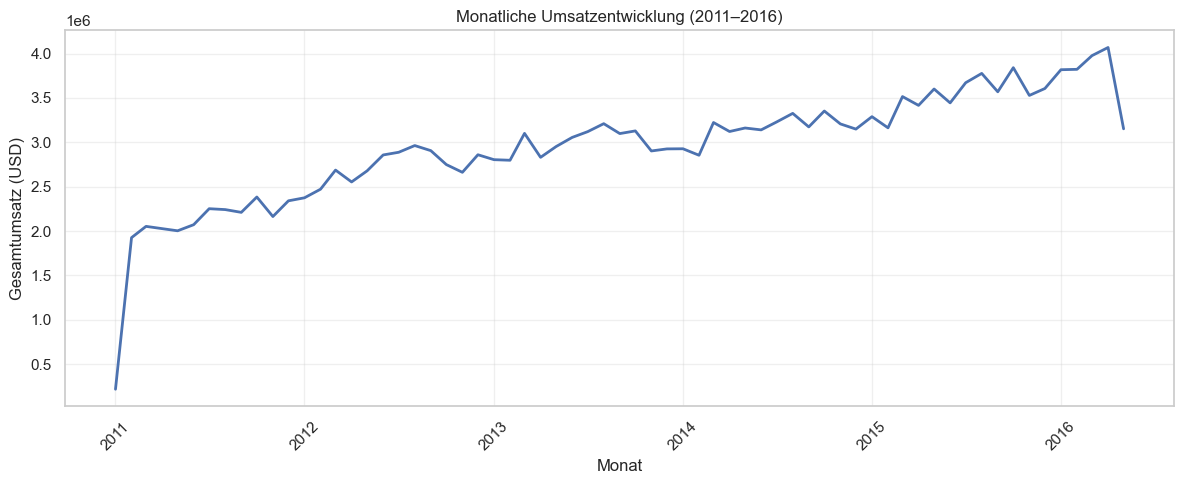

In [110]:
# Visualisierung der monatlichen Absatzentwicklung

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_df["monat"],
    monthly_df["gesamtabsatz"],
    linewidth=2
)

plt.title("Monatliche Absatzentwicklung (2011–2016)")
plt.xlabel("Monat")
plt.ylabel("Verkaufte Einheiten")

plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

# Visualisierung der monatlichen Umsatzentwicklung

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_df["monat"],
    monthly_df["gesamtumsatz_usd"],
    linewidth=2
)

plt.title("Monatliche Umsatzentwicklung (2011–2016)")
plt.xlabel("Monat")
plt.ylabel("Gesamtumsatz (USD)")

plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

Die Visualisierung zeigt zwischen 2011 und 2016 einen
insgesamt steigenden Verlauf der Absatzmengen und Umsätze.

Die monatliche Absatzmenge steigt von ungefähr 700.000
bis 900.000 Einheiten im Jahr 2011 auf teilweise mehr
als 1,2 Millionen Einheiten gegen Ende des
Beobachtungszeitraums.

Auch der monatliche Umsatz entwickelt sich positiv.
Während er 2011 überwiegend bei rund 2 Millionen USD
liegt, erreicht er 2015 und Anfang 2016 teilweise
ungefähr 4 Millionen USD.

Beide Kennzahlen weisen monatliche Schwankungen auf.
Mögliche saisonale Muster werden in den folgenden
Analyseschritten genauer untersucht.

**Einschränkung:** Januar 2011 und Mai 2016 enthalten
keine vollständigen Verkaufsmonate. Die auffälligen
Werte am Anfang und Ende der Zeitreihe sind daher
nur eingeschränkt mit den übrigen Monaten vergleichbar.

### 7.3 Saisonale Verkaufsmuster

Betrachtet werden die vollständigen Kalenderjahre 2012 bis 2015. Da Monate
unterschiedlich viele Tage haben, werden neben den Monatssummen auch die
durchschnittlichen Tagesabsätze je Kalendermonat verglichen.

Berücksichtigte Jahre: [2012, 2013, 2014, 2015]
Anzahl der Monate: 48


,monat_nummer,durchschnittlicher_absatz
0,1,1010515.50
1,2,987571.75
2,3,1086974.25
3,4,1044152.50
4,5,1079633.75
5,6,1124208.00
6,7,1156038.75
7,8,1186509.00
8,9,1127051.50
9,10,1120586.50


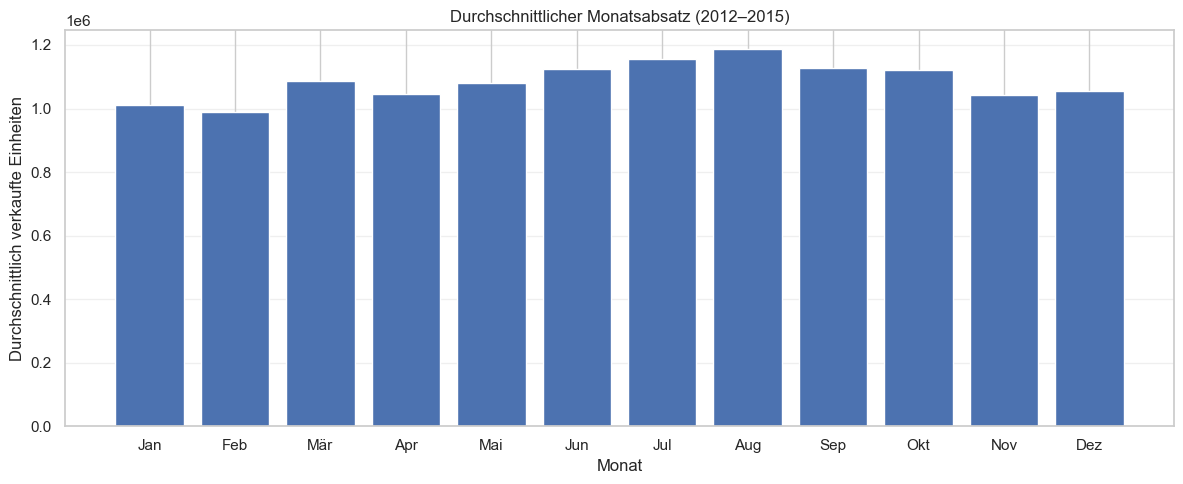

In [113]:
# Auswahl der vollständigen Kalenderjahre

monthly_seasonal = monthly_df.copy()

monthly_seasonal["jahr"] = monthly_seasonal["monat"].dt.year
monthly_seasonal["monat_nummer"] = monthly_seasonal["monat"].dt.month

monthly_seasonal = monthly_seasonal[
    monthly_seasonal["jahr"].between(2012, 2015)
].copy()

# Berechnung des durchschnittlichen monatlichen Absatzes

seasonal_sales = (
    monthly_seasonal
    .groupby("monat_nummer")["gesamtabsatz"]
    .mean()
    .reset_index(name="durchschnittlicher_absatz")
)

print("Berücksichtigte Jahre:", sorted(monthly_seasonal["jahr"].unique()))
print("Anzahl der Monate:", len(monthly_seasonal))

display(seasonal_sales)

# Visualisierung der durchschnittlichen Monatsabsätze

monatsnamen = [
    "Jan", "Feb", "Mär", "Apr", "Mai", "Jun",
    "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"
]

plt.figure(figsize=(12, 5))

plt.bar(
    seasonal_sales["monat_nummer"],
    seasonal_sales["durchschnittlicher_absatz"]
)

plt.title("Durchschnittlicher Monatsabsatz (2012–2015)")
plt.xlabel("Monat")
plt.ylabel("Durchschnittlich verkaufte Einheiten")

plt.xticks(
    range(1, 13),
    monatsnamen
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

,monat_nummer,durchschnittlicher_tagesabsatz
0,1,32597.27
1,2,34993.94
2,3,35063.69
3,4,34805.08
4,5,34826.90
5,6,37473.60
6,7,37291.57
7,8,38274.48
8,9,37568.38
9,10,36147.95


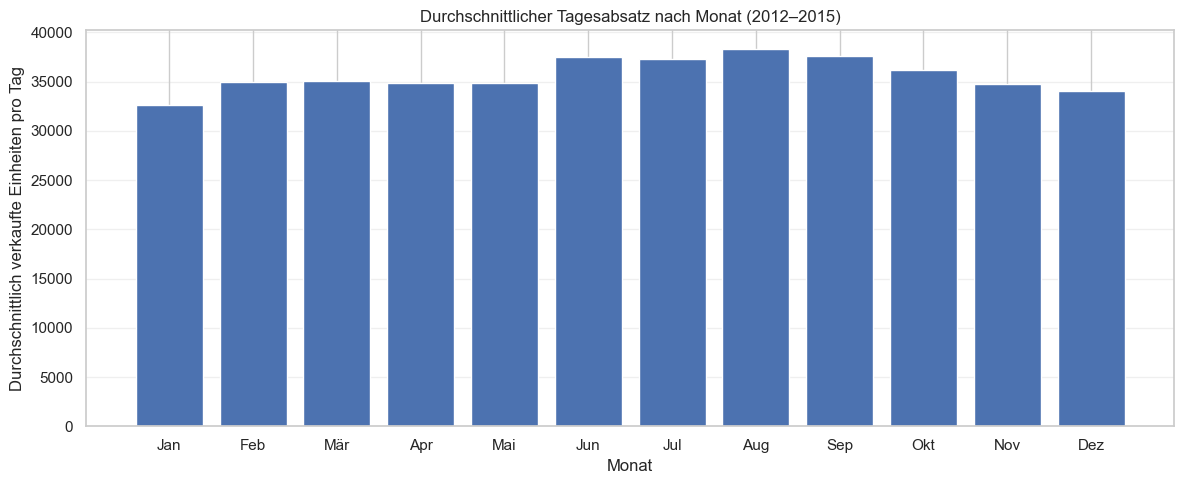

In [114]:
# Berechnung des durchschnittlichen Tagesabsatzes

monthly_seasonal["tage_im_monat"] = (
    monthly_seasonal["monat"].dt.days_in_month
)

monthly_seasonal["tagesabsatz"] = (
    monthly_seasonal["gesamtabsatz"]
    / monthly_seasonal["tage_im_monat"]
)

# Durchschnittlicher Tagesabsatz je Kalendermonat

seasonal_daily_sales = (
    monthly_seasonal
    .groupby("monat_nummer")["tagesabsatz"]
    .mean()
    .reset_index(name="durchschnittlicher_tagesabsatz")
)

display(seasonal_daily_sales.round(2))

# Visualisierung des durchschnittlichen Tagesabsatzes

plt.figure(figsize=(12, 5))

plt.bar(
    seasonal_daily_sales["monat_nummer"],
    seasonal_daily_sales["durchschnittlicher_tagesabsatz"]
)

plt.title("Durchschnittlicher Tagesabsatz nach Monat (2012–2015)")
plt.xlabel("Monat")
plt.ylabel("Durchschnittlich verkaufte Einheiten pro Tag")

plt.xticks(
    range(1, 13),
    monatsnamen
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

Nach Berücksichtigung der unterschiedlichen Monatslängen
zeigt sich, dass der durchschnittliche Tagesabsatz
im August mit rund 38.274 Einheiten am höchsten liegt.

Der niedrigste durchschnittliche Tagesabsatz wird
im Januar mit rund 32.597 Einheiten beobachtet.

Zwischen Juni und September liegen die täglichen
Absatzmengen insgesamt auf einem vergleichsweise
hohen Niveau.

Die Ergebnisse liefern erste Hinweise auf saisonale
Unterschiede im Verkaufsverhalten.

Ob die Muster in jedem einzelnen Jahr auftreten, zeigt der folgende Jahresvergleich.

jahr,2012,2013,2014,2015
monat_nummer,,,,
1,28818.55,32534.19,34097.16,34939.19
2,30965.17,36095.00,36062.86,36852.75
3,31835.29,36050.65,36248.58,36120.23
4,31495.27,34467.87,36809.57,36447.63
5,32185.35,34667.19,35261.03,37194.00
6,36520.30,37853.10,37001.03,38519.97
7,34863.77,37402.16,37153.68,39746.68
8,35573.55,38864.94,38196.84,40462.61
9,35478.80,38883.83,36280.47,39630.43


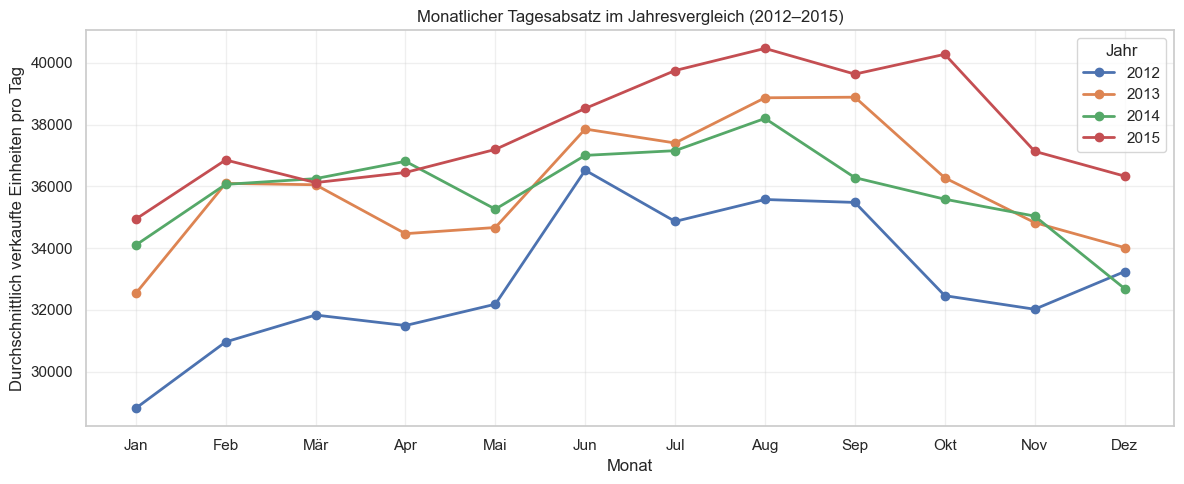

In [116]:
# Vergleich der durchschnittlichen Tagesabsätze nach Jahren

seasonal_comparison = (
    monthly_seasonal
    .pivot(
        index="monat_nummer",
        columns="jahr",
        values="tagesabsatz"
    )
)

display(seasonal_comparison.round(2))

# Visualisierung der saisonalen Muster nach Jahren

plt.figure(figsize=(12, 5))

for jahr in seasonal_comparison.columns:
    plt.plot(
        seasonal_comparison.index,
        seasonal_comparison[jahr],
        marker="o",
        linewidth=2,
        label=str(jahr)
    )

plt.title("Monatlicher Tagesabsatz im Jahresvergleich (2012–2015)")
plt.xlabel("Monat")
plt.ylabel("Durchschnittlich verkaufte Einheiten pro Tag")

plt.xticks(range(1, 13), monatsnamen)

plt.legend(title="Jahr")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

Der Vergleich der Jahre 2012 bis 2015 zeigt sowohl
wiederkehrende saisonale Unterschiede als auch
Veränderungen des allgemeinen Absatzniveaus.

In mehreren Jahren liegen die durchschnittlichen
Tagesabsätze während der Sommermonate auf einem
vergleichsweise hohen Niveau. Besonders der August
weist in den Jahren 2013, 2014 und 2015 die höchsten
durchschnittlichen Tagesabsätze auf.

Gleichzeitig unterscheiden sich die monatlichen
Verlaufsmuster zwischen den Jahren. Im Jahr 2012
wird der höchste Tagesabsatz beispielsweise im
Juni erreicht.

Darüber hinaus ist ein insgesamt steigendes
Absatzniveau zwischen 2012 und 2015 erkennbar.

Die Ergebnisse deuten somit auf saisonale Einflüsse
hin, die von längerfristigen Entwicklungen und
jährlichen Schwankungen überlagert werden.

Für die spätere Absatzprognose sollten deshalb
sowohl saisonale Merkmale als auch zeitliche
Trends berücksichtigt werden. Die tatsächliche
Prognoseleistung dieser Merkmale muss jedoch
anhand zeitlich getrennter Testdaten überprüft werden.

### 7.4 Absatz- und Umsatzanalyse nach Produktkategorien

Verglichen werden Absatzvolumen und Umsatzbeitrag der drei Produktkategorien.

Anzahl der Kategorien: 3


,kategorie,gesamtabsatz,gesamtumsatz_usd,anzahl_produkte
0,FOODS,45922427,1.111400e+08,1437
1,HOUSEHOLD,14764090,5.711588e+07,1047
2,HOBBIES,6240656,2.332164e+07,565


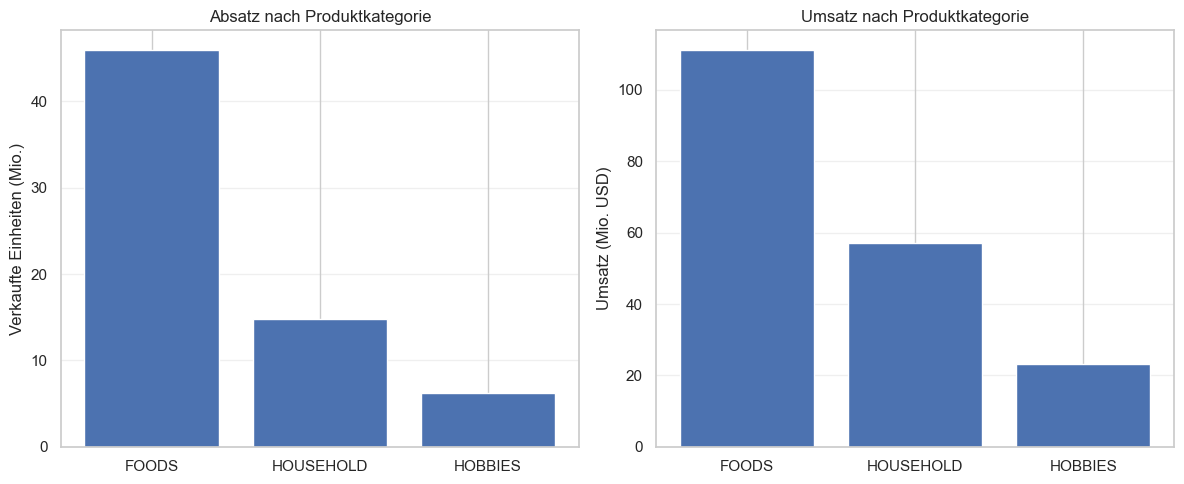

In [119]:
# SQL-Abfrage zur Analyse der Produktkategorien

category_query = """
SELECT
    p.cat_id AS kategorie,
    SUM(f.sales) AS gesamtabsatz,
    ROUND(SUM(f.revenue), 2) AS gesamtumsatz_usd,
    COUNT(DISTINCT p.product_key) AS anzahl_produkte
FROM warehouse.fact_sales AS f
INNER JOIN warehouse.dim_product AS p
    ON f.product_key = p.product_key
GROUP BY p.cat_id
ORDER BY gesamtumsatz_usd DESC;
"""

# Abruf der aggregierten Daten aus PostgreSQL

with psycopg2.connect(**db_config) as conn:
    with conn.cursor() as cursor:
        cursor.execute(category_query)

        category_rows = cursor.fetchall()
        category_columns = [
            beschreibung[0]
            for beschreibung in cursor.description
        ]

category_df = pd.DataFrame(
    category_rows,
    columns=category_columns
)

# Umwandlung der numerischen Spalten

category_df["gesamtumsatz_usd"] = (
    category_df["gesamtumsatz_usd"].astype(float)
)

# Überprüfung der Ergebnisse

print("Anzahl der Kategorien:", len(category_df))
display(category_df)

# Vergleich von Absatz und Umsatz nach Produktkategorie

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Absatz nach Kategorie
axes[0].bar(
    category_df["kategorie"],
    category_df["gesamtabsatz"] / 1_000_000
)
axes[0].set_title("Absatz nach Produktkategorie")
axes[0].set_ylabel("Verkaufte Einheiten (Mio.)")
axes[0].grid(axis="y", alpha=0.3)

# Umsatz nach Kategorie
axes[1].bar(
    category_df["kategorie"],
    category_df["gesamtumsatz_usd"] / 1_000_000
)
axes[1].set_title("Umsatz nach Produktkategorie")
axes[1].set_ylabel("Umsatz (Mio. USD)")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Die Analyse zeigt deutliche Unterschiede zwischen den drei Produktkategorien.

Die Kategorie **FOODS** weist mit 45.922.427 verkauften Einheiten den höchsten Absatz auf. Sie erzielt außerdem einen Gesamtumsatz von rund 111,14 Mio. USD und trägt damit etwa 58,0 % zum Gesamtumsatz bei.

Die Kategorie **HOUSEHOLD** erreicht einen Absatz von rund 14,76 Mio. Einheiten und einen Umsatz von 57,12 Mio. USD. Ihr Umsatzanteil liegt mit etwa 29,8 % über ihrem Absatzanteil von rund 22,1 %.

Die Kategorie **HOBBIES** erzielt rund 6,24 Mio. verkaufte Einheiten und einen Gesamtumsatz von 23,32 Mio. USD.

Die Ergebnisse verdeutlichen, dass sich die Produktkategorien sowohl hinsichtlich ihres Absatzvolumens als auch ihres Umsatzbeitrags unterscheiden.

Aus den Umsatzdaten allein lassen sich jedoch keine Aussagen über die Rentabilität der Kategorien ableiten, da keine Informationen zu Kosten oder Gewinnmargen vorliegen.

### 7.5 Absatz- und Umsatzanalyse nach Filialen und Bundesstaaten

Verglichen werden die zehn Filialen sowie die drei Bundesstaaten.

Anzahl der Filialen: 10


,filiale,bundesstaat,gesamtabsatz,gesamtumsatz_usd
0,CA_3,CA,11363540,32699137.67
1,CA_1,CA,7832248,22954283.77
2,TX_2,TX,7329642,20893002.19
3,TX_3,TX,6205940,18190298.70
4,WI_2,WI,6697988,18131985.02
5,CA_2,CA,5818395,17848209.40
6,WI_3,WI,6542557,17250126.16
7,TX_1,TX,5692823,16037341.14
8,WI_1,WI,5261506,15107433.80
9,CA_4,CA,4182534,12465728.19


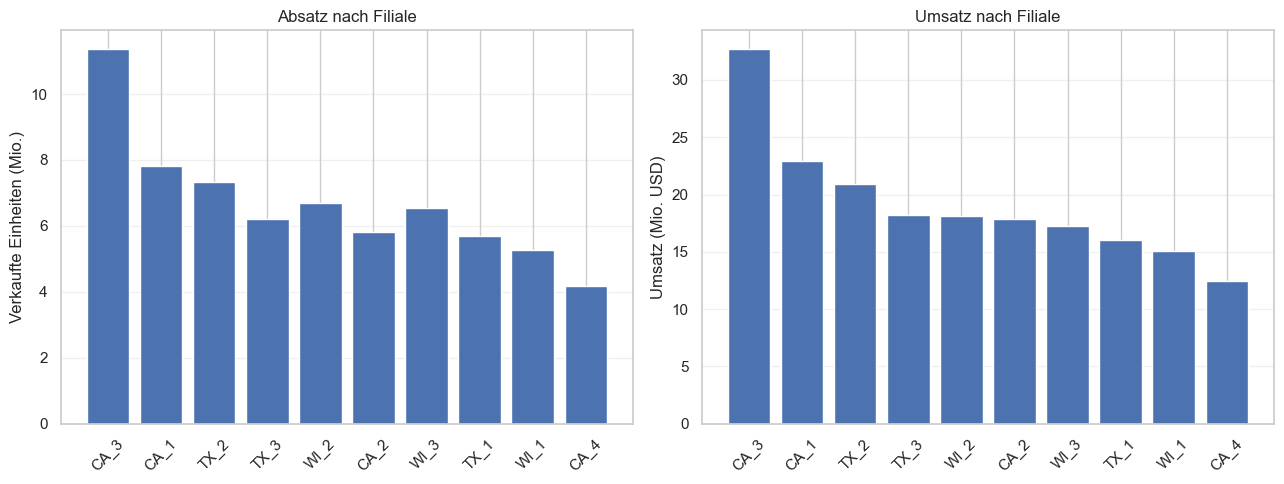

In [122]:
# Import der Filialergebnisse aus PostgreSQL

store_query = """
SELECT
    s.store_id AS filiale,
    s.state_id AS bundesstaat,
    SUM(f.sales) AS gesamtabsatz,
    ROUND(SUM(f.revenue), 2) AS gesamtumsatz_usd
FROM warehouse.fact_sales AS f
INNER JOIN warehouse.dim_store AS s
    ON f.store_key = s.store_key
GROUP BY s.store_id, s.state_id
ORDER BY gesamtumsatz_usd DESC;
"""

with psycopg2.connect(**db_config) as conn:
    with conn.cursor() as cursor:
        cursor.execute(store_query)

        store_rows = cursor.fetchall()
        store_columns = [
            beschreibung[0]
            for beschreibung in cursor.description
        ]

store_df = pd.DataFrame(
    store_rows,
    columns=store_columns
)

store_df["gesamtumsatz_usd"] = (
    store_df["gesamtumsatz_usd"].astype(float)
)

print("Anzahl der Filialen:", len(store_df))
display(store_df)

# Vergleich von Absatz und Umsatz nach Filiale

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(
    store_df["filiale"],
    store_df["gesamtabsatz"] / 1_000_000
)
axes[0].set_title("Absatz nach Filiale")
axes[0].set_ylabel("Verkaufte Einheiten (Mio.)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    store_df["filiale"],
    store_df["gesamtumsatz_usd"] / 1_000_000
)
axes[1].set_title("Umsatz nach Filiale")
axes[1].set_ylabel("Umsatz (Mio. USD)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Die Analyse zeigt deutliche Unterschiede zwischen den zehn Filialen.

Die Filiale CA_3 erzielt mit 11,36 Millionen verkauften Einheiten und
32,70 Millionen USD den höchsten Absatz und Umsatz.

CA_4 weist mit 4,18 Millionen verkauften Einheiten und
12,47 Millionen USD die niedrigsten Werte auf.

Die Umsatzrangfolge entspricht nicht vollständig der Absatzrangfolge.
Dies deutet auf Unterschiede im Produktmix und in den erzielten
Verkaufspreisen hin.

Die Ergebnisse beschreiben die absolute Verkaufsleistung der Filialen.
Ohne Informationen zur Filialgröße oder zu den Betriebskosten lässt sich
daraus keine Aussage über ihre wirtschaftliche Effizienz ableiten.

,bundesstaat,anzahl_filialen,gesamtabsatz,gesamtumsatz_usd
0,CA,4,29196717,85967359.03
1,TX,3,19228405,55120642.03
2,WI,3,18502051,50489544.98


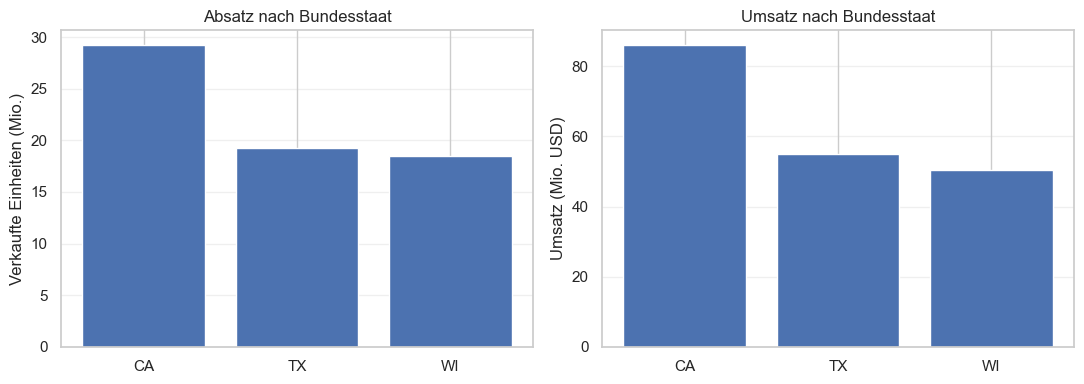

In [124]:
# Import der Ergebnisse nach Bundesstaat aus PostgreSQL

state_query = """
SELECT
    s.state_id AS bundesstaat,
    COUNT(DISTINCT s.store_key) AS anzahl_filialen,
    SUM(f.sales) AS gesamtabsatz,
    ROUND(SUM(f.revenue), 2) AS gesamtumsatz_usd
FROM warehouse.fact_sales AS f
INNER JOIN warehouse.dim_store AS s
    ON f.store_key = s.store_key
GROUP BY s.state_id
ORDER BY gesamtumsatz_usd DESC;
"""

with psycopg2.connect(**db_config) as conn:
    with conn.cursor() as cursor:
        cursor.execute(state_query)
        state_rows = cursor.fetchall()
        state_columns = [
            beschreibung[0]
            for beschreibung in cursor.description
        ]

state_df = pd.DataFrame(state_rows, columns=state_columns)

state_df["gesamtumsatz_usd"] = (
    state_df["gesamtumsatz_usd"].astype(float)
)

display(state_df)

# Vergleich von Absatz und Umsatz nach Bundesstaat

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(
    state_df["bundesstaat"],
    state_df["gesamtabsatz"] / 1_000_000
)
axes[0].set_title("Absatz nach Bundesstaat")
axes[0].set_ylabel("Verkaufte Einheiten (Mio.)")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    state_df["bundesstaat"],
    state_df["gesamtumsatz_usd"] / 1_000_000
)
axes[1].set_title("Umsatz nach Bundesstaat")
axes[1].set_ylabel("Umsatz (Mio. USD)")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Kalifornien (CA) erzielt mit 29,20 Millionen verkauften Einheiten und 85,97 Millionen USD den höchsten Gesamtumsatz. Texas (TX) folgt mit 19,23 Millionen Einheiten und 55,12 Millionen USD, während Wisconsin (WI) 18,50 Millionen Einheiten und 50,49 Millionen USD erreicht.

Bei der Interpretation ist zu berücksichtigen, dass Kalifornien vier Filialen umfasst, Texas und Wisconsin dagegen jeweils drei. Die höheren Gesamtwerte Kaliforniens sind daher nicht unmittelbar als höhere Produktivität zu interpretieren.

Die Analyse verdeutlicht regionale Unterschiede im Absatz und Umsatz und bildet eine Grundlage für die weitere Untersuchung der Nachfrage.

### 7.6 ABC-Analyse der Artikel

Die ABC-Analyse teilt die 3.049 Artikel nach ihrem Umsatzbeitrag in drei Klassen ein:

- **A-Artikel:** erzeugen zusammen 80 % des Umsatzes
- **B-Artikel:** die folgenden 15 % des Umsatzes
- **C-Artikel:** die restlichen 5 % des Umsatzes

Grundlage sind die letzten zwölf Monate des Beobachtungszeitraums
(23.05.2015–22.05.2016), damit das aktuelle Sortiment abgebildet wird.

In [127]:
# ABC-Analyse: Umsatz je Artikel in den letzten zwölf Monaten

abc_query = """
SELECT
    p.item_id,
    p.cat_id,
    SUM(f.sales)   AS absatz,
    SUM(f.revenue) AS umsatz_usd
FROM warehouse.fact_sales AS f
INNER JOIN warehouse.dim_product AS p
    ON f.product_key = p.product_key
INNER JOIN warehouse.dim_date AS d
    ON f.date_key = d.date_key
WHERE d.date BETWEEN DATE '2015-05-23' AND DATE '2016-05-22'
GROUP BY p.item_id, p.cat_id;
"""

with psycopg2.connect(**db_config) as conn:
    with conn.cursor() as cursor:
        cursor.execute(abc_query)
        abc_df = pd.DataFrame(
            cursor.fetchall(),
            columns=[spalte[0] for spalte in cursor.description]
        )

abc_df["absatz"] = abc_df["absatz"].astype("int64")
abc_df["umsatz_usd"] = abc_df["umsatz_usd"].astype(float)

# Sortierung nach Umsatz und kumulierter Umsatzanteil
abc_df = abc_df.sort_values("umsatz_usd", ascending=False).reset_index(drop=True)
abc_df["umsatzanteil_kum"] = abc_df["umsatz_usd"].cumsum() / abc_df["umsatz_usd"].sum()

# Klassengrenzen: A bis 80 %, B bis 95 %, C Rest
abc_df["abc_klasse"] = np.select(
    [abc_df["umsatzanteil_kum"] <= 0.80, abc_df["umsatzanteil_kum"] <= 0.95],
    ["A", "B"],
    default="C"
)

# Übersicht je ABC-Klasse
abc_uebersicht = abc_df.groupby("abc_klasse").agg(
    Artikel=("item_id", "count"),
    Umsatz_USD=("umsatz_usd", "sum")
)
abc_uebersicht["Anteil Artikel (%)"] = abc_uebersicht["Artikel"] / abc_uebersicht["Artikel"].sum() * 100
abc_uebersicht["Anteil Umsatz (%)"] = abc_uebersicht["Umsatz_USD"] / abc_uebersicht["Umsatz_USD"].sum() * 100
abc_uebersicht.index.name = "ABC-Klasse"

display(abc_uebersicht.round(1))

# Verteilung der ABC-Klassen auf die Produktkategorien
display(pd.crosstab(abc_df["cat_id"], abc_df["abc_klasse"],
                    margins=True, margins_name="Gesamt"))

print(
    f"{abc_uebersicht.loc['A', 'Anteil Artikel (%)']:.1f} % der Artikel (Klasse A) "
    f"erzeugen {abc_uebersicht.loc['A', 'Anteil Umsatz (%)']:.1f} % des Umsatzes."
)

,Artikel,Umsatz_USD,Anteil Artikel (%),Anteil Umsatz (%)
ABC-Klasse,,,,
A,1318,36224176.5,43.2,80.0
B,943,6798825.4,30.9,15.0
C,788,2265845.6,25.8,5.0


abc_klasse,A,B,C,Gesamt
cat_id,,,,
FOODS,714,499,224,1437
HOBBIES,170,124,271,565
HOUSEHOLD,434,320,293,1047
Gesamt,1318,943,788,3049


43.2 % der Artikel (Klasse A) erzeugen 80.0 % des Umsatzes.


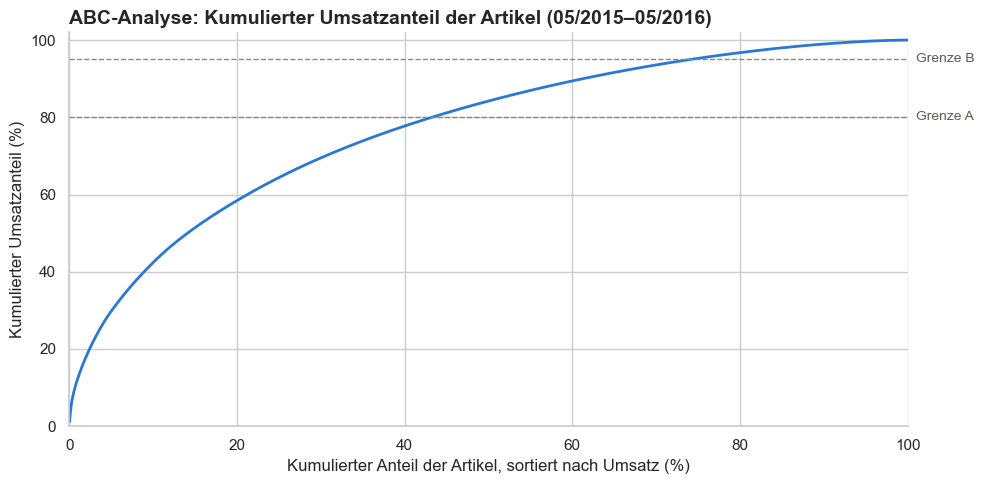

In [128]:
# Visualisierung: Pareto-Kurve der Umsatzkonzentration

artikelanteil_kum = np.arange(1, len(abc_df) + 1) / len(abc_df) * 100

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(artikelanteil_kum, abc_df["umsatzanteil_kum"] * 100, color="#2a78d6", linewidth=2)

for grenze, klasse in [(80, "A"), (95, "B")]:
    ax.axhline(grenze, color="#8a8a85", linewidth=1, linestyle="--")
    ax.text(101, grenze, f"Grenze {klasse}", va="center", fontsize=10, color="#5c5c58")

ax.set_title("ABC-Analyse: Kumulierter Umsatzanteil der Artikel (05/2015–05/2016)",
             fontsize=14, fontweight="bold", loc="left")
ax.set_xlabel("Kumulierter Anteil der Artikel, sortiert nach Umsatz (%)")
ax.set_ylabel("Kumulierter Umsatzanteil (%)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 102)
sns.despine(ax=ax)

plt.tight_layout()
Path("reports").mkdir(exist_ok=True)
fig.savefig("reports/abc_analyse.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** 1.318 Artikel (43,2 %) erzeugen 80 % des Umsatzes, 943 Artikel (30,9 %)
weitere 15 % und 788 Artikel (25,8 %) nur noch 5 %.

Die Konzentration ist damit schwächer als bei der klassischen 20/80-Regel. Der Umsatz
verteilt sich auf eine breite Basis von Artikeln – typisch für ein Lebensmittel-
sortiment mit vielen regelmäßig gekauften Produkten.

Zwischen den Kategorien bestehen deutliche Unterschiede:

- **FOODS:** 714 der 1.437 Artikel (50 %) gehören zur Klasse A; sie stellen mehr als die
  Hälfte aller A-Artikel.
- **HOUSEHOLD:** 434 von 1.047 Artikeln (41 %) sind A-Artikel.
- **HOBBIES:** Nur 170 von 565 Artikeln (30 %) gehören zur Klasse A, fast die Hälfte
  (271 Artikel) zur Klasse C.

**Konsequenz für die Bestandssteuerung:**

- **A-Artikel:** engmaschige Prognose, hoher Servicelevel und regelmäßige Überprüfung,
  da Fehlmengen hier den größten Umsatzverlust verursachen
- **B-Artikel:** standardisierte Disposition mit mittlerem Servicelevel
- **C-Artikel:** vereinfachte Disposition mit niedrigerem Servicelevel – besonders
  relevant für HOBBIES, um Kapitalbindung und Planungsaufwand zu reduzieren

### 7.7 Analyse von Nullabsatz und intermittierender Nachfrage

Ein wichtiger Aspekt der Nachfrageanalyse ist die Häufigkeit von Tagen ohne registrierten Absatz.

Ein hoher Anteil an Nullabsatz kann die Absatzprognose erschweren, insbesondere auf Produkt-Filial-Ebene.

Ziel dieser Analyse ist es, den Anteil der Beobachtungen mit und ohne Absatz zu bestimmen und daraus erste Schlussfolgerungen für die spätere Modellauswahl abzuleiten.

In [131]:
# Anteil der Nullabsätze - getrennt nach gelisteten und nicht gelisteten Artikeln
# (kein Verkaufspreis in der Woche = Artikel in dieser Woche nicht im Sortiment)

zero_query = """
SELECT
    COUNT(*)                                                     AS beobachtungen,
    COUNT(*) FILTER (WHERE sales = 0)                            AS nullabsatz,
    COUNT(*) FILTER (WHERE sell_price IS NULL)                   AS nicht_gelistet,
    COUNT(*) FILTER (WHERE sell_price IS NOT NULL)               AS gelistet,
    COUNT(*) FILTER (WHERE sell_price IS NOT NULL AND sales = 0) AS nullabsatz_gelistet
FROM warehouse.fact_sales;
"""

with psycopg2.connect(**db_config) as conn:
    with conn.cursor() as cursor:
        cursor.execute(zero_query)
        z = dict(zip([c[0] for c in cursor.description], cursor.fetchone()))

nullabsatz_uebersicht = pd.DataFrame({
    "Kennzahl": [
        "Nullabsatz-Anteil (alle Beobachtungen)",
        "Anteil nicht gelisteter Beobachtungen",
        "Nullabsatz-Anteil (nur gelistete Artikel)",
    ],
    "Anteil (%)": [
        z["nullabsatz"] / z["beobachtungen"] * 100,
        z["nicht_gelistet"] / z["beobachtungen"] * 100,
        z["nullabsatz_gelistet"] / z["gelistet"] * 100,
    ],
}).round(2)

display(nullabsatz_uebersicht)

,Kennzahl,Anteil (%)
0,Nullabsatz-Anteil (alle Beobachtungen),68.00
1,Anteil nicht gelisteter Beobachtungen,20.78
2,Nullabsatz-Anteil (nur gelistete Artikel),59.60


Von 59.181.090 Beobachtungen weisen 40.241.819 keinen Absatz auf (68,00 %).

Davon entfallen 12.299.413 Beobachtungen (20,78 % aller Beobachtungen) auf Wochen,
in denen für den Artikel **kein Verkaufspreis** vorliegt. In diesen Wochen war der
Artikel in der Filiale vermutlich noch nicht gelistet. Diese Nullwerte beschreiben
daher keine fehlende Nachfrage, sondern ein fehlendes Angebot.

Betrachtet man nur gelistete Artikel, sinkt der Nullabsatz-Anteil auf **59,60 %**.
Die Nachfrage bleibt damit auf Produkt-Filial-Ebene stark intermittierend.

**Konsequenz für die Modellierung:** Bei Prognosen auf Artikelebene sollten
nicht gelistete Zeiträume ausgeschlossen werden. Für intermittierende Artikel
eignen sich spezielle Verfahren (z. B. Croston oder TSB).

### 7.8 Schlussfolgerungen der explorativen Datenanalyse

Die explorative Datenanalyse zeigt folgende zentrale Ergebnisse:

- **Zeitliche Entwicklung:** Absatz und Umsatz weisen im Untersuchungszeitraum insgesamt eine steigende Entwicklung auf.
- **Saisonale Muster:** Die durchschnittlichen Tagesabsätze unterscheiden sich nach Kalendermonat. Besonders hohe Werte wurden im Sommer beobachtet.
- **Produktkategorien:** Die Kategorie FOODS erzielt den höchsten Gesamtabsatz und Gesamtumsatz.
- **Regionale Unterschiede:** Kalifornien (CA) weist den höchsten Gesamtabsatz und Gesamtumsatz auf. Dabei ist zu berücksichtigen, dass CA vier Filialen umfasst, TX und WI hingegen jeweils drei.
- **ABC-Analyse:** 43,2 % der Artikel erzeugen 80 % des Umsatzes. FOODS stellt mehr als die Hälfte der A-Artikel, HOBBIES besteht zu fast der Hälfte aus C-Artikeln.
- **Nullabsatz:** Von insgesamt 59.181.090 Beobachtungen weisen 40.241.819 keinen registrierten Absatz auf. Dies entspricht **68,00 %**. Rund 12,3 Mio. dieser Nullwerte entfallen auf nicht gelistete Artikel; bei gelisteten Artikeln liegt der Anteil bei **59,60 %**.

**Implikationen für die Absatzprognose**

Der hohe Nullabsatzanteil deutet auf eine teilweise intermittierende Absatzstruktur hin. Für die spätere Prognose sind daher geeignete Vergleichsmodelle und eine zeitbasierte Validierung erforderlich.

Ein registrierter Nullabsatz ist nicht zwingend mit fehlender Nachfrage gleichzusetzen, da keine vollständigen Informationen über mögliche Lagerengpässe vorliegen.

Die Ergebnisse bilden die Grundlage für die Entwicklung und Bewertung der Prognosemodelle im nächsten Kapitel.

## 8. Demand Forecasting

### 8.1 Zielsetzung und Prognosestrategie

Ziel dieses Kapitels ist die Entwicklung und Bewertung von Prognosemodellen zur Vorhersage zukünftiger Verkaufszahlen.

Als Datengrundlage dienen die historischen Verkaufsdaten des M5-Datensatzes vom 29.01.2011 bis zum 22.05.2016.

Die Zielvariable ist die Anzahl der verkauften Einheiten (`sales`). Da keine vollständigen Informationen zu Lagerbeständen und Lieferengpässen vorliegen, wird der beobachtete Absatz prognostiziert und nicht die tatsächlich unbeobachtete Kundennachfrage.

Die Prognose erfolgt zunächst auf aggregierter Tagesebene. Dadurch können die Modellierungsstrategie und die zeitbasierte Validierung ressourcenschonend überprüft werden. Eine spätere Erweiterung auf einzelne Produkte oder Filialen bleibt möglich.

Zur Bewertung werden ein einfaches Baseline-Modell und ein weiterführendes Prognosemodell verglichen. Die Daten werden chronologisch aufgeteilt, um Informationslecks aus zukünftigen Beobachtungen zu vermeiden.

Die Prognoseergebnisse bilden anschließend die Grundlage für die Bestandsoptimierung.

### 8.2 Datengrundlage der Prognose

Der tägliche Gesamtabsatz wird per SQL aus dem Data Warehouse geladen
und auf Vollständigkeit geprüft.

In [136]:
# Tägliche Absatzdaten aus PostgreSQL laden

daily_sales_query = """
SELECT
    d.date AS datum,
    SUM(f.sales) AS tagesabsatz
FROM warehouse.fact_sales AS f
INNER JOIN warehouse.dim_date AS d
    ON f.date_key = d.date_key
GROUP BY d.date
ORDER BY d.date;
"""

with psycopg2.connect(**db_config) as conn:
    with conn.cursor() as cursor:
        cursor.execute(daily_sales_query)
        daily_rows = cursor.fetchall()

daily_sales_df = pd.DataFrame(
    daily_rows,
    columns=["datum", "tagesabsatz"]
)

daily_sales_df["datum"] = pd.to_datetime(daily_sales_df["datum"])
daily_sales_df["tagesabsatz"] = daily_sales_df["tagesabsatz"].astype("int64")

print("Anzahl der Tage:", len(daily_sales_df))
print("Zeitraum:", daily_sales_df["datum"].min(), "bis",
      daily_sales_df["datum"].max())

display(daily_sales_df.head())

# Überprüfung der täglichen Zeitreihe

erwartete_tage = pd.date_range(
    start=daily_sales_df["datum"].min(),
    end=daily_sales_df["datum"].max(),
    freq="D"
)

fehlende_tage = erwartete_tage.difference(daily_sales_df["datum"])

print("Fehlende Tage:", len(fehlende_tage))
print("Doppelte Datumswerte:", daily_sales_df["datum"].duplicated().sum())
print("Fehlende Absatzwerte:", daily_sales_df["tagesabsatz"].isna().sum())
print("Negative Absatzwerte:", (daily_sales_df["tagesabsatz"] < 0).sum())
print("Gesamtabsatz:", daily_sales_df["tagesabsatz"].sum())

Anzahl der Tage: 1941
Zeitraum: 2011-01-29 00:00:00 bis 2016-05-22 00:00:00


,datum,tagesabsatz
0,2011-01-29,32631
1,2011-01-30,31749
2,2011-01-31,23783
3,2011-02-01,25412
4,2011-02-02,19146


Fehlende Tage: 0
Doppelte Datumswerte: 0
Fehlende Absatzwerte: 0
Negative Absatzwerte: 0
Gesamtabsatz: 66927173


### 8.3 Chronologische Aufteilung der Daten

Für die Entwicklung und Bewertung der Prognosemodelle wird die tägliche Absatzzeitreihe chronologisch in Trainings-, Validierungs- und Testdaten aufgeteilt.

- **Trainingsdaten:** 29.01.2011 bis 22.01.2016
- **Validierungsdaten:** 23.01.2016 bis 19.02.2016 (28 Tage)
- **Testdaten:** 20.02.2016 bis 22.05.2016 (93 Tage)

Die Trainingsdaten dienen der Modellentwicklung, die Validierungsdaten der Modellauswahl und die Testdaten der abschließenden Bewertung.

Durch die zeitliche Trennung wird verhindert, dass zukünftige Verkaufsinformationen in das Modelltraining einfließen.

In [138]:
# Chronologische Aufteilung der täglichen Absatzdaten

train_df = daily_sales_df[
    daily_sales_df["datum"] < "2016-01-23"
].copy()

val_df = daily_sales_df[
    (daily_sales_df["datum"] >= "2016-01-23")
    & (daily_sales_df["datum"] < "2016-02-20")
].copy()

test_df = daily_sales_df[
    daily_sales_df["datum"] >= "2016-02-20"
].copy()

# Überprüfung der Aufteilung
for name, df in [
    ("Training", train_df),
    ("Validierung", val_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {len(df)} Tage | "
        f"{df['datum'].min().date()} bis "
        f"{df['datum'].max().date()}"
    )

print(
    "\nVollständige Aufteilung:",
    len(train_df) + len(val_df) + len(test_df)
    == len(daily_sales_df)
)

Training: 1820 Tage | 2011-01-29 bis 2016-01-22
Validierung: 28 Tage | 2016-01-23 bis 2016-02-19
Test: 93 Tage | 2016-02-20 bis 2016-05-22

Vollständige Aufteilung: True


### 8.4 Saisonales Baseline-Modell

Als Referenzmodell wird eine saisonale Naive-Prognose mit einer Periodenlänge von sieben Tagen verwendet.

Dabei wird angenommen, dass der Absatz eines Tages dem Absatz des gleichen Wochentags in der Vorwoche entspricht.

Für die Validierungsperiode wird eine rekursive Prognose erstellt. Dabei werden ausschließlich Absatzwerte verwendet, die vor Beginn der Validierungsperiode bekannt waren.

Die Modellgüte wird anhand des Mean Absolute Error (MAE) und des Root Mean Squared Error (RMSE) bewertet.

In [140]:
# Saisonale Naive-Prognose für die Validierungsperiode

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Letzte sieben bekannte Tagesabsätze aus dem Training
letzte_woche = train_df["tagesabsatz"].tail(7).to_numpy()

# Wiederholung des wöchentlichen Musters für 28 Tage
baseline_val_pred = np.tile(
    letzte_woche,
    int(np.ceil(len(val_df) / 7))
)[:len(val_df)]

# Tatsächliche Werte
y_val = val_df["tagesabsatz"].to_numpy()

# Bewertungsmetriken
baseline_val_mae = mean_absolute_error(y_val, baseline_val_pred)
baseline_val_rmse = np.sqrt(
    mean_squared_error(y_val, baseline_val_pred)
)

print("Saisonale Naive-Prognose – Validierung")
print(f"MAE:  {baseline_val_mae:,.2f}")
print(f"RMSE: {baseline_val_rmse:,.2f}")

Saisonale Naive-Prognose – Validierung
MAE:  4,050.43
RMSE: 4,824.20


### 8.5 Machine-Learning-Modell

Als weiterführendes Prognosemodell wird ein Gradient-Boosting-Regressionsmodell eingesetzt.

Das Modell berücksichtigt kalendarische Merkmale sowie historische Absatzinformationen. Ziel ist es, wiederkehrende Muster und zeitliche Abhängigkeiten besser abzubilden als das saisonale Baseline-Modell.

Für die Validierungsperiode wird eine rekursive Mehrschrittprognose erstellt. Dabei werden keine tatsächlichen Absatzwerte aus der Validierungsperiode als Eingangsvariablen verwendet.

Die Ergebnisse werden anhand von MAE und RMSE mit dem Baseline-Modell verglichen.

In [142]:
# Vorbereitung der Merkmale für das Prognosemodell

forecast_df = daily_sales_df.copy()

# Kalendermerkmale
forecast_df["wochentag"] = forecast_df["datum"].dt.dayofweek
forecast_df["monat"] = forecast_df["datum"].dt.month
forecast_df["tag_im_jahr"] = forecast_df["datum"].dt.dayofyear

# Historische Absatzmerkmale
forecast_df["lag_7"] = forecast_df["tagesabsatz"].shift(7)
forecast_df["lag_14"] = forecast_df["tagesabsatz"].shift(14)
forecast_df["lag_28"] = forecast_df["tagesabsatz"].shift(28)

# Gleitender Durchschnitt ausschließlich vergangener Werte
forecast_df["rolling_mean_7"] = (
    forecast_df["tagesabsatz"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

# Fehlende Anfangszeilen entfernen
forecast_df = forecast_df.dropna().reset_index(drop=True)

print("Anzahl der Beobachtungen:", len(forecast_df))
print("Anzahl der Variablen:", forecast_df.shape[1])

display(forecast_df.head())

# Training des Gradient-Boosting-Modells

from sklearn.ensemble import HistGradientBoostingRegressor

# Auswahl der Prognosemerkmale
feature_cols = [
    "wochentag",
    "monat",
    "tag_im_jahr",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7"
]

# Ausschließlich historische Trainingsdaten verwenden
ml_train_df = forecast_df[
    forecast_df["datum"] < "2016-01-23"
].copy()

X_train = ml_train_df[feature_cols]
y_train = ml_train_df["tagesabsatz"]

# Modell initialisieren und trainieren
ml_model = HistGradientBoostingRegressor(
    max_iter=200,
    max_leaf_nodes=15,
    learning_rate=0.05,
    l2_regularization=1.0,
    random_state=42
)

ml_model.fit(X_train, y_train)

print("Modelltraining abgeschlossen.")
print("Trainingsbeobachtungen:", len(X_train))
print("Anzahl der Merkmale:", len(feature_cols))
print("Trainingszeitraum:",
      ml_train_df["datum"].min().date(),
      "bis",
      ml_train_df["datum"].max().date())

# Rekursive Prognose für die Validierungsperiode

# Bekannte Absatzwerte bis zum Ende des Trainingszeitraums
historische_absatzwerte = train_df["tagesabsatz"].astype(float).tolist()

ml_val_predictions = []

for datum in val_df["datum"]:

    # Kalendermerkmale
    wochentag = datum.dayofweek
    monat = datum.month
    tag_im_jahr = datum.dayofyear

    # Historische Merkmale
    lag_7 = historische_absatzwerte[-7]
    lag_14 = historische_absatzwerte[-14]
    lag_28 = historische_absatzwerte[-28]
    rolling_mean_7 = np.mean(historische_absatzwerte[-7:])

    # Merkmale für den aktuellen Prognosetag
    X_next = pd.DataFrame([{
        "wochentag": wochentag,
        "monat": monat,
        "tag_im_jahr": tag_im_jahr,
        "lag_7": lag_7,
        "lag_14": lag_14,
        "lag_28": lag_28,
        "rolling_mean_7": rolling_mean_7
    }], columns=feature_cols)

    # Tagesprognose
    prognose = float(ml_model.predict(X_next)[0])

    # Negative Absatzprognosen vermeiden
    prognose = max(0.0, prognose)

    ml_val_predictions.append(prognose)

    # Prognose für die nächsten Tage verfügbar machen
    historische_absatzwerte.append(prognose)

# Bewertung auf den 28 Validierungstagen
ml_val_pred = np.array(ml_val_predictions)

ml_val_mae = mean_absolute_error(y_val, ml_val_pred)
ml_val_rmse = np.sqrt(mean_squared_error(y_val, ml_val_pred))

print("Gradient Boosting – Validierung")
print(f"MAE:  {ml_val_mae:,.2f}")
print(f"RMSE: {ml_val_rmse:,.2f}")

Anzahl der Beobachtungen: 1913
Anzahl der Variablen: 9


,datum,tagesabsatz,wochentag,monat,tag_im_jahr,lag_7,lag_14,lag_28,rolling_mean_7
0,2011-02-26,29908,5,2,57,31689.0,34833.0,32631.0,24143.142857
1,2011-02-27,28707,6,2,58,29283.0,36380.0,31749.0,23888.714286
2,2011-02-28,21240,0,2,59,23966.0,21804.0,23783.0,23806.428571
3,2011-03-01,22872,1,3,60,20501.0,24070.0,25412.0,23417.000000
4,2011-03-02,22046,2,3,61,20757.0,21443.0,19146.0,23755.714286


Modelltraining abgeschlossen.
Trainingsbeobachtungen: 1792
Anzahl der Merkmale: 7
Trainingszeitraum: 2011-02-26 bis 2016-01-22
Gradient Boosting – Validierung
MAE:  3,182.16
RMSE: 3,736.51


### 8.6 Modellevaluation und Vergleich

Auf den Validierungsdaten erzielt das Gradient-Boosting-Modell
niedrigere Prognosefehler als das saisonale Baseline-Modell.

Für die abschließende Bewertung wird das ausgewählte Modell
auf den bis zum Testbeginn verfügbaren Daten neu trainiert.

Anschließend werden beide Modelle auf der unabhängigen
Testperiode verglichen. Die Prognosen werden ohne Verwendung
tatsächlicher Absatzwerte aus der Testperiode erstellt.

In [144]:
# Gradient-Boosting-Modell für die Testphase neu trainieren

# Trainings- und Validierungsdaten zusammenführen
ml_train_val_df = forecast_df[
    forecast_df["datum"] < "2016-02-20"
].copy()

X_train_val = ml_train_val_df[feature_cols]
y_train_val = ml_train_val_df["tagesabsatz"]

# Neues Modell mit denselben Hyperparametern
ml_final_model = HistGradientBoostingRegressor(
    max_iter=200,
    max_leaf_nodes=15,
    learning_rate=0.05,
    l2_regularization=1.0,
    random_state=42
)

ml_final_model.fit(X_train_val, y_train_val)

print("Finales Modelltraining abgeschlossen.")
print("Trainingsbeobachtungen:", len(X_train_val))
print("Anzahl der Merkmale:", len(feature_cols))
print(
    "Trainingszeitraum:",
    ml_train_val_df["datum"].min().date(),
    "bis",
    ml_train_val_df["datum"].max().date()
)

# Prognosen für die unabhängige Testperiode

# Bekannte Absatzwerte vor Beginn der Testperiode
train_val_sales = pd.concat([
    train_df["tagesabsatz"],
    val_df["tagesabsatz"]
]).astype(float).tolist()

# 1. Saisonale Naive-Prognose
letzte_woche_test = np.array(train_val_sales[-7:])

baseline_test_pred = np.tile(
    letzte_woche_test,
    int(np.ceil(len(test_df) / 7))
)[:len(test_df)]

# 2. Rekursive Gradient-Boosting-Prognose
historische_absatzwerte_test = train_val_sales.copy()
ml_test_predictions = []

for datum in test_df["datum"]:

    X_next = pd.DataFrame([{
        "wochentag": datum.dayofweek,
        "monat": datum.month,
        "tag_im_jahr": datum.dayofyear,
        "lag_7": historische_absatzwerte_test[-7],
        "lag_14": historische_absatzwerte_test[-14],
        "lag_28": historische_absatzwerte_test[-28],
        "rolling_mean_7": np.mean(
            historische_absatzwerte_test[-7:]
        )
    }], columns=feature_cols)

    prognose = max(
        0.0,
        float(ml_final_model.predict(X_next)[0])
    )

    ml_test_predictions.append(prognose)
    historische_absatzwerte_test.append(prognose)

# 3. Bewertung beider Modelle
y_test = test_df["tagesabsatz"].to_numpy()
ml_test_pred = np.array(ml_test_predictions)

ergebnisse_test = pd.DataFrame({
    "Modell": ["Seasonal Naive", "Gradient Boosting"],
    "MAE": [
        mean_absolute_error(y_test, baseline_test_pred),
        mean_absolute_error(y_test, ml_test_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_test_pred)),
        np.sqrt(mean_squared_error(y_test, ml_test_pred))
    ]
})

print("Modellvergleich – Testperiode (93 Tage)")
display(ergebnisse_test.round(2))

Finales Modelltraining abgeschlossen.
Trainingsbeobachtungen: 1820
Anzahl der Merkmale: 7
Trainingszeitraum: 2011-02-26 bis 2016-02-19
Modellvergleich – Testperiode (93 Tage)


,Modell,MAE,RMSE
0,Seasonal Naive,3204.72,4091.03
1,Gradient Boosting,2790.93,3715.20


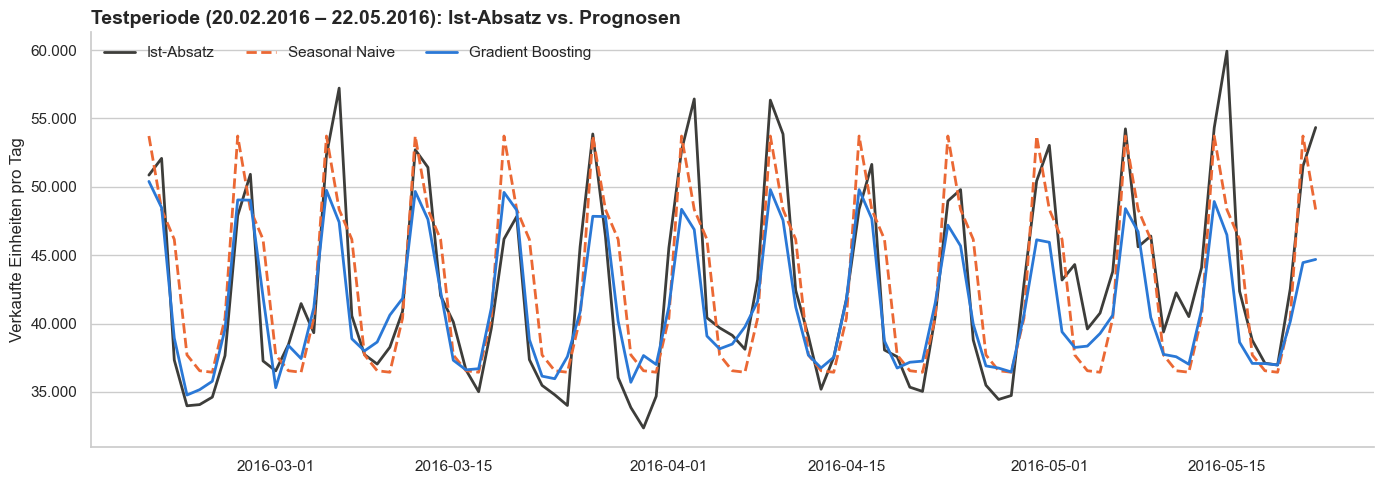

In [145]:
# Visualisierung: Ist-Absatz und Prognosen in der Testperiode

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(test_df["datum"], y_test, color="#3d3d3a", linewidth=2, label="Ist-Absatz")
ax.plot(test_df["datum"], baseline_test_pred, color="#eb6834", linewidth=2,
        linestyle="--", label="Seasonal Naive")
ax.plot(test_df["datum"], ml_test_pred, color="#2a78d6", linewidth=2,
        label="Gradient Boosting")

ax.set_title("Testperiode (20.02.2016 – 22.05.2016): Ist-Absatz vs. Prognosen",
             fontsize=14, fontweight="bold", loc="left")
ax.set_xlabel("")
ax.set_ylabel("Verkaufte Einheiten pro Tag")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
ax.legend(frameon=False, loc="upper left", ncol=3)
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)

plt.tight_layout()

Path("reports").mkdir(exist_ok=True)
fig.savefig("reports/forecast_testperiode.png", dpi=150, bbox_inches="tight")
plt.show()

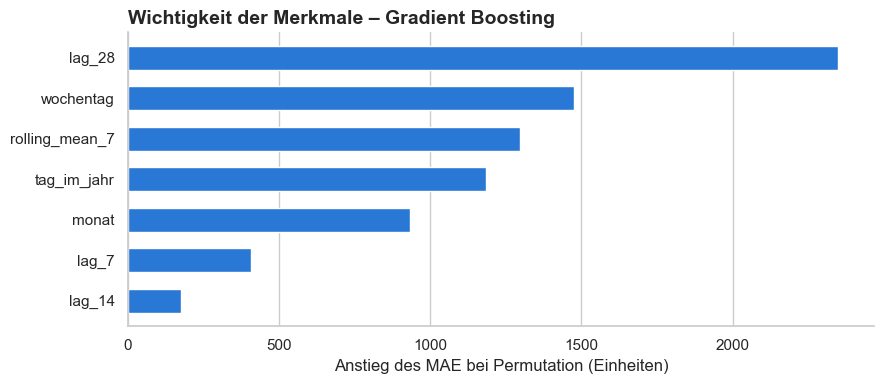

In [146]:
# Bedeutung der Merkmale (Permutation Importance)
# HistGradientBoosting bietet keine eingebaute Feature Importance,
# daher wird die Permutationsmethode auf den Trainingsdaten verwendet.

from sklearn.inspection import permutation_importance

perm = permutation_importance(
    ml_final_model, X_train_val, y_train_val,
    scoring="neg_mean_absolute_error",
    n_repeats=10, random_state=42
)

importance_df = (
    pd.DataFrame({"Merkmal": feature_cols, "MAE-Anstieg": perm.importances_mean})
    .sort_values("MAE-Anstieg")
)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(importance_df["Merkmal"], importance_df["MAE-Anstieg"], color="#2a78d6", height=0.6)
ax.set_title("Wichtigkeit der Merkmale – Gradient Boosting",
             fontsize=14, fontweight="bold", loc="left")
ax.set_xlabel("Anstieg des MAE bei Permutation (Einheiten)")
ax.grid(axis="y", visible=False)
sns.despine(ax=ax)

plt.tight_layout()
fig.savefig("reports/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.7 Fazit der Prognosemodellierung

Im Rahmen der Absatzprognose wurden zwei Modelle entwickelt und
anhand einer chronologischen Datenaufteilung bewertet:
ein saisonales Naive-Modell und ein Gradient-Boosting-Modell.

Auf der unabhängigen Testperiode von 93 Tagen erzielte das
Gradient-Boosting-Modell einen MAE von 2.790,93 und einen
RMSE von 3.715,20 verkauften Einheiten.

Im Vergleich zum saisonalen Baseline-Modell entspricht dies
einer Verbesserung von 12,9 % beim MAE und 9,2 % beim RMSE.

Damit wird Gradient Boosting als bevorzugtes Prognosemodell
für die weitere Analyse ausgewählt.

Im Mai 2016 liegt der MAE des Gradient-Boosting-Modells mit rund 4.185 Einheiten
jedoch über dem des Baseline-Modells (rund 3.281). Mit zunehmendem Prognosehorizont
summieren sich die Fehler der rekursiven Prognose.

**Einschränkungen:**
- Die Prognose erfolgt auf aggregierter Tagesebene und
  nicht auf Produkt- oder Filialebene.
- Bei längeren Prognosehorizonten können sich Fehler
  durch die rekursive Vorhersage verstärken.
- Da keine vollständigen Bestands- und Fehlmengendaten
  vorliegen, wird der beobachtete Absatz und nicht die
  unbeobachtete Kundennachfrage prognostiziert.

Die Prognoseergebnisse dienen im nächsten Kapitel als
Grundlage für eine simulationsbasierte Bestandsoptimierung.

## 9. Inventory Optimization

### 9.1 Zielsetzung und Annahmen

Ziel dieses Kapitels ist es, die Ergebnisse der Absatzprognose
für die simulationsbasierte Bestandsplanung zu nutzen.

Auf Grundlage der prognostizierten Verkaufszahlen werden
zentrale Kennzahlen der Bestandssteuerung berechnet:

- Durchschnittlicher Tagesbedarf
- Sicherheitsbestand (Safety Stock)
- Meldebestand (Reorder Point)

Da der M5-Datensatz keine vollständigen Informationen über
tatsächliche Lagerbestände, Lieferzeiten oder Fehlmengen enthält,
werden die Berechnungen unter vereinfachten Annahmen durchgeführt.

**Annahmen der Simulation:**

- Die prognostizierten Verkaufszahlen dienen als Näherung
  für den zukünftigen Bedarf.
- Die Lieferzeit beträgt konstant 7 Tage.
- Das angestrebte Servicelevel beträgt 95 %.
- Die Bestandsplanung erfolgt zunächst auf aggregierter Ebene
  über alle Produkte und Filialen.
- Tatsächliche Lagerbestände werden nicht modelliert. Kostensätze
  für die Optimierung werden in Abschnitt 9.5 angenommen.

Die Ergebnisse stellen somit eine modellbasierte
Planungssimulation und keine Optimierung realer Lagerbestände dar.

In [149]:
# Grundparameter der Bestandsplanung

import numpy as np

# Simulationsannahmen
lieferzeit_tage = 7
servicelevel = 0.95
z_wert = 1.645

# Prognostizierter durchschnittlicher Tagesbedarf
durchschnittlicher_tagesbedarf = np.mean(ml_test_pred)

# Prognostizierter Bedarf während der Lieferzeit
bedarf_lieferzeit = (
    durchschnittlicher_tagesbedarf * lieferzeit_tage
)

print("Grundparameter der Bestandsplanung")
print(f"Lieferzeit: {lieferzeit_tage} Tage")
print(f"Servicelevel: {servicelevel:.0%}")
print(f"Z-Wert: {z_wert}")
print()
print(
    f"Durchschnittlicher Tagesbedarf: "
    f"{durchschnittlicher_tagesbedarf:,.2f} Einheiten"
)
print(
    f"Bedarf während der Lieferzeit: "
    f"{bedarf_lieferzeit:,.2f} Einheiten"
)

Grundparameter der Bestandsplanung
Lieferzeit: 7 Tage
Servicelevel: 95%
Z-Wert: 1.645

Durchschnittlicher Tagesbedarf: 41,342.02 Einheiten
Bedarf während der Lieferzeit: 289,394.11 Einheiten


### 9.2 Berechnung von Sicherheits- und Meldebestand

Der Sicherheitsbestand wird aus der Streuung der Prognosefehler
der Validierungsperiode abgeleitet:

Sicherheitsbestand = z × σ(Prognosefehler) × √Lieferzeit

Meldebestand = Bedarf während der Lieferzeit + Sicherheitsbestand

In [151]:
# Sicherheitsbestand und Meldebestand berechnen

# Prognosefehler aus der Validierungsperiode
validierungsfehler = y_val - ml_val_pred

# Standardabweichung der Prognosefehler
prognosefehler_std = np.std(validierungsfehler, ddof=1)

# Sicherheitsbestand bei konstanter Lieferzeit
sicherheitsbestand = (
    z_wert
    * prognosefehler_std
    * np.sqrt(lieferzeit_tage)
)

# Meldebestand
meldebestand = bedarf_lieferzeit + sicherheitsbestand

print("Bestandskennzahlen – Simulation")
print(f"Prognosefehler (Standardabweichung): {prognosefehler_std:,.2f} Einheiten")
print(f"Sicherheitsbestand: {np.ceil(sicherheitsbestand):,.0f} Einheiten")
print(f"Meldebestand: {np.ceil(meldebestand):,.0f} Einheiten")

Bestandskennzahlen – Simulation
Prognosefehler (Standardabweichung): 2,708.40 Einheiten
Sicherheitsbestand: 11,788 Einheiten
Meldebestand: 301,182 Einheiten


### 9.3 Sensitivitätsanalyse

Zur Untersuchung der Auswirkungen unterschiedlicher
Servicelevel werden drei Szenarien betrachtet:
90 %, 95 % und 99 %.

Für alle Szenarien wird eine konstante Lieferzeit
von sieben Tagen angenommen.

Die Sensitivitätsanalyse zeigt, wie sich ein höheres
angestrebtes Servicelevel auf den Sicherheitsbestand
und den Meldebestand auswirkt.

In [153]:
# Sensitivitätsanalyse für unterschiedliche Servicelevel

servicelevel_szenarien = {
    "90 %": 1.282,
    "95 %": 1.645,
    "99 %": 2.326
}

szenario_ergebnisse = []

for servicelevel_name, z in servicelevel_szenarien.items():

    sicherheitsbestand_szenario = (
        z * prognosefehler_std * np.sqrt(lieferzeit_tage)
    )

    meldebestand_szenario = (
        bedarf_lieferzeit + sicherheitsbestand_szenario
    )

    szenario_ergebnisse.append({
        "Servicelevel": servicelevel_name,
        "Sicherheitsbestand": int(np.ceil(sicherheitsbestand_szenario)),
        "Meldebestand": int(np.ceil(meldebestand_szenario))
    })

szenario_df = pd.DataFrame(szenario_ergebnisse)

print("Sensitivitätsanalyse – Servicelevel")
display(szenario_df)

Sensitivitätsanalyse – Servicelevel


,Servicelevel,Sicherheitsbestand,Meldebestand
0,90 %,9187,298581
1,95 %,11788,301182
2,99 %,16668,306062


### 9.4 Bestandsplanung je Produktkategorie

Ein einziger Sicherheitsbestand für alle Artikel ist für die Disposition nur
eingeschränkt aussagekräftig. Daher wird die Planung auf die drei Produktkategorien
heruntergebrochen.

**Vorgehen (Top-down-Prognose):** Die Gesamtprognose des Gradient-Boosting-Modells
wird anhand der Absatzanteile der Kategorien auf die Kategorien verteilt. Die Anteile
stammen aus den 365 Tagen vor Beginn der Validierungsperiode (23.01.2015–22.01.2016),
sodass keine Informationen aus Validierungs- oder Testperiode einfließen.
Die Streuung der Prognosefehler wird je Kategorie auf der Validierungsperiode ermittelt.

In [155]:
# Täglicher Absatz und Umsatz je Kategorie

kategorie_query = """
SELECT
    d.date         AS datum,
    p.cat_id       AS kategorie,
    SUM(f.sales)   AS absatz,
    SUM(f.revenue) AS umsatz_usd
FROM warehouse.fact_sales AS f
INNER JOIN warehouse.dim_product AS p
    ON f.product_key = p.product_key
INNER JOIN warehouse.dim_date AS d
    ON f.date_key = d.date_key
WHERE d.date >= DATE '2015-01-23'
GROUP BY d.date, p.cat_id
ORDER BY d.date, p.cat_id;
"""

with psycopg2.connect(**db_config) as conn:
    with conn.cursor() as cursor:
        cursor.execute(kategorie_query)
        kategorie_df = pd.DataFrame(
            cursor.fetchall(),
            columns=[spalte[0] for spalte in cursor.description]
        )

kategorie_df["datum"] = pd.to_datetime(kategorie_df["datum"])
kategorie_df["absatz"] = kategorie_df["absatz"].astype(float)
kategorie_df["umsatz_usd"] = kategorie_df["umsatz_usd"].astype(float)

absatz_kategorie = kategorie_df.pivot(index="datum", columns="kategorie", values="absatz")

# Referenzzeitraum: 365 Tage vor Beginn der Validierungsperiode
referenz = (
    kategorie_df[kategorie_df["datum"] < "2016-01-23"]
    .groupby("kategorie")[["absatz", "umsatz_usd"]]
    .sum()
)
kategorie_anteil = referenz["absatz"] / referenz["absatz"].sum()
preis_kategorie = referenz["umsatz_usd"] / referenz["absatz"]   # Ø Verkaufspreis je Einheit
kategorien = kategorie_anteil.index.tolist()

# Top-down-Verteilung der Gesamtprognosen auf die Kategorien
val_index = pd.DatetimeIndex(val_df["datum"])
test_index = pd.DatetimeIndex(test_df["datum"])

val_prognose_kat = pd.DataFrame(np.outer(ml_val_pred, kategorie_anteil),
                                index=val_index, columns=kategorien)
test_prognose_kat = pd.DataFrame(np.outer(ml_test_pred, kategorie_anteil),
                                 index=test_index, columns=kategorien)

# Streuung der Prognosefehler je Kategorie (Validierungsperiode)
fehler_std_kategorie = (absatz_kategorie.loc[val_index, kategorien] - val_prognose_kat).std(ddof=1)

# Bestandskennzahlen je Kategorie (Lieferzeit 7 Tage, Servicelevel 95 %)
bestand_kategorie = pd.DataFrame({
    "Absatzanteil (%)": kategorie_anteil * 100,
    "Ø Tagesbedarf": test_prognose_kat.mean(),
    "σ Prognosefehler": fehler_std_kategorie,
})
bestand_kategorie["Bedarf Lieferzeit"] = bestand_kategorie["Ø Tagesbedarf"] * lieferzeit_tage
bestand_kategorie["Sicherheitsbestand (95 %)"] = np.ceil(
    z_wert * bestand_kategorie["σ Prognosefehler"] * np.sqrt(lieferzeit_tage)
)
bestand_kategorie["Meldebestand (95 %)"] = np.ceil(
    bestand_kategorie["Bedarf Lieferzeit"] + bestand_kategorie["Sicherheitsbestand (95 %)"]
)
bestand_kategorie["Reichweite Sicherheitsbestand (Tage)"] = (
    bestand_kategorie["Sicherheitsbestand (95 %)"] / bestand_kategorie["Ø Tagesbedarf"]
)
bestand_kategorie.index.name = "Kategorie"

display(bestand_kategorie.round(1))

print(f"Summe der Sicherheitsbestände je Kategorie: {bestand_kategorie['Sicherheitsbestand (95 %)'].sum():,.0f} Einheiten")
print(f"Sicherheitsbestand auf Gesamtebene (9.2):   {np.ceil(sicherheitsbestand):,.0f} Einheiten")

,Absatzanteil (%),Ø Tagesbedarf,σ Prognosefehler,Bedarf Lieferzeit,Sicherheitsbestand (95 %),Meldebestand (95 %),Reichweite Sicherheitsbestand (Tage)
Kategorie,,,,,,,
FOODS,65.2,26965.8,1973.4,188760.9,8589.0,197350.0,0.3
HOBBIES,10.1,4169.8,355.5,29188.3,1548.0,30737.0,0.4
HOUSEHOLD,24.7,10206.4,914.5,71444.9,3981.0,75426.0,0.4


Summe der Sicherheitsbestände je Kategorie: 14,118 Einheiten
Sicherheitsbestand auf Gesamtebene (9.2):   11,788 Einheiten


**Interpretation:** Bei einem Servicelevel von 95 % ergeben sich folgende Sicherheitsbestände:
FOODS 8.589, HOUSEHOLD 3.981 und HOBBIES 1.548 Einheiten.

Zusammen sind das **14.118 Einheiten** – **19,8 % mehr** als der Sicherheitsbestand auf
Gesamtebene (11.788 Einheiten). Dies entspricht dem **Risikoausgleich (Risk Pooling)**:
Auf aggregierter Ebene gleichen sich die Prognosefehler der Kategorien teilweise aus.
Eine Planung auf zu hoher Ebene unterschätzt daher den tatsächlich benötigten
Sicherheitsbestand. Auf Artikel- und Filialebene wäre dieser Effekt noch deutlich stärker.

Die Reichweite des Sicherheitsbestands liegt in allen Kategorien bei weniger als einem
halben Tag. Der Grund ist die hohe Aggregation: Über viele Artikel und Filialen hinweg
ist der Gesamtabsatz einer Kategorie gut vorhersagbar.

### 9.5 Optimale Bestellmenge (EOQ)

Die optimale Bestellmenge nach Andler (Economic Order Quantity) minimiert die Summe
aus Bestellkosten und Lagerhaltungskosten:

EOQ = √(2 × Jahresbedarf × Bestellkosten / Lagerkosten je Einheit und Jahr)

Da der Datensatz keine Kostendaten enthält, werden folgende **Annahmen** getroffen:

- **Lagerhaltungskostensatz:** 20 % des Warenwerts pro Jahr
  (Kapitalbindung, Lagerfläche, Schwund)
- **Bestellkosten:** 500 USD je Bestellung und Kategorie (Transport und Abwicklung)
- **Fehlmengenkosten:** entgangene Marge von 30 % des Verkaufspreises je
  nicht verkaufter Einheit (für Abschnitt 9.6)

Der Warenwert entspricht dem durchschnittlichen Verkaufspreis der Kategorie.
Die Annahmen sind im Code zentral definiert und können angepasst werden.

In [158]:
# Kostenannahmen der Simulation
LAGERKOSTENSATZ = 0.20        # Lagerhaltungskosten pro Jahr in % des Warenwerts
BESTELLKOSTEN = 500.0         # Fixkosten je Bestellung und Kategorie (USD)
FEHLMENGENKOSTENSATZ = 0.30   # Entgangene Marge je Fehlmengeneinheit in % des Preises

eoq_kategorie = pd.DataFrame(index=bestand_kategorie.index)
eoq_kategorie["Ø Preis (USD)"] = preis_kategorie
eoq_kategorie["Jahresbedarf"] = bestand_kategorie["Ø Tagesbedarf"] * 365
eoq_kategorie["Lagerkosten je Einheit/Jahr (USD)"] = LAGERKOSTENSATZ * preis_kategorie

eoq_kategorie["Optimale Bestellmenge (EOQ)"] = np.sqrt(
    2 * eoq_kategorie["Jahresbedarf"] * BESTELLKOSTEN
    / eoq_kategorie["Lagerkosten je Einheit/Jahr (USD)"]
)
eoq_kategorie["Bestellungen pro Jahr"] = (
    eoq_kategorie["Jahresbedarf"] / eoq_kategorie["Optimale Bestellmenge (EOQ)"]
)
eoq_kategorie["Bestellrhythmus (Tage)"] = 365 / eoq_kategorie["Bestellungen pro Jahr"]
eoq_kategorie["Bestell- und Lagerkosten/Jahr (USD)"] = (
    eoq_kategorie["Bestellungen pro Jahr"] * BESTELLKOSTEN
    + eoq_kategorie["Optimale Bestellmenge (EOQ)"] / 2
    * eoq_kategorie["Lagerkosten je Einheit/Jahr (USD)"]
)

display(eoq_kategorie.round(2))

,Ø Preis (USD),Jahresbedarf,Lagerkosten je Einheit/Jahr (USD),Optimale Bestellmenge (EOQ),Bestellungen pro Jahr,Bestellrhythmus (Tage),Bestell- und Lagerkosten/Jahr (USD)
Kategorie,,,,,,,
FOODS,2.60,9842533.25,0.52,137578.22,71.54,5.10,71541.36
HOBBIES,4.25,1521960.30,0.85,42314.67,35.97,10.15,35967.68
HOUSEHOLD,3.86,3725342.04,0.77,69448.03,53.64,6.80,53642.16


**Interpretation:** FOODS sollte etwa **alle 5 Tage** bestellt werden (rund 137.600 Einheiten
je Bestellung), HOUSEHOLD **alle 7 Tage** und HOBBIES **alle 10 Tage**.

FOODS hat den höchsten Absatz und den niedrigsten Durchschnittspreis (2,60 USD).
Die fixen Bestellkosten verteilen sich daher auf viele Einheiten, und die Lagerung
bindet je Einheit wenig Kapital – häufige Bestellungen lohnen sich. HOBBIES wird
dagegen seltener nachgefragt, sodass sich längere Bestellabstände ergeben.

### 9.6 Kostenoptimaler Servicelevel

Bisher wurde ein Servicelevel von 95 % vorgegeben. Nun wird für jede Kategorie der
Servicelevel bestimmt, bei dem die jährlichen Gesamtkosten minimal sind:

- **Lagerkosten des Sicherheitsbestands** steigen mit höherem Servicelevel.
- **Fehlmengenkosten** sinken mit höherem Servicelevel.

Die erwartete Fehlmenge je Bestellzyklus wird mit der Standard-Fehlmengenfunktion
der Normalverteilung berechnet. Untersucht werden Servicelevel von 80 % bis 99,9 %.

In [161]:
# Kostenoptimaler Servicelevel je Kategorie

from scipy.stats import norm

servicelevel_raster = np.round(np.arange(0.800, 0.9991, 0.001), 3)
z_raster = norm.ppf(servicelevel_raster)

# Standard-Fehlmengenfunktion: erwartete Fehlmenge je Standardabweichung
fehlmengenfunktion = norm.pdf(z_raster) - z_raster * (1 - norm.cdf(z_raster))

index_95 = int(np.argmin(np.abs(servicelevel_raster - 0.95)))
kostenkurven = {}
servicelevel_ergebnisse = []

for kategorie in kategorien:

    sigma_lieferzeit = bestand_kategorie.loc[kategorie, "σ Prognosefehler"] * np.sqrt(lieferzeit_tage)
    lagerkosten_einheit = eoq_kategorie.loc[kategorie, "Lagerkosten je Einheit/Jahr (USD)"]
    fehlmengenkosten_einheit = FEHLMENGENKOSTENSATZ * preis_kategorie[kategorie]
    bestellungen_jahr = eoq_kategorie.loc[kategorie, "Bestellungen pro Jahr"]

    lagerkosten = z_raster * sigma_lieferzeit * lagerkosten_einheit
    fehlmengenkosten = (bestellungen_jahr * sigma_lieferzeit
                        * fehlmengenfunktion * fehlmengenkosten_einheit)
    gesamtkosten = lagerkosten + fehlmengenkosten
    kostenkurven[kategorie] = gesamtkosten

    index_opt = int(np.argmin(gesamtkosten))

    servicelevel_ergebnisse.append({
        "Kategorie": kategorie,
        "Optimaler Servicelevel (%)": servicelevel_raster[index_opt] * 100,
        "Sicherheitsbestand im Optimum": np.ceil(z_raster[index_opt] * sigma_lieferzeit),
        "Kosten bei 95 % (USD/Jahr)": gesamtkosten[index_95],
        "Kosten im Optimum (USD/Jahr)": gesamtkosten[index_opt],
        "Einsparung ggü. 95 % (%)": (1 - gesamtkosten[index_opt] / gesamtkosten[index_95]) * 100,
    })

servicelevel_optimum = pd.DataFrame(servicelevel_ergebnisse).set_index("Kategorie")
display(servicelevel_optimum.round(1))

,Optimaler Servicelevel (%),Sicherheitsbestand im Optimum,Kosten bei 95 % (USD/Jahr),Kosten im Optimum (USD/Jahr),Einsparung ggü. 95 % (%)
Kategorie,,,,,
FOODS,99.1,12352.0,10553.1,7301.4,30.8
HOBBIES,98.1,1952.0,2216.4,1958.0,11.7
HOUSEHOLD,98.8,5462.0,6215.6,4841.9,22.1


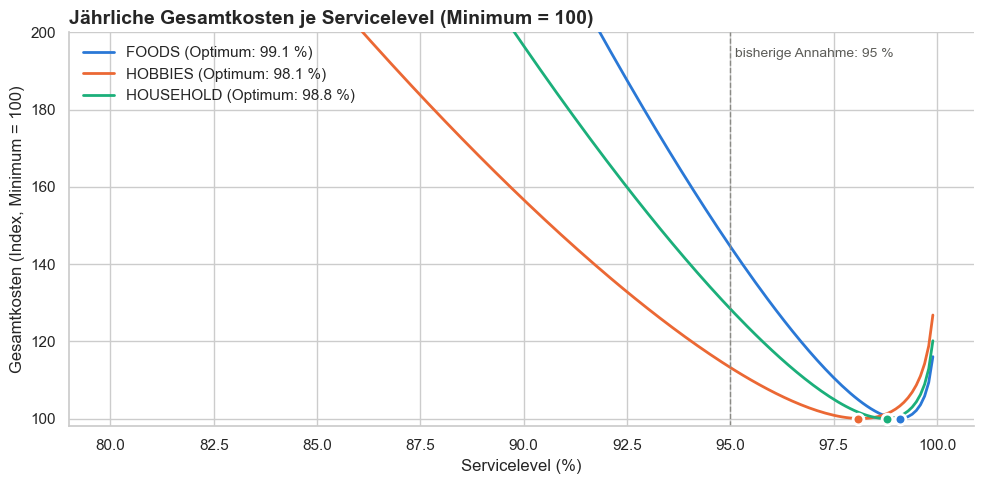

In [162]:
# Visualisierung: Gesamtkosten in Abhängigkeit vom Servicelevel

farben = ["#2a78d6", "#eb6834", "#1baf7a"]

fig, ax = plt.subplots(figsize=(10, 5))

for farbe, kategorie in zip(farben, kategorien):
    relative_kosten = kostenkurven[kategorie] / kostenkurven[kategorie].min() * 100
    optimum = servicelevel_optimum.loc[kategorie, "Optimaler Servicelevel (%)"]
    ax.plot(servicelevel_raster * 100, relative_kosten, color=farbe, linewidth=2,
            label=f"{kategorie} (Optimum: {optimum:.1f} %)")
    ax.scatter(optimum, 100, color=farbe, s=60, zorder=3,
               edgecolor="white", linewidth=2)

ax.axvline(95, color="#8a8a85", linewidth=1, linestyle="--")
ax.text(95.1, 196, "bisherige Annahme: 95 %", fontsize=10, color="#5c5c58", va="top")

ax.set_title("Jährliche Gesamtkosten je Servicelevel (Minimum = 100)",
             fontsize=14, fontweight="bold", loc="left")
ax.set_xlabel("Servicelevel (%)")
ax.set_ylabel("Gesamtkosten (Index, Minimum = 100)")
ax.set_ylim(98, 200)
ax.legend(frameon=False, loc="upper left")
sns.despine(ax=ax)

plt.tight_layout()
fig.savefig("reports/servicelevel_optimierung.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** Der kostenoptimale Servicelevel liegt in allen Kategorien **deutlich über
den bisher angenommenen 95 %**:

- **FOODS:** 99,1 % – Kosten 30,8 % niedriger als bei 95 %
- **HOUSEHOLD:** 98,8 % – Kosten 22,1 % niedriger
- **HOBBIES:** 98,1 % – Kosten 11,7 % niedriger

Über alle Kategorien sinken die jährlichen Kosten für Sicherheitsbestand und Fehlmengen
von rund 18.985 USD auf 14.101 USD (**−25,7 %**).

Grund ist das Kostenverhältnis: Eine fehlende Einheit kostet 30 % des Verkaufspreises
an entgangener Marge, die Lagerung derselben Einheit nur 20 % des Preises **pro Jahr**.
Ein zusätzlicher Sicherheitsbestand ist daher günstiger als eine Fehlmenge. Bei FOODS ist
der Effekt am stärksten, da hier am häufigsten bestellt wird und damit die meisten
Bestellzyklen ein Fehlmengenrisiko tragen.

Die Ergebnisse hängen von den angenommenen Kostensätzen ab und sollten in der Praxis
mit realen Werten aus Controlling und Logistik überprüft werden.

### 9.7 Fazit der Bestandsoptimierung

Auf Grundlage der Absatzprognosen wurde eine simulationsbasierte
Bestandsplanung auf aggregierter Ebene und je Produktkategorie durchgeführt.

Unter der Annahme einer konstanten Lieferzeit von sieben Tagen
und eines angestrebten Servicelevels von 95 % ergeben sich
folgende Bestandskennzahlen:

- Durchschnittlicher Tagesbedarf: 41.342 Einheiten
- Bedarf während der Lieferzeit: 289.394 Einheiten
- Sicherheitsbestand: 11.788 Einheiten
- Meldebestand: 301.182 Einheiten

Die Sensitivitätsanalyse zeigt, dass ein höheres angestrebtes
Servicelevel einen höheren Sicherheitsbestand erfordert.

Bei einem Servicelevel von 90 % beträgt der Sicherheitsbestand
9.187 Einheiten, während bei 99 % bereits 16.668 Einheiten
benötigt werden.

Die Erweiterungen liefern drei zentrale Ergebnisse:

- **Risk Pooling:** Die Planung je Kategorie erfordert 19,8 % mehr Sicherheitsbestand
  als die aggregierte Planung. Eine zu grobe Planungsebene unterschätzt den Bedarf.
- **Bestellmengen:** FOODS sollte etwa alle 5 Tage, HOUSEHOLD alle 7 Tage und
  HOBBIES alle 10 Tage bestellt werden.
- **Servicelevel:** Kostenoptimal sind 98,1–99,1 % statt pauschal 95 %. Dadurch sinken
  die Kosten für Sicherheitsbestand und Fehlmengen um rund 26 %.

**Einschränkungen:**

Die Kostensätze für Lagerhaltung, Bestellung und Fehlmengen beruhen auf Annahmen.
Die Kategorieprognosen werden top-down aus der Gesamtprognose abgeleitet.

Die Ergebnisse beruhen auf vereinfachten Annahmen zu
Lieferzeit, Prognosefehlern und Servicelevel.

Insbesondere werden unabhängige Prognosefehler angenommen.
Diese Annahme wurde nicht empirisch überprüft.

Da keine tatsächlichen Lagerbestände, Kosten- oder Fehlmengendaten
vorliegen, zeigen die Ergebnisse das methodische Vorgehen und ersetzen
keine realen Bestellentscheidungen.

Die Ergebnisse dienen daher als transparente Simulation
und als Grundlage für das anschließende Reporting.

## 10. Excel Reporting

Ziel dieses Kapitels ist die Erstellung eines übersichtlichen
Excel-Reports mit den wichtigsten Ergebnissen der Absatzprognose
und der simulationsbasierten Bestandsplanung.

Der Report umfasst:

- Tägliche Ist- und Prognosewerte der Testperiode
- Vergleich der Prognosemodelle anhand von MAE und RMSE
- Bestandskennzahlen für das angenommene Servicelevel von 95 %
- Sensitivitätsanalyse für unterschiedliche Servicelevel

Die Ergebnisse werden in separaten Excel-Tabellenblättern
aufbereitet, um eine einfache Weiterverwendung und
Visualisierung zu ermöglichen.

Die Tabellen werden mit einheitlichen Überschriften, Zahlenformaten und
Filterfunktionen exportiert. Anschließend wird die Datei erneut eingelesen
und auf Vollständigkeit geprüft.

In [166]:
# Reporting-Daten für den Excel-Export vorbereiten

# 1. Tägliche Prognosen der Testperiode
report_prognosen = pd.DataFrame({
    "Datum": test_df["datum"].to_numpy(),
    "Ist-Absatz": y_test,
    "Seasonal Naive": baseline_test_pred,
    "Gradient Boosting": ml_test_pred
})

report_prognosen["Absoluter Fehler GB"] = np.abs(
    report_prognosen["Ist-Absatz"]
    - report_prognosen["Gradient Boosting"]
)

# 2. Modellvergleich
report_modelle = ergebnisse_test.copy()

# 3. Bestandskennzahlen
report_bestand = pd.DataFrame({
    "Kennzahl": [
        "Lieferzeit (Tage)",
        "Angestrebtes Servicelevel (%)",
        "Durchschnittlicher Tagesbedarf",
        "Bedarf während der Lieferzeit",
        "Standardabweichung der Prognosefehler",
        "Sicherheitsbestand",
        "Meldebestand"
    ],
    "Wert": [
        lieferzeit_tage,
        servicelevel * 100,
        durchschnittlicher_tagesbedarf,
        bedarf_lieferzeit,
        prognosefehler_std,
        np.ceil(sicherheitsbestand),
        np.ceil(meldebestand)
    ]
})

# 4. Servicelevel-Szenarien
report_szenarien = szenario_df.copy()

# Überprüfung der Reporting-Tabellen
print("Reporting-Daten vorbereitet:")
print("Prognosen:", report_prognosen.shape)
print("Modellvergleich:", report_modelle.shape)
print("Bestandskennzahlen:", report_bestand.shape)
print("Servicelevel-Szenarien:", report_szenarien.shape)

display(report_prognosen.head())

Reporting-Daten vorbereitet:
Prognosen: (93, 5)
Modellvergleich: (2, 3)
Bestandskennzahlen: (7, 2)
Servicelevel-Szenarien: (3, 3)


,Datum,Ist-Absatz,Seasonal Naive,Gradient Boosting,Absoluter Fehler GB
0,2016-02-20,50857,53715.0,50393.959443,463.040557
1,2016-02-21,52081,48337.0,48476.689976,3604.310024
2,2016-02-22,37328,46152.0,38936.151381,1608.151381
3,2016-02-23,33981,37702.0,34767.513283,786.513283
4,2016-02-24,34068,36545.0,35159.671057,1091.671057


In [167]:
# Excel-Report erstellen und formatieren

from pathlib import Path
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

# Ausgabeverzeichnis
output_dir = Path("reports")
output_dir.mkdir(exist_ok=True)

excel_datei = output_dir / "supply_chain_report.xlsx"

# Ein bestehender Report (inkl. manuell erstelltem Dashboard) wird nicht überschrieben.
# Für einen neuen Export REPORT_NEU_ERSTELLEN auf True setzen.
REPORT_NEU_ERSTELLEN = False

if excel_datei.exists() and not REPORT_NEU_ERSTELLEN:

    print("Excel-Report bereits vorhanden – Export und Prüfung übersprungen.")
    print("Dateipfad:", excel_datei.as_posix())

else:

    # Arbeitsmappe erstellen
    wb = Workbook()
    wb.remove(wb.active)

    report_tabellen = {
        "Prognosen": report_prognosen,
        "Modellvergleich": report_modelle,
        "Bestandskennzahlen": report_bestand,
        "Servicelevel-Szenarien": report_szenarien
    }

    for tabellenname, df in report_tabellen.items():

        ws = wb.create_sheet(tabellenname)

        # Spaltenüberschriften
        ws.append(list(df.columns))

        # Daten einfügen
        for zeile in df.itertuples(index=False, name=None):
            ws.append(list(zeile))

        # Überschriften formatieren
        for zelle in ws[1]:
            zelle.font = Font(
                bold=True,
                color="FFFFFF"
            )
            zelle.fill = PatternFill(
                fill_type="solid",
                fgColor="17365D"
            )
            zelle.alignment = Alignment(horizontal="center")

        # Zahlen- und Datumsformate
        for zeile in ws.iter_rows(min_row=2):
            for zelle in zeile:

                if zelle.column == 1 and tabellenname == "Prognosen":
                    zelle.number_format = "DD.MM.YYYY"

                elif isinstance(zelle.value, (int, float)):
                    zelle.number_format = '#,##0.00'

        # Spaltenbreiten begrenzen
        for spalte in ws.columns:
            spaltenbuchstabe = get_column_letter(spalte[0].column)

            maximale_laenge = max(
                len(str(zelle.value)) if zelle.value is not None else 0
                for zelle in spalte
            )

            ws.column_dimensions[spaltenbuchstabe].width = min(
                maximale_laenge + 3,
                38
            )

        # Filter und fixierte Überschriften
        ws.auto_filter.ref = ws.dimensions
        ws.freeze_panes = "A2"

    # Excel-Datei speichern
    wb.save(excel_datei)

    print("Excel-Report erfolgreich erstellt.")
    print("Dateipfad:", excel_datei.as_posix())
    print("Tabellenblätter:", ", ".join(wb.sheetnames))

    # Excel-Report auf Vollständigkeit überprüfen

    from openpyxl import load_workbook

    wb_pruefung = load_workbook(excel_datei, read_only=True)

    erwartete_zeilen = {
        "Prognosen": 93,
        "Modellvergleich": 2,
        "Bestandskennzahlen": 7,
        "Servicelevel-Szenarien": 3
    }

    alle_pruefungen_ok = True

    for tabellenname, erwartete_anzahl in erwartete_zeilen.items():

        ws = wb_pruefung[tabellenname]

        # Erste Zeile enthält die Spaltenüberschriften
        daten_zeilen = ws.max_row - 1

        status = daten_zeilen == erwartete_anzahl
        alle_pruefungen_ok &= status

        print(
            f"{tabellenname}: {daten_zeilen} Datenzeilen "
            f"| Prüfung: {'OK' if status else 'FEHLER'}"
        )

    wb_pruefung.close()

    print("\nGesamtprüfung:", "BESTANDEN" if alle_pruefungen_ok else "FEHLGESCHLAGEN")

Excel-Report bereits vorhanden – Export und Prüfung übersprungen.
Dateipfad: reports/supply_chain_report.xlsx
